# PiMoTIF — simulation and validation code

This notebook implements the **trajectory simulation part** of the PiMoTIF plan:
1. measure simulation parameters from the NB fixed/live data;
2. generate five motion classes with experimental recording effects;
3. validate simulated immobile tracks against fixed-cell tracks;
4. estimate how often the existing sRg cutoff misclassifies simulated moving tracks;
5. check sensitivity to the random seed.

It does **not** train the feature-based, deep-learning, or hybrid classifiers. Those belong in the next stage after the simulation passes validation.

The notebook uses real NB data for parameter pools and blinking patterns. Update `ROOT` in the setup cell if the lab data are stored elsewhere.

In [1]:
# %matplotlib inline
import gc
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from scipy import stats
from tqdm.auto import tqdm

ROOT  = Path(r"Z:/Lab/Jagriti/DATA_EXTRACTED/ALL_FOVS")
OUT   = ROOT / "ML" / "ML_Analysis" / "simulations"
FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
CACHE = Path.home() / ".pimotif_cache"      # the parquets live on the lab share;
                                            # reading them over the network is
                                            # the slowest thing here, so copy once
for d in (OUT, FIG_DIR, TAB_DIR, CACHE):
    d.mkdir(parents=True, exist_ok=True)

# --- NB only -----------------------------------------------------------------
DONOR_FIX  = ["NB-Fix", "NB-Fix_Iono"]   # nothing moves: the immobile donors
DONOR_LIVE = ["NB-Live"]                 # the mobile donors

# --- my microscope, as I actually imaged -------------------------------------
PX_UM, DT_S, N_FRAMES = 0.1082, 0.005, 6000     # 108.2 nm, 5 ms, 30 s
MOVIE_S       = N_FRAMES * DT_S   # 30 s. A movie is a DURATION; the number of
                                  # frames in it follows from the frame time
MIN_TRACK_LEN = 200               # my upstream filter, applied to the real data
MIN_SIM_DET   = 10                # a simulated track may be this short, so the
                                  # library covers short noisy trajectories too

# Blinking itself is MEASURED, not modelled: every simulated track inherits a
# real track's frame pattern. This is something else - it decides whether a
# PARTIAL frame yields a detection when I simulate slower imaging than my own.
EXPOSURE_RANGE = (0.3, 0.7)  # ASSUMED. What really decides it is photon count
                             # against the finder's threshold, and I took
                             # intensity out. At 5 ms it never fires.

# --- deliberate coverage, so the model survives other experiments ------------
DT_RANGE  = (0.005, 0.100)
DT_BANDS  = [(0.005, 0.010), (0.010, 0.040), (0.040, 0.100)]   # s
LEN_BANDS = [(10, 50), (50, 200), (200, 6000)]                 # detections

SIGMA_RANGE   = (0.015, 0.080)   # um   localisation error
DUTY_RANGE    = (0.2, 1.0)       #      blinking
DRIFT_SCALE   = (0.5, 3.0)       # x my measured drift
D_SCALE       = (0.3, 3.0)       # x my measured mobile D
CORRAL_SCALE  = (0.5, 3.0)       # x my measured corral radii
DENSITY_RANGE = (0.005, 0.80)    # puncta/um2, drawn log-uniform
UNRESOLVED    = (0.005, 0.25)    # the library's range; the floor sits below my
                                 # measured ~0.8% so the library contains it
R_LINK        = 3 * PX_UM        # 325 nm: my tracker's jump limit. A property
                                 # of the software, so it gets no range

# --- the five motion types ---------------------------------------------------
ALPHA_RANGE   = (0.3, 0.9)       # restricted: subdiffusive exponent
LATTICE_NM    = (20.0, 60.0)     # restricted: obstacle spacing. ASSUMED -
                                 # single-particle tracking cannot see this
OBSTACLE_CONC = (0.20, 0.45)     # restricted: fraction of sites blocked
DIRECTEDNESS  = (1.0, 6.0)       # directed: v^2 T / 4D
D_IMMOBILE    = (1e-9, 1.2e-3)   # um2/s, two residual-mobility populations

ASPECT_CUT    = 3.0              # longer than this and I call a track stretched
OUTLIER_FRAC, OUTLIER_SCALE = 0.02, 3.0    # a few localisations are badly wrong
WANDER_FRAC   = 0.5              # how much of the drift wanders vs ramps
PSF_R         = 0.25             # um: closer than this and two spots are one

N_PER_CELL, N_REF, N_REF_FIX, SEED = 120, 600, 3000, 0
CLASSES = ["normal", "restricted", "corralled", "directed", "immobile"]
COL = {"normal": "#1d4ed8", "restricted": "#0f766e", "corralled": "#7c3aed",
       "directed": "#b45309", "immobile": "#c81e1e"}
C_FIX, C_LIVE, C_SIM = "#64748b", "#1d4ed8", "#b45309"
SQ = np.sqrt(np.pi / 2)

mpl.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 17, "axes.titleweight": "bold",
    "axes.labelsize": 15, "axes.labelweight": "bold",
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 12, "axes.linewidth": 1.5,
    "figure.titlesize": 21, "figure.titleweight": "bold",
    "savefig.dpi": 130, "figure.facecolor": "white",
    "lines.linewidth": 2.4,
})

def bold_ticks(*axes):
    """matplotlib has no rcParam for tick-label weight, so set it by hand"""
    for ax in axes:
        for t in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
            t.set_fontweight("bold")

rng_global = np.random.default_rng(SEED)
print("backend:", mpl.get_backend())
print(f"movie {MOVIE_S:.0f} s | {N_FRAMES} frames at {1000*DT_S:.0f} ms | "
      f"pixel {1000*PX_UM:.1f} nm")
print(f"classes: {CLASSES}")

backend: module://matplotlib_inline.backend_inline
movie 30 s | 6000 frames at 5 ms | pixel 108.2 nm
classes: ['normal', 'restricted', 'corralled', 'directed', 'immobile']


## 1. What I measure from my own NB data

| what | where it comes from |
|---|---|
| localisation error | fixed cells — nothing moves, so every step is pure error |
| blinking and track length | the frame pattern of every real track |
| stage drift | how far long-lived tracks shift across a movie |
| diffusion coefficient | the MSD of the mobile live tracks |
| corral radius | live tracks whose MSD rises and then flattens |
| density | detections per frame over the area the molecules cover |

Each simulated track borrows a real track's **frame pattern** — which frames
the molecule was visible in, nothing else. No positions, no intensity. So the
gaps and the lengths are my dye's real behaviour rather than a model of it.

Three things I cannot measure, and say so: the detection threshold, the
obstacle spacing, and whether localisation error holds at slower frame rates.

In [2]:
def load(conditions, what=""):
    """Load tracks while making field and track IDs unique across source files.

    The raw track_gid/fov_uid values may be reused in different conditions or
    fields. Prefixing them here prevents unrelated tracks from being merged
    by later groupby operations.
    """
    out = []
    for c in tqdm(conditions, desc=f"loading {what}", leave=False):
        local = CACHE / f"{c}_tracks.parquet"
        if not local.exists():
            src = ROOT / "combined" / f"{c}_tracks.parquet"
            tqdm.write(f"   copying {c} ({src.stat().st_size/1e6:.0f} MB) once")
            shutil.copy2(src, local)

        d = pd.read_parquet(local, columns=[
            "fov_uid", "track_gid", "frame", "x_um", "y_um", "intensity"])

        # Raw ids repeat between conditions, so a track is identified by the
        # condition, the field and its own id together. Kept as a category: the
        # readable key costs a few bytes per row rather than a Python string,
        # and these tables run to millions of rows.
        d["track_uid"] = (str(c) + "::" + d.fov_uid.astype(str) + "::"
                          + d.track_gid.astype(str)).astype("category")
        d["fov_uid"] = (str(c) + "::" + d.fov_uid.astype(str)).astype("category")
        out.append(d)

    if not out:
        raise ValueError(f"No conditions supplied while loading {what!r}")

    d = pd.concat(out, ignore_index=True)
    # track_gid becomes a NUMBER again. Two tracks share one only if they
    # shared a condition, a field and a raw id, so the identity is exactly the
    # one the unique key gives - but the boundary-finding code throughout this
    # notebook locates tracks with np.diff on a sorted array, which needs
    # arithmetic.
    d["track_gid"] = pd.factorize(d.track_uid, sort=True)[0].astype(np.int64)
    d["frame"] = d.frame.astype(np.int32)
    return d.sort_values(["track_gid", "frame"]).reset_index(drop=True)


real_fix  = load(DONOR_FIX,  "fixed")
real_live = load(DONOR_LIVE, "live")

for name, d in [("fixed", real_fix), ("live", real_live)]:
    n = d.groupby("track_gid").size()
    print(f"{name:5s}  {d.track_gid.nunique():,} tracks | "
          f"{d.fov_uid.nunique()} fields | {len(d):,} detections | "
          f"length median {n.median():.0f}, range {n.min()}-{n.max()}")

loading fixed:   0%|          | 0/2 [00:00<?, ?it/s]

loading live:   0%|          | 0/1 [00:00<?, ?it/s]

fixed  3,025 tracks | 53 fields | 4,355,453 detections | length median 807, range 200-6000


live   2,392 tracks | 27 fields | 1,974,052 detections | length median 458, range 200-5983


C:\Users\chatt\AppData\Local\Temp\ipykernel_38056\1037720672.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ax.hist(d.groupby("fov_uid").track_gid.nunique(), bins=25,


C:\Users\chatt\AppData\Local\Temp\ipykernel_38056\1037720672.py:32: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pf = (d.groupby(["fov_uid", "frame"]).size().groupby("frame").mean()


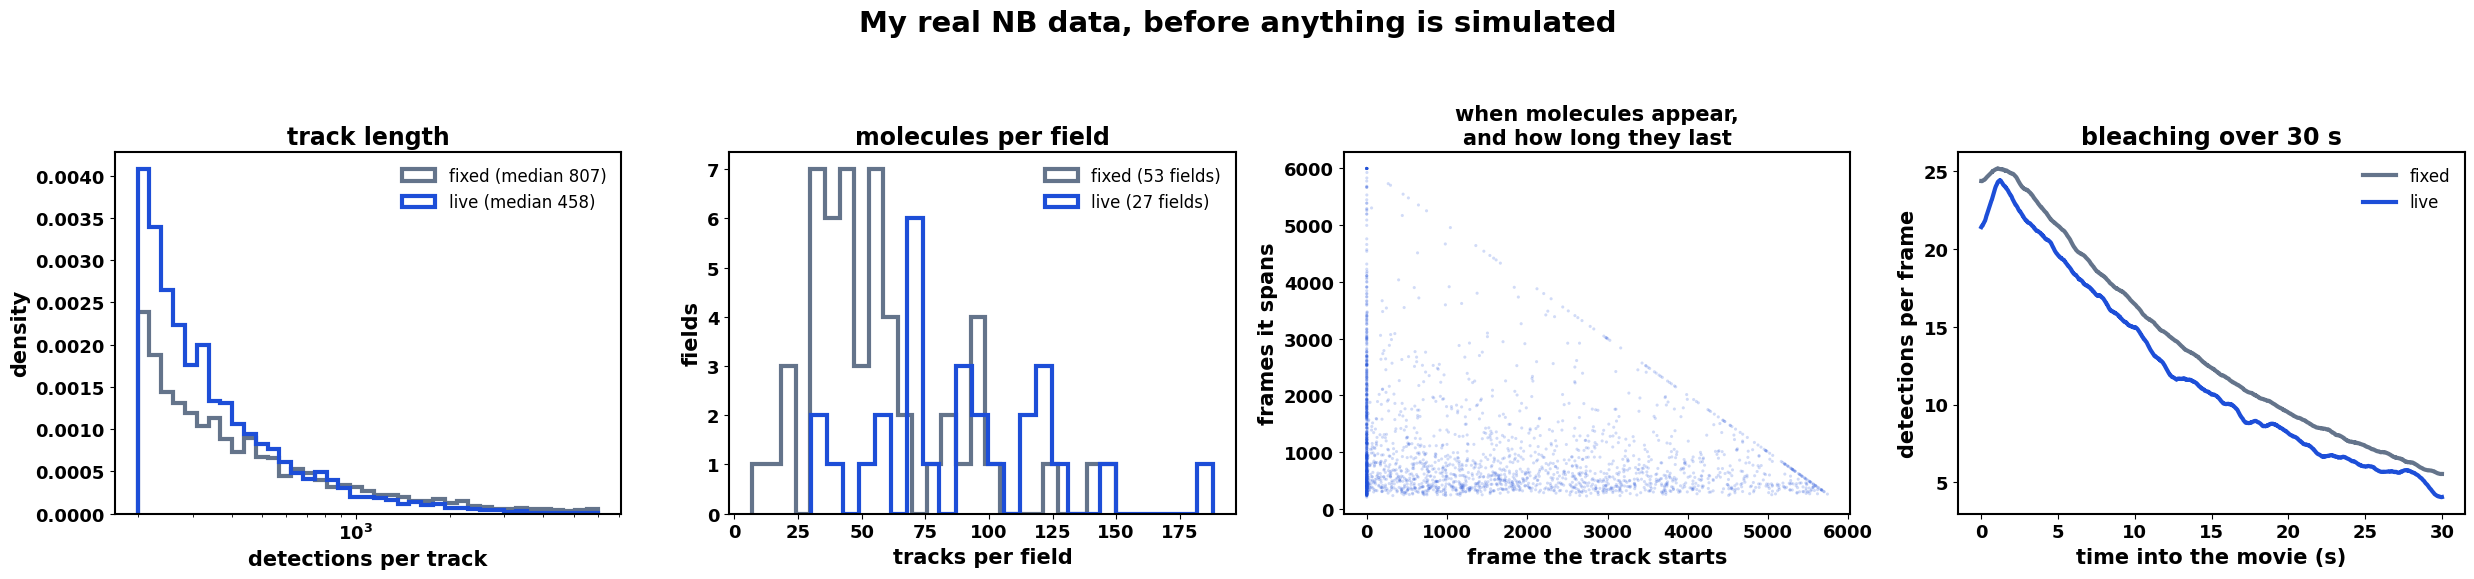

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))

ax = axes[0]
bins = np.logspace(np.log10(200), np.log10(6000), 40)
for d, c, lab in [(real_fix, C_FIX, "fixed"), (real_live, C_LIVE, "live")]:
    n = d.groupby("track_gid").size()
    ax.hist(n, bins=bins, density=True, histtype="step", lw=3, color=c,
            label=f"{lab} (median {n.median():.0f})")
ax.set_xscale("log")
ax.set_xlabel("detections per track"); ax.set_ylabel("density")
ax.set_title("track length")
ax.legend(frameon=False)

ax = axes[1]
for d, c, lab in [(real_fix, C_FIX, "fixed"), (real_live, C_LIVE, "live")]:
    ax.hist(d.groupby("fov_uid").track_gid.nunique(), bins=25,
            histtype="step", lw=3, color=c,
            label=f"{lab} ({d.fov_uid.nunique()} fields)")
ax.set_xlabel("tracks per field"); ax.set_ylabel("fields")
ax.set_title("molecules per field")
ax.legend(frameon=False)

ax = axes[2]
g = real_live.groupby("track_gid").frame.agg(["min", "max"])
ax.scatter(g["min"], g["max"] - g["min"] + 1, s=5, alpha=.2, color=C_LIVE,
           edgecolors="none")
ax.set_xlabel("frame the track starts"); ax.set_ylabel("frames it spans")
ax.set_title("when molecules appear,\nand how long they last", fontsize=15)

ax = axes[3]
for d, c, lab in [(real_fix, C_FIX, "fixed"), (real_live, C_LIVE, "live")]:
    pf = (d.groupby(["fov_uid", "frame"]).size().groupby("frame").mean()
          .sort_index())
    sm = pf.rolling(100, center=True, min_periods=20).mean()
    ax.plot(sm.index * DT_S, sm.to_numpy(), lw=3, color=c, label=lab)
ax.set_xlabel("time into the movie (s)"); ax.set_ylabel("detections per frame")
ax.set_title("bleaching over 30 s")
ax.legend(frameon=False)

bold_ticks(*axes)
fig.suptitle("My real NB data, before anything is simulated", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M0_real_data_overview.png", bbox_inches="tight")

### Localisation error

A molecule glued to the coverslip still appears to take a step every frame,
and that step is entirely error. In 2D the mean squared step is 4σ², so
σ = √(⟨step²⟩/4). Only gap-free steps count — a step across a blink spans more
time and would let slow stage drift leak in.

In [4]:
def sigma_per_track(d, min_steps=10):
    """Localisation error per track, from gap-free steps in fixed cells."""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    d2 = ((P[1:] - P[:-1]) ** 2).sum(1)
    ok = (tid[1:] == tid[:-1]) & (np.diff(fr) == 1)
    S = (pd.DataFrame({"track_gid": tid[1:][ok], "d2": d2[ok]})
         .groupby("track_gid").d2.agg(mean_d2="mean", n_steps="size"))
    S = S[S.n_steps >= min_steps]
    S["sigma_um"] = np.sqrt(S.mean_d2 / 4)
    meta = d.groupby("track_gid").agg(fov_uid=("fov_uid", "first"),
                                      n_det=("frame", "size"),
                                      intensity=("intensity", "mean"))
    return S.join(meta).reset_index()

SIG_TAB = sigma_per_track(real_fix)
SIGMA   = SIG_TAB.sigma_um.to_numpy()

print(f"localisation error: median {1000*np.median(SIGMA):.1f} nm")
print(f"   5-95th  {1000*np.quantile(SIGMA,.05):.1f}-"
      f"{1000*np.quantile(SIGMA,.95):.1f} nm")
print(f"   full    {1000*SIGMA.min():.1f}-{1000*SIGMA.max():.1f} nm "
      f"(n={len(SIGMA):,})")
print(f"   library {1000*SIGMA_RANGE[0]:.0f}-{1000*SIGMA_RANGE[1]:.0f} nm")
print(f"   outside the library range: "
      f"{100*((SIGMA<SIGMA_RANGE[0])|(SIGMA>SIGMA_RANGE[1])).mean():.2f}%")

localisation error: median 40.0 nm
   5-95th  23.0-60.1 nm
   full    11.3-95.2 nm (n=3,025)
   library 15-80 nm
   outside the library range: 0.56%


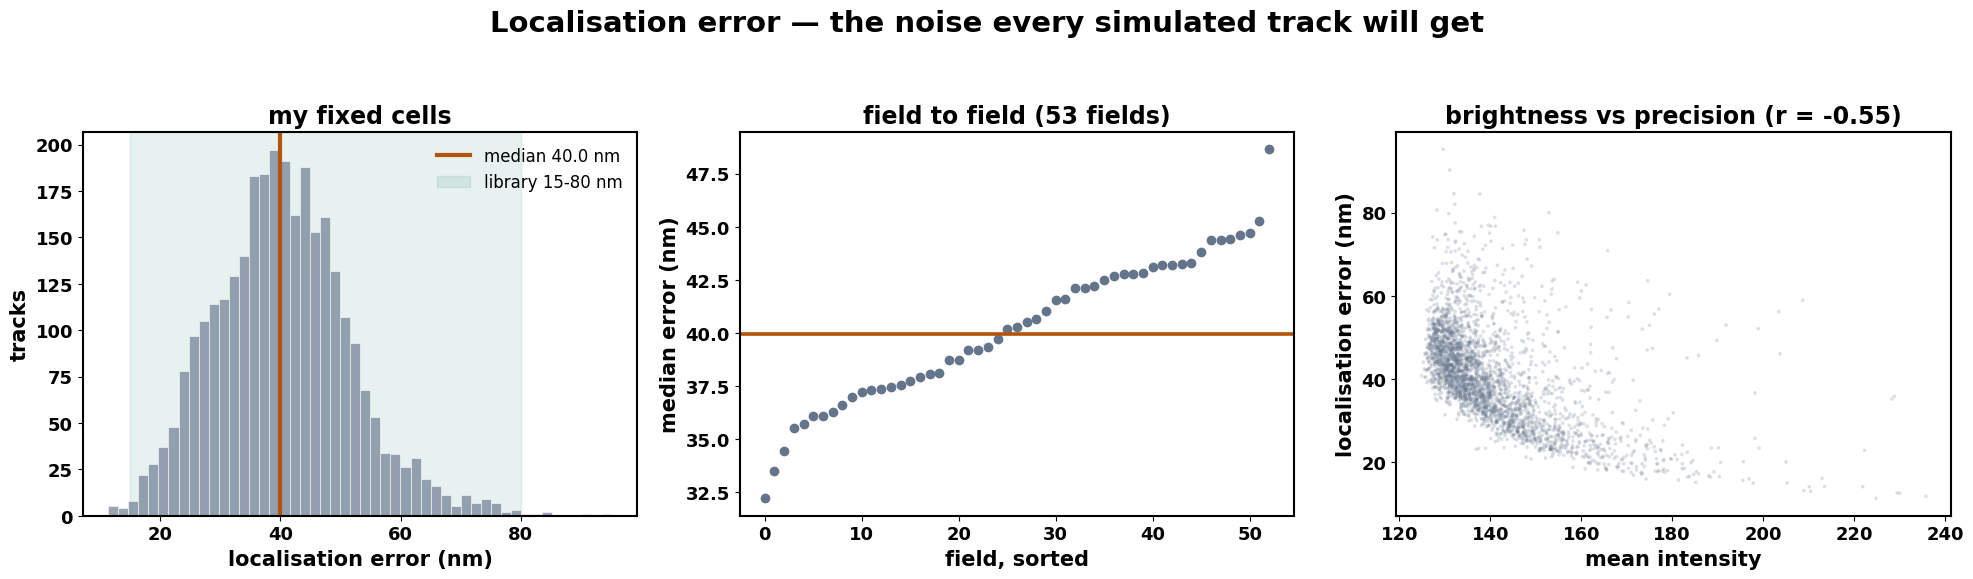

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.6))

ax = axes[0]
ax.hist(1000 * SIGMA, bins=50, color=C_FIX, alpha=.65, edgecolor="white", lw=.6)
ax.axvline(1000 * np.median(SIGMA), color="#b45309", lw=3,
           label=f"median {1000*np.median(SIGMA):.1f} nm")
ax.axvspan(1000 * SIGMA_RANGE[0], 1000 * SIGMA_RANGE[1], color="#0f766e",
           alpha=.10, zorder=0, label="library 15-80 nm")
ax.set_xlabel("localisation error (nm)"); ax.set_ylabel("tracks")
ax.set_title("my fixed cells")
ax.legend(frameon=False)

ax = axes[1]
pf = SIG_TAB.groupby("fov_uid").sigma_um.median().sort_values() * 1000
ax.plot(np.arange(len(pf)), pf.to_numpy(), "o", ms=6, color=C_FIX)
ax.axhline(1000 * np.median(SIGMA), color="#b45309", lw=2.6)
ax.set_xlabel("field, sorted"); ax.set_ylabel("median error (nm)")
ax.set_title(f"field to field ({len(pf)} fields)")

ax = axes[2]
ax.scatter(SIG_TAB.intensity, 1000 * SIG_TAB.sigma_um, s=7, alpha=.22,
           color=C_FIX, edgecolors="none")
r = SIG_TAB[["intensity", "sigma_um"]].corr().iloc[0, 1]
ax.set_xlabel("mean intensity"); ax.set_ylabel("localisation error (nm)")
ax.set_title(f"brightness vs precision (r = {r:.2f})")

bold_ticks(*axes)
fig.suptitle("Localisation error — the noise every simulated track will get",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M1_localisation_error.png", bbox_inches="tight")

### Blinking — measured, not modelled

Every simulated track inherits a real track's on/off pattern. I never generate
blinking; I only ever *thin* a real pattern to make a molecule blink more.
Adding a detection where the real molecule was dark would be inventing
photophysics I have not observed.

In [6]:
def donors_of(d, desc="donors"):
    """one row per real track, plus its frame pattern as offsets from its start"""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    cuts = np.flatnonzero(np.diff(tid)) + 1
    starts = np.concatenate([[0], cuts])
    ends   = np.concatenate([cuts, [len(tid)]])
    rows, patterns, gaps = [], [], []
    for s, e in tqdm(zip(starts, ends), total=len(starts), desc=desc):
        f = fr[s:e]
        span = int(f[-1] - f[0] + 1)
        rows.append({"track_gid": tid[s], "n_det": e - s, "span": span,
                     "duty": (e - s) / span, "f0": int(f[0])})
        patterns.append((f - f[0]).astype(np.int32))
        g = np.diff(f) - 1
        gaps.append(g[g > 0])
    return (pd.DataFrame(rows), patterns,
            np.concatenate(gaps) if gaps else np.array([]))

FIX,  PAT_FIX,  GAP_FIX  = donors_of(real_fix,  "fixed donors")
LIVE, PAT_LIVE, GAP_LIVE = donors_of(real_live, "live donors")

for name, T, G in [("fixed", FIX, GAP_FIX), ("live", LIVE, GAP_LIVE)]:
    print(f"{name:5s}  duty median {T.duty.median():.3f}  "
          f"5-95th {T.duty.quantile(.05):.3f}-{T.duty.quantile(.95):.3f}  "
          f"min {T.duty.min():.3f}")
    print(f"       dark stretches: median {np.median(G):.0f} frames, "
          f"95th {np.quantile(G,.95):.0f}, longest {G.max()} "
          f"(my tracker gives up after 19)")
print(f"library duty range: {DUTY_RANGE[0]}-{DUTY_RANGE[1]}")

fixed donors:   0%|          | 0/3025 [00:00<?, ?it/s]

live donors:   0%|          | 0/2392 [00:00<?, ?it/s]

fixed  duty median 0.714  5-95th 0.292-0.998  min 0.199
       dark stretches: median 1 frames, 95th 6, longest 18 (my tracker gives up after 19)
live   duty median 0.759  5-95th 0.434-0.960  min 0.241
       dark stretches: median 1 frames, 95th 6, longest 18 (my tracker gives up after 19)
library duty range: 0.2-1.0


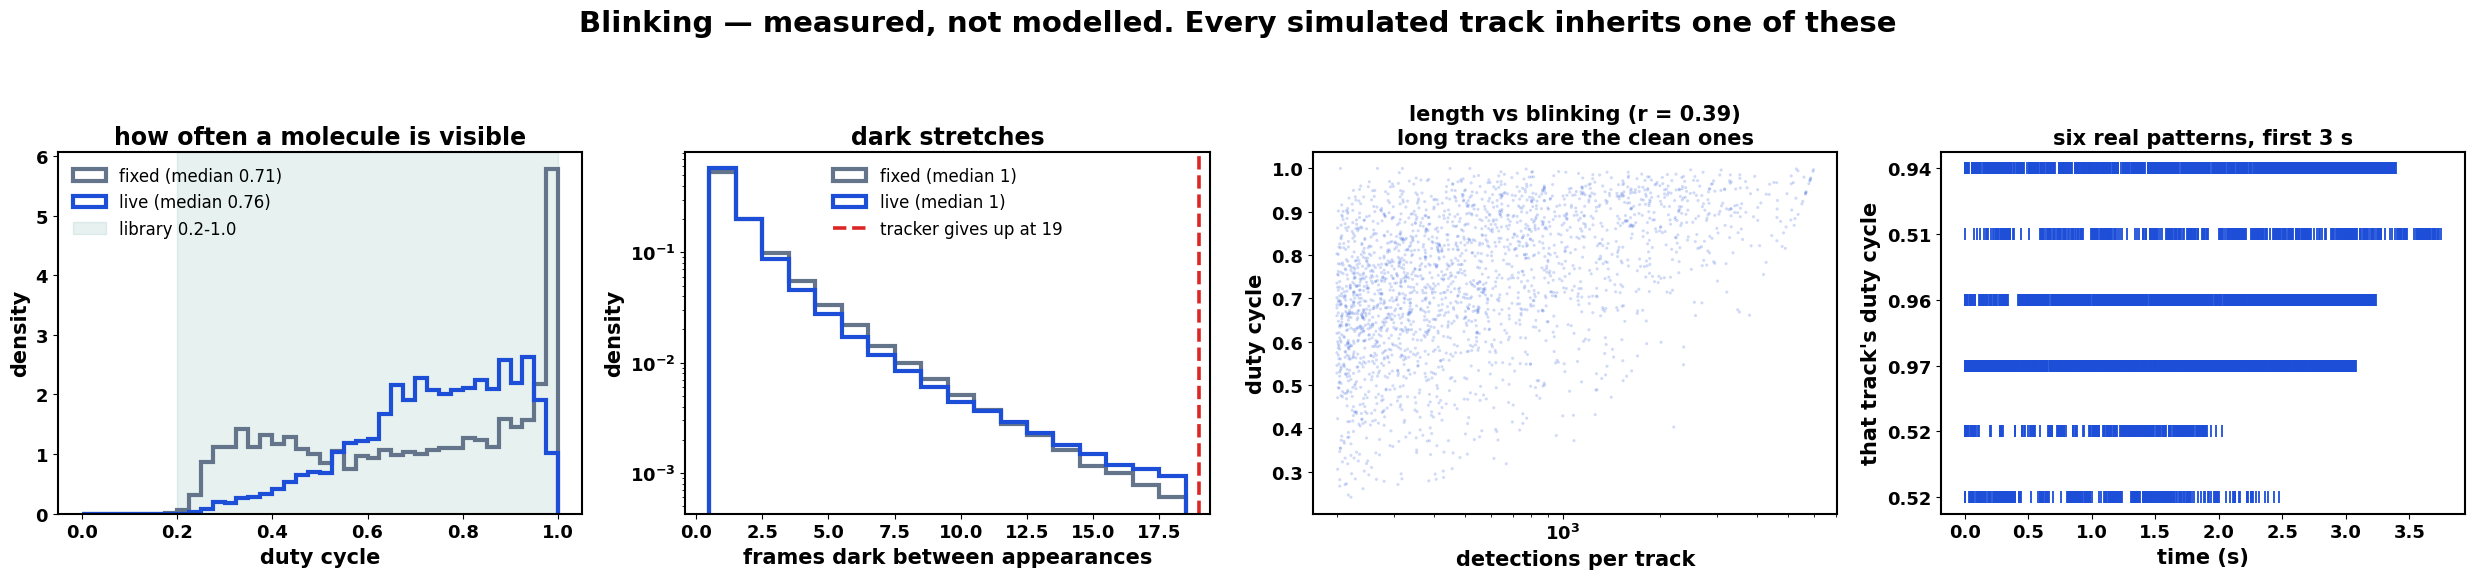

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))

ax = axes[0]
bins = np.linspace(0, 1, 41)
for T, c, lab in [(FIX, C_FIX, "fixed"), (LIVE, C_LIVE, "live")]:
    ax.hist(T.duty, bins=bins, density=True, histtype="step", lw=3, color=c,
            label=f"{lab} (median {T.duty.median():.2f})")
ax.axvspan(*DUTY_RANGE, color="#0f766e", alpha=.10, zorder=0,
           label=f"library {DUTY_RANGE[0]}-{DUTY_RANGE[1]}")
ax.set_xlabel("duty cycle"); ax.set_ylabel("density")
ax.set_title("how often a molecule is visible")
ax.legend(frameon=False)

ax = axes[1]
mx = int(max(GAP_FIX.max(), GAP_LIVE.max()))
for G, c, lab in [(GAP_FIX, C_FIX, "fixed"), (GAP_LIVE, C_LIVE, "live")]:
    ax.hist(G, bins=np.arange(.5, mx + 1.5), density=True, histtype="step",
            lw=3, color=c, label=f"{lab} (median {np.median(G):.0f})")
ax.axvline(19, color="#dc2626", ls="--", lw=2.6, label="tracker gives up at 19")
ax.set_yscale("log")
ax.set_xlabel("frames dark between appearances"); ax.set_ylabel("density")
ax.set_title("dark stretches")
ax.legend(frameon=False)

ax = axes[2]
ax.scatter(LIVE.n_det, LIVE.duty, s=5, alpha=.2, color=C_LIVE,
           edgecolors="none")
ax.set_xscale("log")
r = LIVE[["n_det", "duty"]].corr().iloc[0, 1]
ax.set_xlabel("detections per track"); ax.set_ylabel("duty cycle")
ax.set_title(f"length vs blinking (r = {r:.2f})\nlong tracks are the clean ones",
             fontsize=15)

ax = axes[3]
pick = rng_global.choice(len(PAT_LIVE), 6, replace=False)
for row, i in enumerate(pick):
    p = PAT_LIVE[i][:600]
    ax.plot(p * DT_S, np.full(p.size, row), "|", ms=9, color=C_LIVE, mew=1.3)
ax.set_yticks(range(6))
ax.set_yticklabels([f"{LIVE.duty.iloc[i]:.2f}" for i in pick])
ax.set_xlabel("time (s)"); ax.set_ylabel("that track's duty cycle")
ax.set_title("six real patterns, first 3 s", fontsize=15)

bold_ticks(*axes)
fig.suptitle("Blinking — measured, not modelled. Every simulated track "
             "inherits one of these", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M2_blinking.png", bbox_inches="tight")

### Stage drift

A fixed molecule should sit still, so if every molecule in a field has moved
the same way by the end, that is the stage and not the biology.

In [8]:
def drift_per_field(d, min_det_each=100):
    """median shift of long-lived tracks, first quarter of the movie to last"""
    Q, rows = N_FRAMES // 4, []
    for fov, fd in tqdm(d.groupby("fov_uid"), total=d.fov_uid.nunique(),
                        desc="drift per field"):
        dx, dy = [], []
        for _, s in fd.groupby("track_gid"):
            a, b = s[s.frame < Q], s[s.frame >= N_FRAMES - Q]
            if len(a) >= min_det_each and len(b) >= min_det_each:
                dx.append(b.x_um.mean() - a.x_um.mean())
                dy.append(b.y_um.mean() - a.y_um.mean())
        if dx:
            rows.append({"fov_uid": fov, "n_long": len(dx),
                         "dx_um": np.median(dx), "dy_um": np.median(dy),
                         "drift_um": np.median(np.hypot(dx, dy))})
    return pd.DataFrame(rows)

DRIFT_TAB = drift_per_field(real_fix)
DRIFT     = DRIFT_TAB.drift_um.to_numpy()

print(f"stage drift: median {1000*np.median(DRIFT):.1f} nm/movie, "
      f"range {1000*DRIFT.min():.0f}-{1000*DRIFT.max():.0f} nm "
      f"({len(DRIFT)} fields)")
print(f"   library x{DRIFT_SCALE[0]}-{DRIFT_SCALE[1]} -> "
      f"{1000*DRIFT_SCALE[0]*DRIFT.min():.0f}-"
      f"{1000*DRIFT_SCALE[1]*DRIFT.max():.0f} nm")
print(f"   horizontal {1000*DRIFT_TAB.dx_um.abs().median():.1f} nm vs vertical "
      f"{1000*DRIFT_TAB.dy_um.abs().median():.1f} nm - one axis, not both")
print(f"   {(DRIFT_TAB.dx_um > 0).sum()} of {len(DRIFT_TAB)} fields drift the "
      f"same way in x, so this is the stage creeping, not random wander")

drift per field:   0%|          | 0/53 [00:00<?, ?it/s]

stage drift: median 71.4 nm/movie, range 17-136 nm (52 fields)
   library x0.5-3.0 -> 8-409 nm
   horizontal 65.0 nm vs vertical 13.0 nm - one axis, not both
   46 of 52 fields drift the same way in x, so this is the stage creeping, not random wander


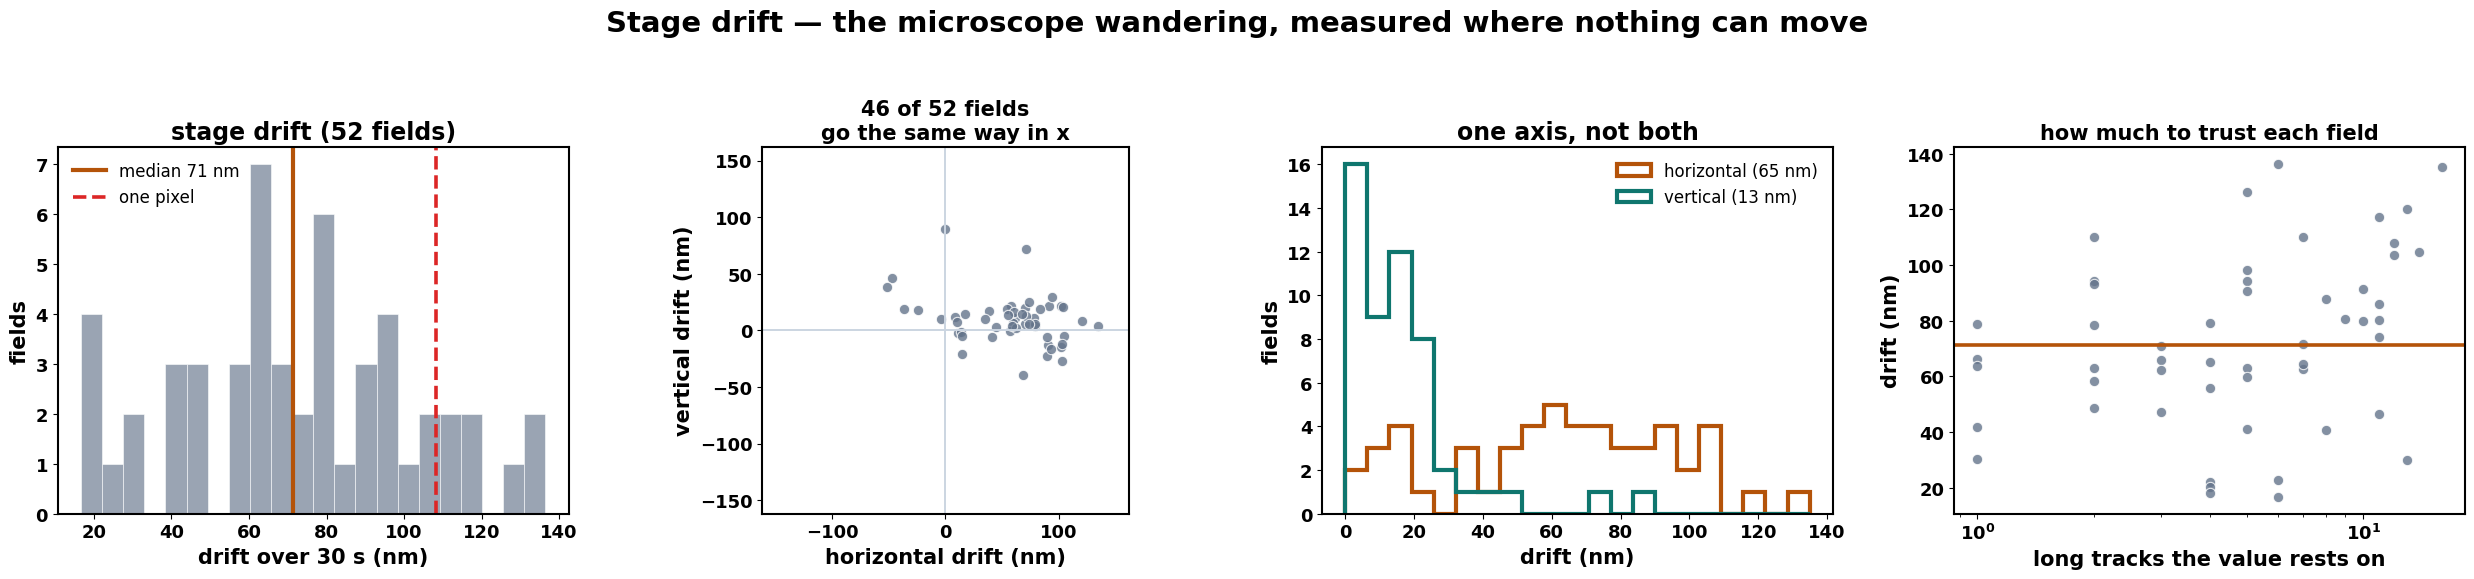

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))

ax = axes[0]
ax.hist(1000 * DRIFT, bins=22, color=C_FIX, alpha=.65, edgecolor="white", lw=.6)
ax.axvline(1000 * np.median(DRIFT), color="#b45309", lw=3,
           label=f"median {1000*np.median(DRIFT):.0f} nm")
ax.axvline(1000 * PX_UM, color="#dc2626", ls="--", lw=2.6, label="one pixel")
ax.set_xlabel("drift over 30 s (nm)"); ax.set_ylabel("fields")
ax.set_title(f"stage drift ({len(DRIFT)} fields)")
ax.legend(frameon=False)

ax = axes[1]
ax.axhline(0, color="#cbd5e1", lw=1.4); ax.axvline(0, color="#cbd5e1", lw=1.4)
ax.scatter(1000 * DRIFT_TAB.dx_um, 1000 * DRIFT_TAB.dy_um, s=55, color=C_FIX,
           alpha=.8, edgecolors="white", lw=.8)
lim = 1000 * max(DRIFT_TAB.dx_um.abs().max(), DRIFT_TAB.dy_um.abs().max()) * 1.2
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
ax.set_xlabel("horizontal drift (nm)"); ax.set_ylabel("vertical drift (nm)")
ax.set_title(f"{(DRIFT_TAB.dx_um>0).sum()} of {len(DRIFT_TAB)} fields\n"
             "go the same way in x", fontsize=15)

ax = axes[2]
bins = np.linspace(0, 1000 * max(DRIFT_TAB.dx_um.abs().max(),
                                 DRIFT_TAB.dy_um.abs().max()), 22)
ax.hist(1000 * DRIFT_TAB.dx_um.abs(), bins=bins, histtype="step", lw=3,
        color="#b45309",
        label=f"horizontal ({1000*DRIFT_TAB.dx_um.abs().median():.0f} nm)")
ax.hist(1000 * DRIFT_TAB.dy_um.abs(), bins=bins, histtype="step", lw=3,
        color="#0f766e",
        label=f"vertical ({1000*DRIFT_TAB.dy_um.abs().median():.0f} nm)")
ax.set_xlabel("drift (nm)"); ax.set_ylabel("fields")
ax.set_title("one axis, not both")
ax.legend(frameon=False)

ax = axes[3]
ax.scatter(DRIFT_TAB.n_long, 1000 * DRIFT_TAB.drift_um, s=55, color=C_FIX,
           alpha=.8, edgecolors="white", lw=.8)
ax.axhline(1000 * np.median(DRIFT), color="#b45309", lw=2.6)
ax.set_xscale("log")
ax.set_xlabel("long tracks the value rests on"); ax.set_ylabel("drift (nm)")
ax.set_title("how much to trust each field", fontsize=15)

bold_ticks(*axes)
fig.suptitle("Stage drift — the microscope wandering, measured where nothing "
             "can move", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M3_stage_drift.png", bbox_inches="tight")

### sRg, and my own cutoff

sRg = √(π/2) · Rg / mean step. Exactly 1.000 for a molecule that cannot move,
at any frame rate and any localisation error — both the top and the bottom of
the fraction scale the same way. That is why it transfers between experiments
where an absolute distance does not.

These three numbers are the gate: the simulated immobile tracks have to
reproduce them.

In [10]:
def srg_table(d, min_det=MIN_TRACK_LEN, desc="sRg"):
    """sRg, Rg, step and aspect ratio for every track long enough to measure"""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    cuts = np.flatnonzero(np.diff(tid)) + 1
    starts = np.concatenate([[0], cuts]); ends = np.concatenate([cuts, [len(tid)]])
    rows = []
    for s, e in tqdm(zip(starts, ends), total=len(starts), desc=desc):
        if e - s < min_det:
            continue
        p, f = P[s:e], fr[s:e]
        step = np.linalg.norm(np.diff(p, axis=0)[np.diff(f) == 1], axis=1)
        if step.size < 2:
            continue
        c = p - p.mean(0)
        Rg = np.sqrt((c ** 2).sum(1).mean())
        # "stretched": far longer than wide. In a fixed cell that means two
        # molecules linked into one track, not a molecule that travelled.
        w = np.sqrt(np.clip(np.linalg.eigvalsh(np.cov(c.T)), 1e-12, None))
        rows.append({"track_gid": tid[s], "n_det": e - s,
                     "sRg": SQ * Rg / step.mean(), "Rg_um": Rg,
                     "step_um": step.mean(), "aspect": w[1] / w[0]})
    return pd.DataFrame(rows)

R_FIX  = srg_table(real_fix,  desc="sRg fixed")
R_LIVE = srg_table(real_live, desc="sRg live")
CUTOFF    = float(R_FIX.sRg.quantile(.95))
STRETCHED = 100 * float((R_FIX.aspect > ASPECT_CUT).mean())
TARGET = {"median sRg": float(R_FIX.sRg.median()),
          "95th percentile": CUTOFF, "stretched %": STRETCHED}

print("my real fixed data - the three numbers the simulation must reproduce:")
for k, v in TARGET.items():
    print(f"   {k:18s} {v:.4f}")
print(f"   n = {len(R_FIX):,} fixed tracks")
print()
print(f"applying that cutoff to my live data: "
      f"{100*(R_LIVE.sRg <= CUTOFF).mean():.1f}% immobile "
      f"({int((R_LIVE.sRg <= CUTOFF).sum()):,} of {len(R_LIVE):,})")

sRg fixed:   0%|          | 0/3025 [00:00<?, ?it/s]

sRg live:   0%|          | 0/2392 [00:00<?, ?it/s]

my real fixed data - the three numbers the simulation must reproduce:
   median sRg         1.1032
   95th percentile    2.7310
   stretched %        6.9091
   n = 3,025 fixed tracks

applying that cutoff to my live data: 23.4% immobile (559 of 2,392)


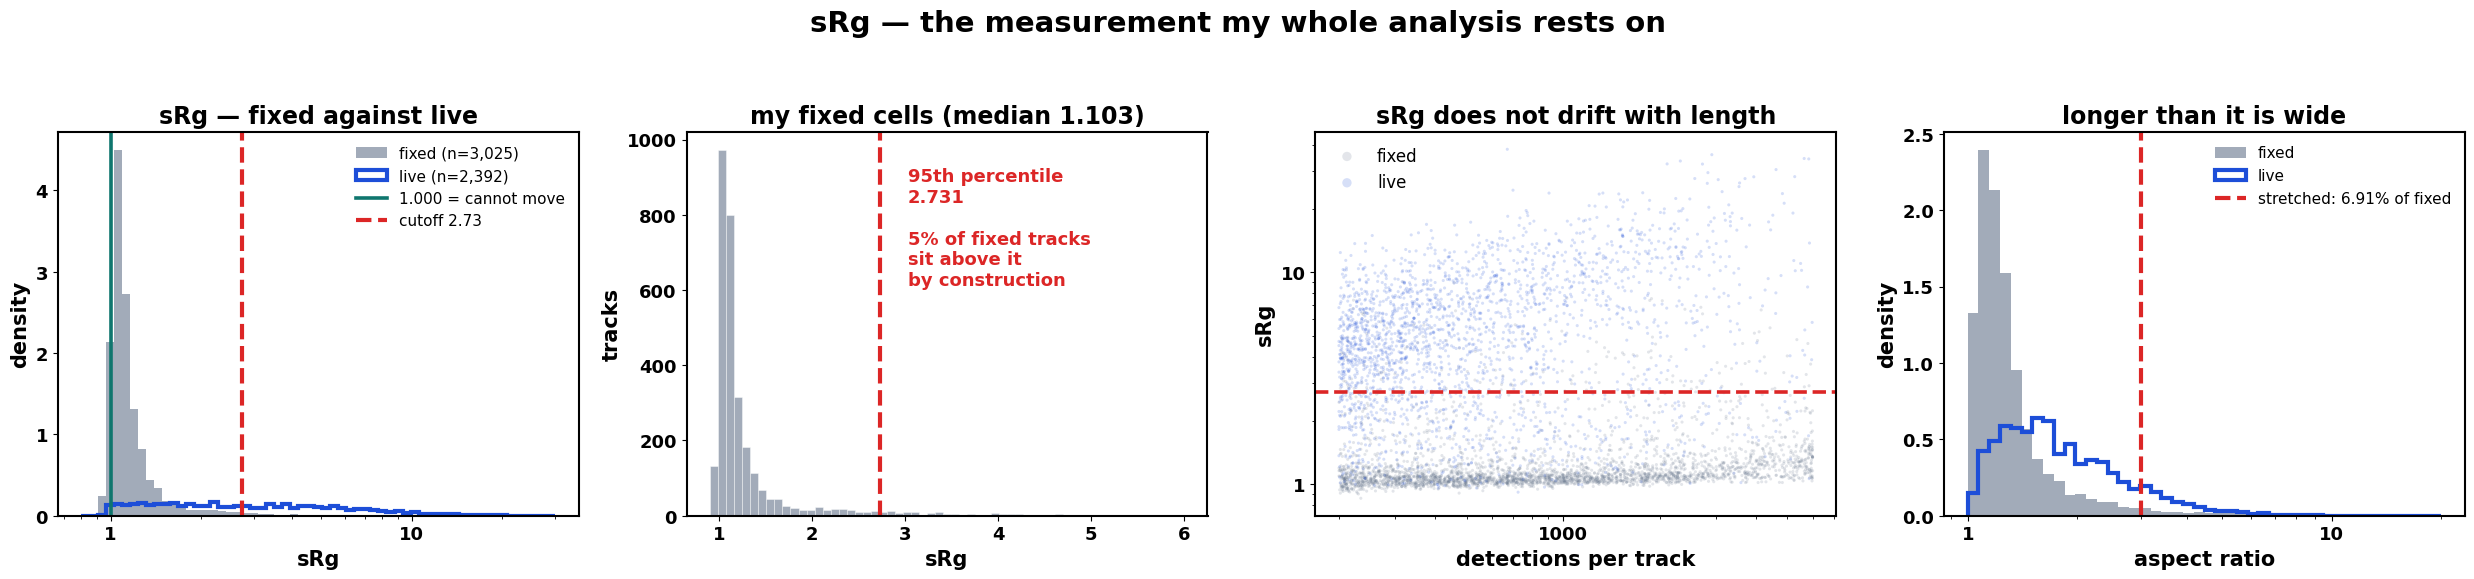

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
fmt = mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}")

ax = axes[0]
bins = np.logspace(np.log10(0.8), np.log10(30), 60)
ax.hist(R_FIX.sRg, bins=bins, density=True, color=C_FIX, alpha=.6,
        label=f"fixed (n={len(R_FIX):,})")
ax.hist(R_LIVE.sRg, bins=bins, density=True, histtype="step", lw=3,
        color=C_LIVE, label=f"live (n={len(R_LIVE):,})")
ax.axvline(1.0, color="#0f766e", lw=2.6, label="1.000 = cannot move")
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("sRg"); ax.set_ylabel("density")
ax.set_title("sRg — fixed against live")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
ax.hist(R_FIX.sRg, bins=np.linspace(0.9, 6, 60), color=C_FIX, alpha=.6,
        edgecolor="white", lw=.5)
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3)
ax.text(CUTOFF + .3, ax.get_ylim()[1] * .6,
        f"95th percentile\n{CUTOFF:.3f}\n\n5% of fixed tracks\nsit above it\n"
        f"by construction", color="#dc2626", fontsize=13, fontweight="bold")
ax.set_xlabel("sRg"); ax.set_ylabel("tracks")
ax.set_title(f"my fixed cells (median {R_FIX.sRg.median():.3f})")

ax = axes[2]
ax.scatter(R_FIX.n_det, R_FIX.sRg, s=5, alpha=.18, color=C_FIX,
           edgecolors="none", label="fixed")
ax.scatter(R_LIVE.n_det, R_LIVE.sRg, s=5, alpha=.18, color=C_LIVE,
           edgecolors="none", label="live")
ax.axhline(CUTOFF, color="#dc2626", ls="--", lw=2.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("detections per track"); ax.set_ylabel("sRg")
ax.set_title("sRg does not drift with length")
ax.legend(frameon=False, markerscale=3)

ax = axes[3]
bins = np.logspace(0, np.log10(20), 45)
ax.hist(R_FIX.aspect, bins=bins, density=True, color=C_FIX, alpha=.6,
        label="fixed")
ax.hist(R_LIVE.aspect, bins=bins, density=True, histtype="step", lw=3,
        color=C_LIVE, label="live")
ax.axvline(ASPECT_CUT, color="#dc2626", ls="--", lw=3,
           label=f"stretched: {STRETCHED:.2f}% of fixed")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("aspect ratio"); ax.set_ylabel("density")
ax.set_title("longer than it is wide")
ax.legend(fontsize=11, frameon=False)

bold_ticks(*axes)
fig.suptitle("sRg — the measurement my whole analysis rests on", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M4_srg_and_cutoff.png", bbox_inches="tight")

### Diffusion coefficient

Fitted as MSD = 4Dt + 4σ² over lags 1–8, so that D is not inflated by
localisation noise — the noise goes into the intercept and the motion into
the slope. Only tracks above my cutoff go into the pool; the immobile ones
would drag it down.

In [12]:
def fitted_D(fr, P, max_lag=8):
    """D and the noise floor, from the MSD over short lags. Gap-aware."""
    f0 = fr[0]
    span = int(fr[-1] - f0 + 1)
    A = np.full((span, 2), np.nan)
    A[fr - f0] = P
    lags, msd = [], []
    for k in range(1, min(max_lag, span - 1) + 1):
        dd = A[k:] - A[:-k]
        dd = dd[np.isfinite(dd).all(1)]
        if dd.shape[0] >= 20:
            lags.append(k); msd.append((dd ** 2).sum(1).mean())
    if len(lags) < 4:
        return np.nan, np.nan
    slope, icpt = np.polyfit(np.array(lags) * DT_S, np.array(msd), 1)
    return slope / 4, np.sqrt(max(icpt, 0) / 4)

tid = real_live.track_gid.to_numpy(); fr_ = real_live.frame.to_numpy()
P_ = real_live[["x_um", "y_um"]].to_numpy(np.float64)
cuts = np.flatnonzero(np.diff(tid)) + 1
starts = np.concatenate([[0], cuts]); ends = np.concatenate([cuts, [len(tid)]])
rows = []
for s, e in tqdm(zip(starts, ends), total=len(starts), desc="D per track"):
    if e - s < MIN_TRACK_LEN:
        continue
    D, sig = fitted_D(fr_[s:e], P_[s:e])
    rows.append({"track_gid": tid[s], "D": D, "sigma_fit": sig, "n_det": e - s})
D_TAB  = pd.DataFrame(rows).merge(R_LIVE[["track_gid", "sRg"]], on="track_gid")
D_POOL = D_TAB[(D_TAB.sRg > CUTOFF) & (D_TAB.D > 0)].D.to_numpy()

print(f"mobile tracks: {len(D_POOL):,} of {len(D_TAB):,} "
      f"(sRg above {CUTOFF:.3f})")
print(f"   D median {np.median(D_POOL):.4f} um2/s, "
      f"5-95th {np.quantile(D_POOL,.05):.4f}-{np.quantile(D_POOL,.95):.4f}")
print(f"   library x{D_SCALE[0]}-{D_SCALE[1]} -> "
      f"{D_SCALE[0]*np.quantile(D_POOL,.05):.4f}-"
      f"{D_SCALE[1]*np.quantile(D_POOL,.95):.4f}")
print(f"   the fit's own noise estimate: {1000*np.nanmedian(D_TAB.sigma_fit):.1f}"
      f" nm, against {1000*np.median(SIGMA):.1f} nm from fixed cells - two")
print(f"   independent measurements agreeing to about 10%")

D per track:   0%|          | 0/2392 [00:00<?, ?it/s]

mobile tracks: 1,833 of 2,392 (sRg above 2.731)
   D median 0.1180 um2/s, 5-95th 0.0278-0.2762
   library x0.3-3.0 -> 0.0083-0.8285
   the fit's own noise estimate: 36.0 nm, against 40.0 nm from fixed cells - two
   independent measurements agreeing to about 10%


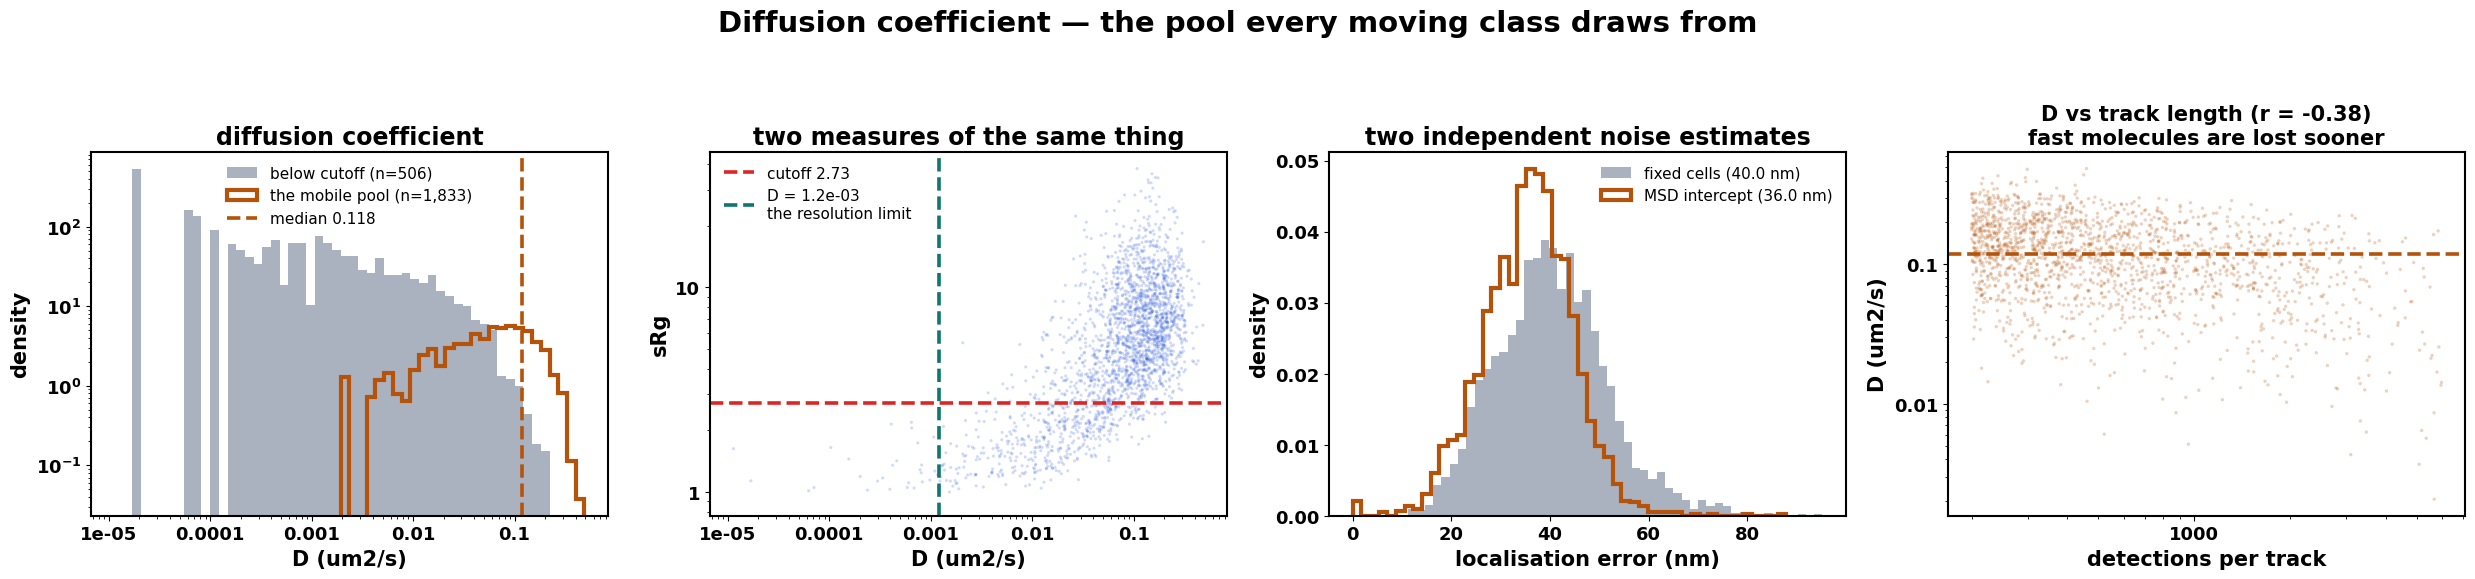

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
mobm = D_TAB[(D_TAB.sRg > CUTOFF) & (D_TAB.D > 0)]
immm = D_TAB[(D_TAB.sRg <= CUTOFF) & (D_TAB.D > 0)]

ax = axes[0]
bins = np.logspace(np.log10(max(D_TAB.D[D_TAB.D > 0].min(), 1e-5)),
                   np.log10(D_TAB.D.max()), 55)
ax.hist(immm.D, bins=bins, density=True, color=C_FIX, alpha=.55,
        label=f"below cutoff (n={len(immm):,})")
ax.hist(mobm.D, bins=bins, density=True, histtype="step", lw=3, color=C_SIM,
        label=f"the mobile pool (n={len(mobm):,})")
ax.axvline(np.median(D_POOL), color=C_SIM, ls="--", lw=2.6,
           label=f"median {np.median(D_POOL):.3f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("D (um2/s)"); ax.set_ylabel("density")
ax.set_title("diffusion coefficient")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
ax.scatter(D_TAB.D, D_TAB.sRg, s=5, alpha=.2, color=C_LIVE, edgecolors="none")
ax.axhline(CUTOFF, color="#dc2626", ls="--", lw=2.6, label=f"cutoff {CUTOFF:.2f}")
ax.axvline(D_IMMOBILE[1], color="#0f766e", ls="--", lw=2.6,
           label=f"D = {D_IMMOBILE[1]:.1e}\nthe resolution limit")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("D (um2/s)"); ax.set_ylabel("sRg")
ax.set_title("two measures of the same thing")
ax.legend(fontsize=11, frameon=False)

ax = axes[2]
ax.hist(1000 * SIGMA, bins=50, density=True, color=C_FIX, alpha=.55,
        label=f"fixed cells ({1000*np.median(SIGMA):.1f} nm)")
ax.hist(1000 * D_TAB.sigma_fit.dropna(), bins=50, density=True,
        histtype="step", lw=3, color=C_SIM,
        label=f"MSD intercept ({1000*np.nanmedian(D_TAB.sigma_fit):.1f} nm)")
ax.set_xlabel("localisation error (nm)"); ax.set_ylabel("density")
ax.set_title("two independent noise estimates")
ax.legend(fontsize=11, frameon=False)

ax = axes[3]
ax.scatter(mobm.n_det, mobm.D, s=6, alpha=.25, color=C_SIM, edgecolors="none")
ax.axhline(np.median(D_POOL), color=C_SIM, ls="--", lw=2.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
r = np.corrcoef(np.log(mobm.n_det), np.log(mobm.D))[0, 1]
ax.set_xlabel("detections per track"); ax.set_ylabel("D (um2/s)")
ax.set_title(f"D vs track length (r = {r:.2f})\nfast molecules are lost sooner",
             fontsize=15)

bold_ticks(*axes)
fig.suptitle("Diffusion coefficient — the pool every moving class draws from",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M5_diffusion.png", bbox_inches="tight")

### Corral radius

A molecule free to diffuse has an MSD that keeps rising. One held inside a
corral rises and then flattens, and the height it flattens at is the size of
the space. Localisation error adds a constant 4σ² to every point, so that
comes off; and a track flattening *at* the noise floor is immobile rather than
corralled, so the plateau has to clear twice the noise to count.

That requirement is also the blind spot: a corral tighter than about 2σ cannot
be seen at all.

In [14]:
def corral_pool(d, sigma_um, min_det=MIN_TRACK_LEN):
    """corral size from the plateau of each track's own MSD"""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    cuts = np.flatnonzero(np.diff(tid)) + 1
    starts = np.concatenate([[0], cuts]); ends = np.concatenate([cuts, [len(tid)]])
    noise, rows = 4 * sigma_um ** 2, []
    for s, e in tqdm(zip(starts, ends), total=len(starts), desc="corral sizes"):
        if e - s < min_det:
            continue
        f, p = fr[s:e], P[s:e]
        f0, span = f[0], int(f[-1] - f[0] + 1)
        A = np.full((span, 2), np.nan)
        A[f - f0] = p
        lags = np.unique(np.round(
            np.logspace(0, np.log10(max(8, span // 4)), 25)).astype(int))
        lags = lags[lags < span]
        msd = []
        for k in lags:
            dd = A[k:] - A[:-k]
            dd = dd[np.isfinite(dd).all(1)]
            msd.append((dd ** 2).sum(1).mean() if dd.shape[0] >= 20 else np.nan)
        msd = np.array(msd); ok = np.isfinite(msd)
        if ok.sum() < 8:
            continue
        m = msd[ok]
        late = m[int(.75 * len(m)):].mean()
        mid  = m[int(.40 * len(m)):int(.75 * len(m))].mean()
        rows.append({"track_gid": tid[s], "n_det": e - s, "plateau": late,
                     "flat": late < 1.25 * mid, "above_noise": late > 2 * noise,
                     "R_um": np.sqrt(late - noise) if late > noise else np.nan})
    return pd.DataFrame(rows)

CORRAL_TAB = corral_pool(real_live, float(np.median(SIGMA)))
keep = CORRAL_TAB.flat & CORRAL_TAB.above_noise & CORRAL_TAB.R_um.notna()
CORRAL = CORRAL_TAB.loc[keep, "R_um"].to_numpy()

print(f"{len(CORRAL_TAB):,} tracks examined")
print(f"   stopped rising:        {int(CORRAL_TAB.flat.sum()):,}")
print(f"   and cleared the noise: {len(CORRAL):,} "
      f"({100*len(CORRAL)/len(CORRAL_TAB):.1f}%)")
print(f"corral radius: median {1000*np.median(CORRAL):.0f} nm, "
      f"10-90th {1000*np.quantile(CORRAL,.10):.0f}-"
      f"{1000*np.quantile(CORRAL,.90):.0f} nm")
print(f"   blind below ~{2000*np.median(SIGMA):.0f} nm")
print(f"   library x{CORRAL_SCALE[0]}-{CORRAL_SCALE[1]} -> "
      f"{1000*CORRAL_SCALE[0]*CORRAL.min():.0f}-"
      f"{1000*CORRAL_SCALE[1]*CORRAL.max():.0f} nm")

corral sizes:   0%|          | 0/2392 [00:00<?, ?it/s]

2,392 tracks examined
   stopped rising:        254
   and cleared the noise: 96 (4.0%)
corral radius: median 119 nm, 10-90th 85-231 nm
   blind below ~80 nm
   library x0.5-3.0 -> 40-1083 nm


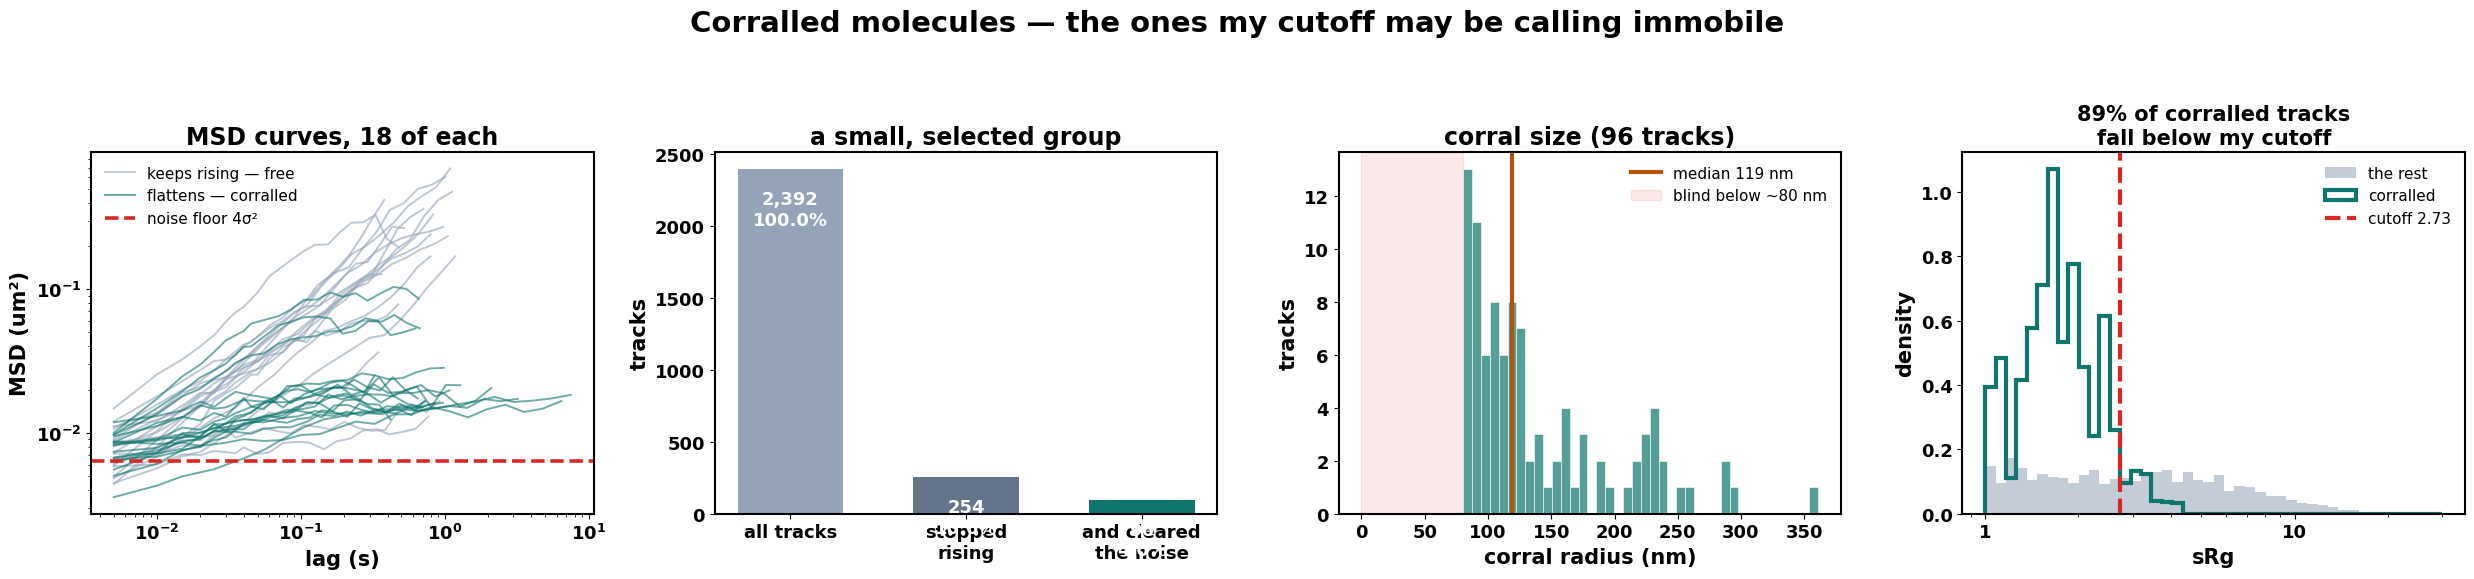

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
C_CORR, C_FREE = "#0f766e", "#94a3b8"
noise_level = 4 * float(np.median(SIGMA)) ** 2

def msd_curve(fr, P, n_lag=25):
    f0, span = fr[0], int(fr[-1] - fr[0] + 1)
    A = np.full((span, 2), np.nan); A[fr - f0] = P
    lags = np.unique(np.round(
        np.logspace(0, np.log10(max(8, span // 4)), n_lag)).astype(int))
    lags = lags[lags < span]
    out = []
    for k in lags:
        dd = A[k:] - A[:-k]; dd = dd[np.isfinite(dd).all(1)]
        out.append((dd ** 2).sum(1).mean() if dd.shape[0] >= 20 else np.nan)
    return lags * DT_S, np.array(out)

tid_l = real_live.track_gid.to_numpy(); fr_l = real_live.frame.to_numpy()
P_l = real_live[["x_um", "y_um"]].to_numpy(np.float64)
cuts = np.flatnonzero(np.diff(tid_l)) + 1
st_l = np.concatenate([[0], cuts]); en_l = np.concatenate([cuts, [len(tid_l)]])
pos = {t: (s, e) for t, s, e in zip(tid_l[st_l], st_l, en_l)}
flat_ids = CORRAL_TAB.loc[keep, "track_gid"].to_numpy()
free_ids = CORRAL_TAB.loc[~CORRAL_TAB.flat, "track_gid"].to_numpy()
rg = np.random.default_rng(SEED)

ax = axes[0]
for ids, c, lab in [(free_ids, C_FREE, "keeps rising — free"),
                    (flat_ids, C_CORR, "flattens — corralled")]:
    for j, t in enumerate(rg.choice(ids, min(18, len(ids)), replace=False)):
        s, e = pos[t]
        x, y = msd_curve(fr_l[s:e], P_l[s:e])
        ax.plot(x, y, lw=1.4, color=c, alpha=.6, label=lab if j == 0 else None)
ax.axhline(noise_level, color="#dc2626", ls="--", lw=2.6, label="noise floor 4σ²")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title("MSD curves, 18 of each")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
bars = [len(CORRAL_TAB), int(CORRAL_TAB.flat.sum()), len(CORRAL)]
ax.bar(range(3), bars, color=[C_FREE, "#64748b", C_CORR], width=.6)
for i, v in enumerate(bars):
    ax.text(i, v, f"\n{v:,}\n{100*v/bars[0]:.1f}%", ha="center", va="top",
            fontsize=13, fontweight="bold", color="white")
ax.set_xticks(range(3))
ax.set_xticklabels(["all tracks", "stopped\nrising", "and cleared\nthe noise"])
ax.set_ylabel("tracks")
ax.set_title("a small, selected group")

ax = axes[2]
ax.hist(1000 * CORRAL, bins=40, color=C_CORR, alpha=.7, edgecolor="white", lw=.6)
ax.axvline(1000 * np.median(CORRAL), color="#b45309", lw=3,
           label=f"median {1000*np.median(CORRAL):.0f} nm")
ax.axvspan(0, 2000 * np.median(SIGMA), color="#dc2626", alpha=.10, zorder=0,
           label=f"blind below ~{2000*np.median(SIGMA):.0f} nm")
ax.set_xlabel("corral radius (nm)"); ax.set_ylabel("tracks")
ax.set_title(f"corral size ({len(CORRAL)} tracks)")
ax.legend(fontsize=11, frameon=False)

ax = axes[3]
J = CORRAL_TAB.merge(R_LIVE[["track_gid", "sRg"]], on="track_gid")
J["corralled"] = J.flat & J.above_noise & J.R_um.notna()
bins = np.logspace(0, np.log10(30), 45)
ax.hist(J.loc[~J.corralled, "sRg"], bins=bins, density=True, color=C_FREE,
        alpha=.55, label="the rest")
ax.hist(J.loc[J.corralled, "sRg"], bins=bins, density=True, histtype="step",
        lw=3, color=C_CORR, label="corralled")
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
pct = 100 * float((J.loc[J.corralled, "sRg"] <= CUTOFF).mean())
ax.set_xlabel("sRg"); ax.set_ylabel("density")
ax.set_title(f"{pct:.0f}% of corralled tracks\nfall below my cutoff", fontsize=15)
ax.legend(fontsize=11, frameon=False)

bold_ticks(*axes)
fig.suptitle("Corralled molecules — the ones my cutoff may be calling immobile",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M6_corral.png", bbox_inches="tight")

### Density

How crowded a field is, measured as detections per frame over the area the
molecules actually cover. It matters because it sets how often the tracker
picks the wrong neighbour.

In [16]:
def density_per_field(d):
    """detections per frame / convex hull area, per field"""
    rows = []
    for fov, g in tqdm(d.groupby("fov_uid"), total=d.fov_uid.nunique(),
                       desc="density per field"):
        P = g[["x_um", "y_um"]].to_numpy()
        if len(P) < 10:
            continue
        area = ConvexHull(P).volume
        rows.append({"fov_uid": fov, "area_um2": area,
                     "n_tracks": g.track_gid.nunique(),
                     "per_frame": len(g) / g.frame.nunique(),
                     "density": len(g) / g.frame.nunique() / area})
    return pd.DataFrame(rows)

DENS_TAB = density_per_field(real_live)
DENS_FIX = density_per_field(real_fix)
DENSITY  = DENS_TAB.density.to_numpy()
my_density = float(np.median(DENSITY))

print(f"density: median {my_density:.4f} puncta/um2, "
      f"range {DENSITY.min():.4f}-{DENSITY.max():.4f} ({len(DENSITY)} fields)")
print(f"   library {DENSITY_RANGE[0]}-{DENSITY_RANGE[1]} /um2, log-uniform")
print(f"   fields below the library floor: "
      f"{int((DENSITY < DENSITY_RANGE[0]).sum())} of {len(DENSITY)}")

C:\Users\chatt\AppData\Local\Temp\ipykernel_38056\3907739628.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for fov, g in tqdm(d.groupby("fov_uid"), total=d.fov_uid.nunique(),


density per field:   0%|          | 0/27 [00:00<?, ?it/s]

density per field:   0%|          | 0/53 [00:00<?, ?it/s]

density: median 0.0522 puncta/um2, range 0.0222-0.1102 (27 fields)
   library 0.005-0.8 /um2, log-uniform
   fields below the library floor: 0 of 27


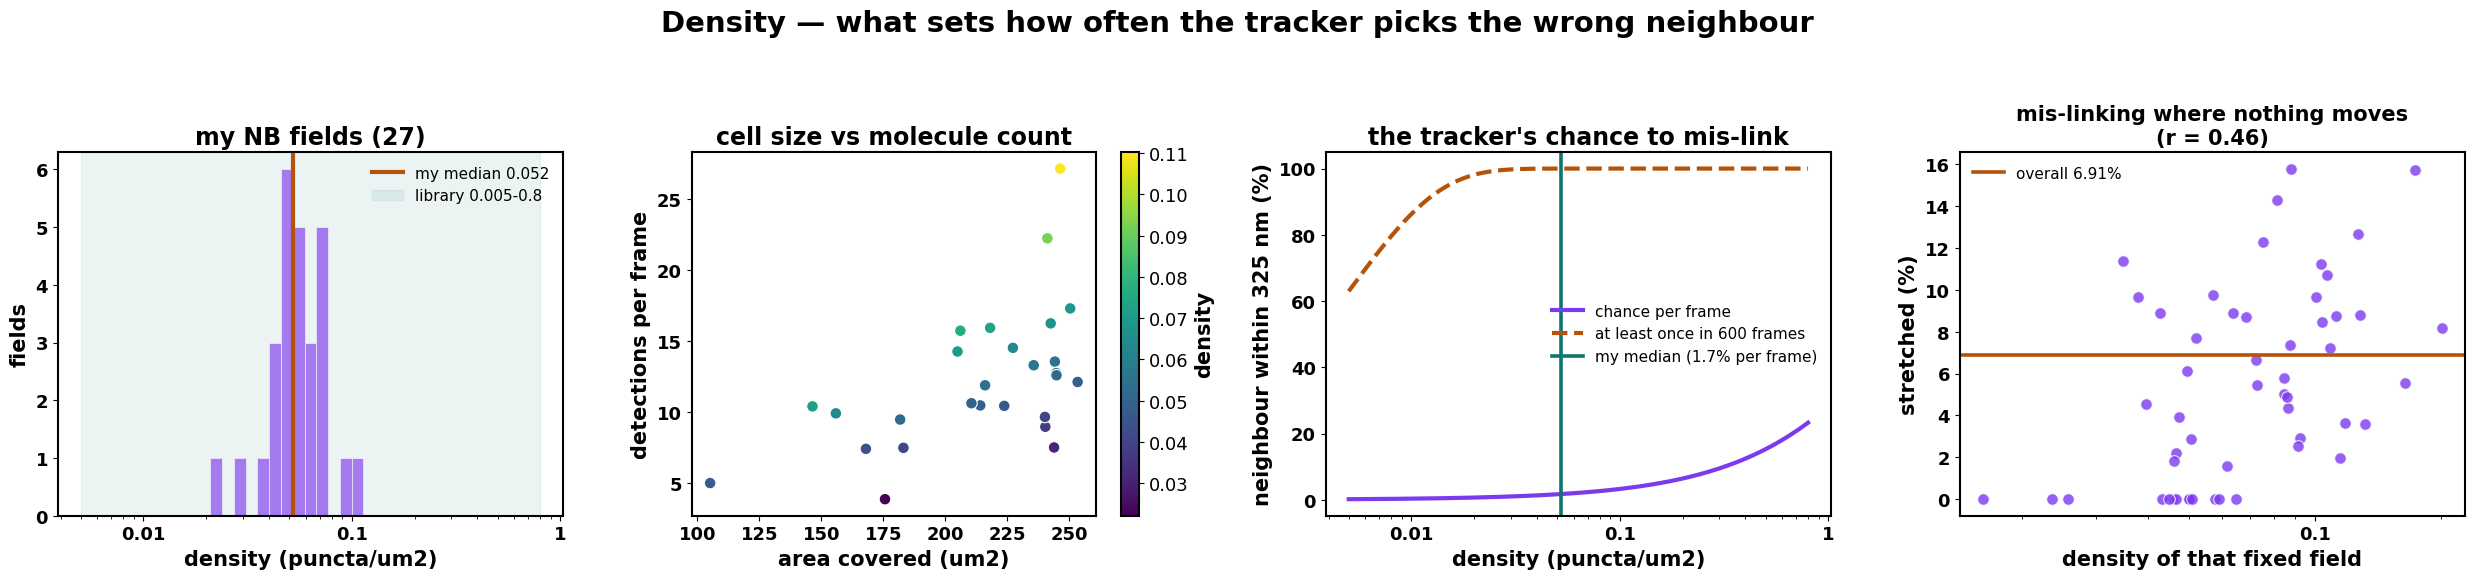

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
C_DEN = "#7c3aed"

ax = axes[0]
bins = np.logspace(np.log10(DENSITY_RANGE[0]), np.log10(DENSITY_RANGE[1]), 40)
ax.hist(DENSITY, bins=bins, color=C_DEN, alpha=.65, edgecolor="white", lw=.6)
ax.axvline(my_density, color="#b45309", lw=3, label=f"my median {my_density:.3f}")
ax.axvspan(*DENSITY_RANGE, color="#0f766e", alpha=.08, zorder=0,
           label=f"library {DENSITY_RANGE[0]}-{DENSITY_RANGE[1]}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("density (puncta/um2)"); ax.set_ylabel("fields")
ax.set_title(f"my NB fields ({len(DENSITY)})")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
sc = ax.scatter(DENS_TAB.area_um2, DENS_TAB.per_frame, s=70,
                c=DENS_TAB.density, cmap="viridis", edgecolors="white", lw=.8)
plt.colorbar(sc, ax=ax, label="density")
ax.set_xlabel("area covered (um2)"); ax.set_ylabel("detections per frame")
ax.set_title("cell size vs molecule count")

ax = axes[2]
d_grid = np.logspace(np.log10(DENSITY_RANGE[0]), np.log10(DENSITY_RANGE[1]), 200)
p_frame = 1 - np.exp(-d_grid * np.pi * R_LINK ** 2)
ax.plot(d_grid, 100 * p_frame, lw=3, color=C_DEN, label="chance per frame")
ax.plot(d_grid, 100 * (1 - (1 - p_frame) ** 600), lw=3, color="#b45309",
        ls="--", label="at least once in 600 frames")
ax.axvline(my_density, color="#0f766e", lw=2.6,
           label=f"my median ({100*(1-np.exp(-my_density*np.pi*R_LINK**2)):.1f}%"
                 f" per frame)")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("density (puncta/um2)")
ax.set_ylabel(f"neighbour within {1000*R_LINK:.0f} nm (%)")
ax.set_title("the tracker's chance to mis-link")
ax.legend(fontsize=11, frameon=False)

ax = axes[3]
fov_of = real_fix.groupby("track_gid").fov_uid.first().reset_index()
Jd = R_FIX.merge(fov_of, on="track_gid")
Jd["stretched"] = Jd.aspect > ASPECT_CUT
per_fov = (Jd.groupby("fov_uid").stretched.mean().mul(100)
           .rename("stretched_pct").reset_index()
           .merge(DENS_FIX[["fov_uid", "density"]], on="fov_uid"))
ax.scatter(per_fov.density, per_fov.stretched_pct, s=70, color=C_DEN, alpha=.8,
           edgecolors="white", lw=.8)
r = per_fov[["density", "stretched_pct"]].corr().iloc[0, 1]
ax.axhline(STRETCHED, color="#b45309", lw=2.6, label=f"overall {STRETCHED:.2f}%")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("density of that fixed field"); ax.set_ylabel("stretched (%)")
ax.set_title(f"mis-linking where nothing moves\n(r = {r:.2f})", fontsize=15)
ax.legend(fontsize=11, frameon=False)

bold_ticks(*axes)
fig.suptitle("Density — what sets how often the tracker picks the wrong "
             "neighbour", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M7_density.png", bbox_inches="tight")

### Unresolved pairs — estimating them from brightness

The brightness analysis below estimates the fraction of fixed-cell tracks whose
mean intensity is above 1.5 times the single-molecule brightness mode. This is a
**brightness-based proxy**, not a definitive count of unresolved pairs: focus,
dye brightness, and illumination can also make a single molecule appear bright.

The field simulation gives a separate prediction based on random spatial
overlap. Keep the brightness estimate and simulation prediction separate; do
not treat them as interchangeable measurements.

In [18]:
# what my field simulation predicted, from the run with my own linker
# settings. These are measurements, so they live here with the others rather
# than down in the artefact model that uses them.
LINK_TABLE = pd.DataFrame({
    "density":     [0.02, 0.05, 0.10, 0.20, 0.45, 0.80],
    "mislink_pct": [0.00, 1.48, 2.61, 5.59, 11.70, 17.92],
    "pair_pct":    [0.00, 0.07, 0.39, 1.24,  2.48,  4.34]})

def pair_rate_fieldsim(density):
    """The field simulation's pair prediction, kept for comparison."""
    return float(np.interp(density, LINK_TABLE.density,
                           LINK_TABLE.pair_pct)) / 100

_I = SIG_TAB.intensity.to_numpy()
_I = _I[np.isfinite(_I) & (_I > 0)]
# the single-molecule brightness is the mode, not the mean: pairs and brighter
# artefacts pull a mean up, a mode is where most molecules sit
_h, _e = np.histogram(_I, bins=80)
_mode = 0.5 * (_e[int(np.argmax(_h))] + _e[int(np.argmax(_h)) + 1])
# Brightness-based unresolved-pair proxy used by the simulation below.
PAIR_AT_MINE = float(np.mean(_I > 1.5 * _mode))

rows = []
for thr, lab in [(1.5, "1.5x the single-molecule mode"),
                 (1.7, "1.7x"), (2.0, "2.0x (a clean double)")]:
    rows.append({"threshold": lab,
                 "intensity": round(thr * _mode, 1),
                 "tracks above": int((_I > thr * _mode).sum()),
                 "% of tracks": round(100 * float((_I > thr * _mode).mean()), 2)})
PAIR_I = pd.DataFrame(rows)
PAIR_I.to_csv(TAB_DIR / "pair_rate_from_brightness.csv", index=False)
print(f"single-molecule brightness (mode): {_mode:.1f}")
print(PAIR_I.to_string(index=False))
print()
print("for comparison:")
print(f"   brightness-based proxy: {100*PAIR_AT_MINE:.2f}%")
print(f"   field-simulation prediction: {pair_rate_fieldsim(my_density)*100:.2f}%")
print("These are different estimation methods. The brightness threshold is a")
print("proxy for unresolved pairs, not a definitive pair count.")

single-molecule brightness (mode): 131.1
                    threshold  intensity  tracks above  % of tracks
1.5x the single-molecule mode 196.699997            24         0.79
                         1.7x 222.899994             6         0.20
        2.0x (a clean double) 262.299988             0         0.00

for comparison:
   brightness-based proxy: 0.79%
   field-simulation prediction: 0.08%
These are different estimation methods. The brightness threshold is a
proxy for unresolved pairs, not a definitive pair count.


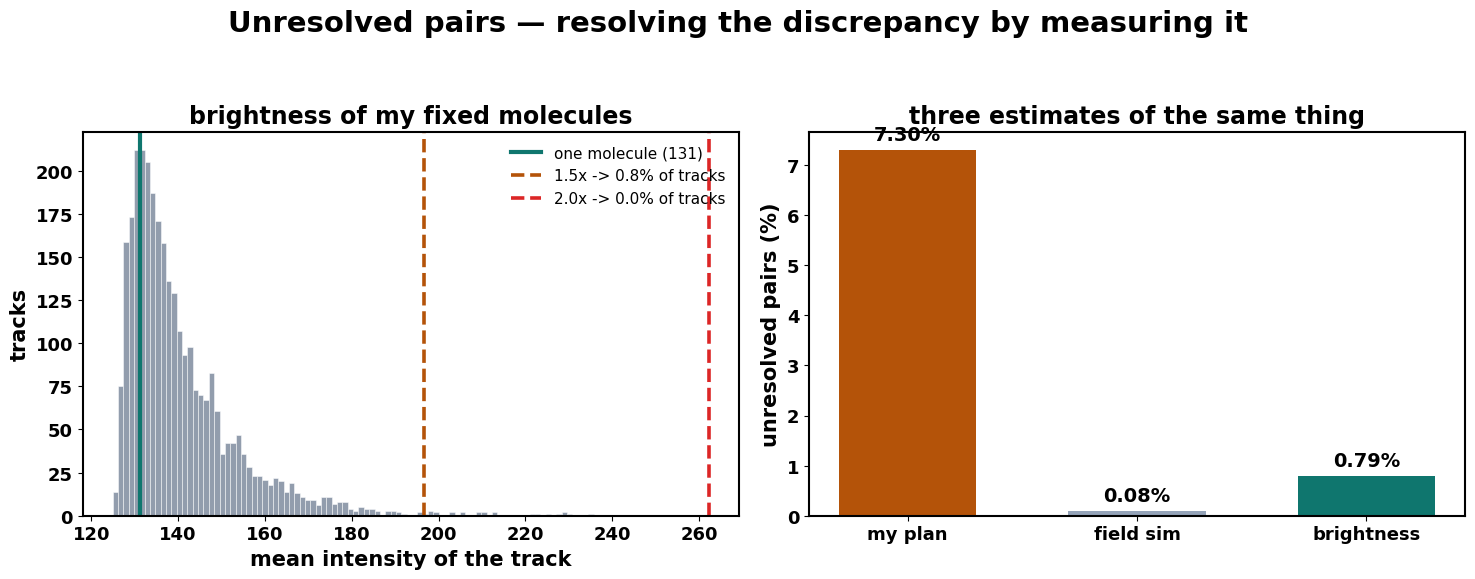

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

ax = axes[0]
ax.hist(_I, bins=90, color=C_FIX, alpha=.7, edgecolor="white", lw=.5)
ax.axvline(_mode, color="#0f766e", lw=3, label=f"one molecule ({_mode:.0f})")
for thr, c in [(1.5, "#b45309"), (2.0, "#dc2626")]:
    ax.axvline(thr * _mode, color=c, ls="--", lw=2.6,
               label=f"{thr}x -> {100*(_I > thr*_mode).mean():.1f}% of tracks")
ax.set_xlabel("mean intensity of the track"); ax.set_ylabel("tracks")
ax.set_title("brightness of my fixed molecules")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
ax.bar(range(3), [7.30, 100 * pair_rate_fieldsim(my_density),
                  float(PAIR_I.loc[PAIR_I.threshold.str.startswith("1.5"),
                                   "% of tracks"].iloc[0])],
       color=["#b45309", "#94a3b8", "#0f766e"], width=.6)
for i, v in enumerate([7.30, 100 * pair_rate_fieldsim(my_density),
                       float(PAIR_I.loc[PAIR_I.threshold.str.startswith("1.5"),
                                        "% of tracks"].iloc[0])]):
    ax.text(i, v + .2, f"{v:.2f}%", ha="center", fontsize=14, fontweight="bold")
ax.set_xticks(range(3))
ax.set_xticklabels(["my plan", "field sim", "brightness"])
ax.set_ylabel("unresolved pairs (%)")
ax.set_title("three estimates of the same thing")

bold_ticks(*axes)
fig.suptitle("Unresolved pairs — resolving the discrepancy by measuring it",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M7b_pair_rate.png", bbox_inches="tight")

### Everything measured, in one table

In [20]:
duty_all = pd.concat([FIX.duty, LIVE.duty])
MEASURED = pd.DataFrame([
    ("localisation error", f"{1000*np.median(SIGMA):.1f} nm",
     f"{1000*SIGMA_RANGE[0]:.0f}-{1000*SIGMA_RANGE[1]:.0f} nm",
     "fixed cells: every step is pure error"),
    ("duty cycle", f"{duty_all.median():.2f}",
     f"{DUTY_RANGE[0]}-{DUTY_RANGE[1]}", "every real track's frame pattern"),
    ("stage drift", f"{1000*np.median(DRIFT):.0f} nm/movie "
                    f"({1000*DRIFT.min():.0f}-{1000*DRIFT.max():.0f})",
     f"x{DRIFT_SCALE[0]}-{DRIFT_SCALE[1]}", "long tracks, start vs end"),
    ("linker jump limit", f"{1000*R_LINK:.0f} nm", f"{1000*R_LINK:.0f} nm",
     "the tracking software, not the sample - so no range"),
    ("density", f"{my_density:.3f} /um2 "
                f"({DENSITY.min():.3f}-{DENSITY.max():.3f})",
     f"{DENSITY_RANGE[0]}-{DENSITY_RANGE[1]} /um2",
     "detections per frame / hull area"),
    ("diffusion coefficient", f"{np.median(D_POOL):.3f} um2/s",
     f"x{D_SCALE[0]}-{D_SCALE[1]}", "MSD fit, lags 1-8, mobile tracks only"),
    ("corral radius", f"{1000*np.median(CORRAL):.0f} nm "
                      f"({1000*np.quantile(CORRAL,.1):.0f}-"
                      f"{1000*np.quantile(CORRAL,.9):.0f})",
     f"x{CORRAL_SCALE[0]}-{CORRAL_SCALE[1]}",
     f"MSD plateau, {len(CORRAL)} tracks; blind below "
     f"{2000*np.median(SIGMA):.0f} nm"),
    ("unresolved pairs", f"{100*PAIR_AT_MINE:.2f}% brightness proxy",
     f"{100*UNRESOLVED[0]:.0f}-{100*UNRESOLVED[1]:.0f}%",
     "brightness-based estimate; not a definitive pair count"),
    ("mis-linking", f"{STRETCHED:.2f}% stretched", "scales with density",
     "calibrated against my own fixed cells"),
    ("detection threshold", "not measurable",
     f"{EXPOSURE_RANGE[0]}-{EXPOSURE_RANGE[1]} of a frame",
     "ASSUMED - a photon threshold, and I took intensity out"),
    ("obstacle spacing", "not measurable",
     f"{LATTICE_NM[0]:.0f}-{LATTICE_NM[1]:.0f} nm",
     "ASSUMED - below what single-particle tracking resolves"),
    ("drift direction", "mostly one axis",
     "drawn from my measured per-field angles",
     "shared within a field, as a stage is - not per molecule"),
], columns=["parameter", "what I measured", "training library", "how / caveat"])
MEASURED.to_csv(TAB_DIR / "measured_parameters.csv", index=False)
print(MEASURED.to_string(index=False))

# Everything from here runs on the pools measured above, not on the raw
# positions, so the two real track tables can go. Together they are about four
# million rows, and holding them alongside three simulated sets is what ran the
# kernel out of memory.
N_REAL_FIX = int(real_fix.track_gid.nunique())
N_REAL_LIVE = int(real_live.track_gid.nunique())
del real_fix, real_live
gc.collect()
print()
print("freed the real track tables; the measured pools carry on from here")

            parameter          what I measured                        training library                                            how / caveat
   localisation error                  40.0 nm                                15-80 nm                   fixed cells: every step is pure error
           duty cycle                     0.74                                 0.2-1.0                        every real track's frame pattern
          stage drift     71 nm/movie (17-136)                                x0.5-3.0                               long tracks, start vs end
    linker jump limit                   325 nm                                  325 nm     the tracking software, not the sample - so no range
              density 0.052 /um2 (0.022-0.110)                          0.005-0.8 /um2                        detections per frame / hull area
diffusion coefficient              0.118 um2/s                                x0.3-3.0                   MSD fit, lags 1-8, mobile tracks only


freed the real track tables; the measured pools carry on from here


## 2. The five motion models

Saxton MJ & Jacobson K (1997), *Annu. Rev. Biophys. Biomol. Struct.* 26:373–399,
doi:10.1146/annurev.biophys.26.1.373

| type | model | MSD |
|---|---|---|
| normal | free Brownian diffusion | 4Dt |
| restricted | fractional Gaussian noise | 4Dt^α, α = 0.3–0.9 |
| corralled | diffusion inside a circular corral | rises, flattens at R² |
| directed | Brownian diffusion plus a velocity | 4Dt + (vt)² |
| immobile | very slow Brownian motion | ≈ 0 |

Two things I deliberately do not take on faith. The corral curve uses no
fitted constants — R²(1 − exp(−4Dt/R²)) is 4Dt at short lags and R² at long
ones, and R² is the exact plateau for a particle spread over a disc. And the
anomalous curves are anchored at one frame: in 4Dt^α the coefficient only has
units of µm²/s when α = 1, so reusing the same number at a different α would
make a restricted molecule take *bigger* steps than a free one.

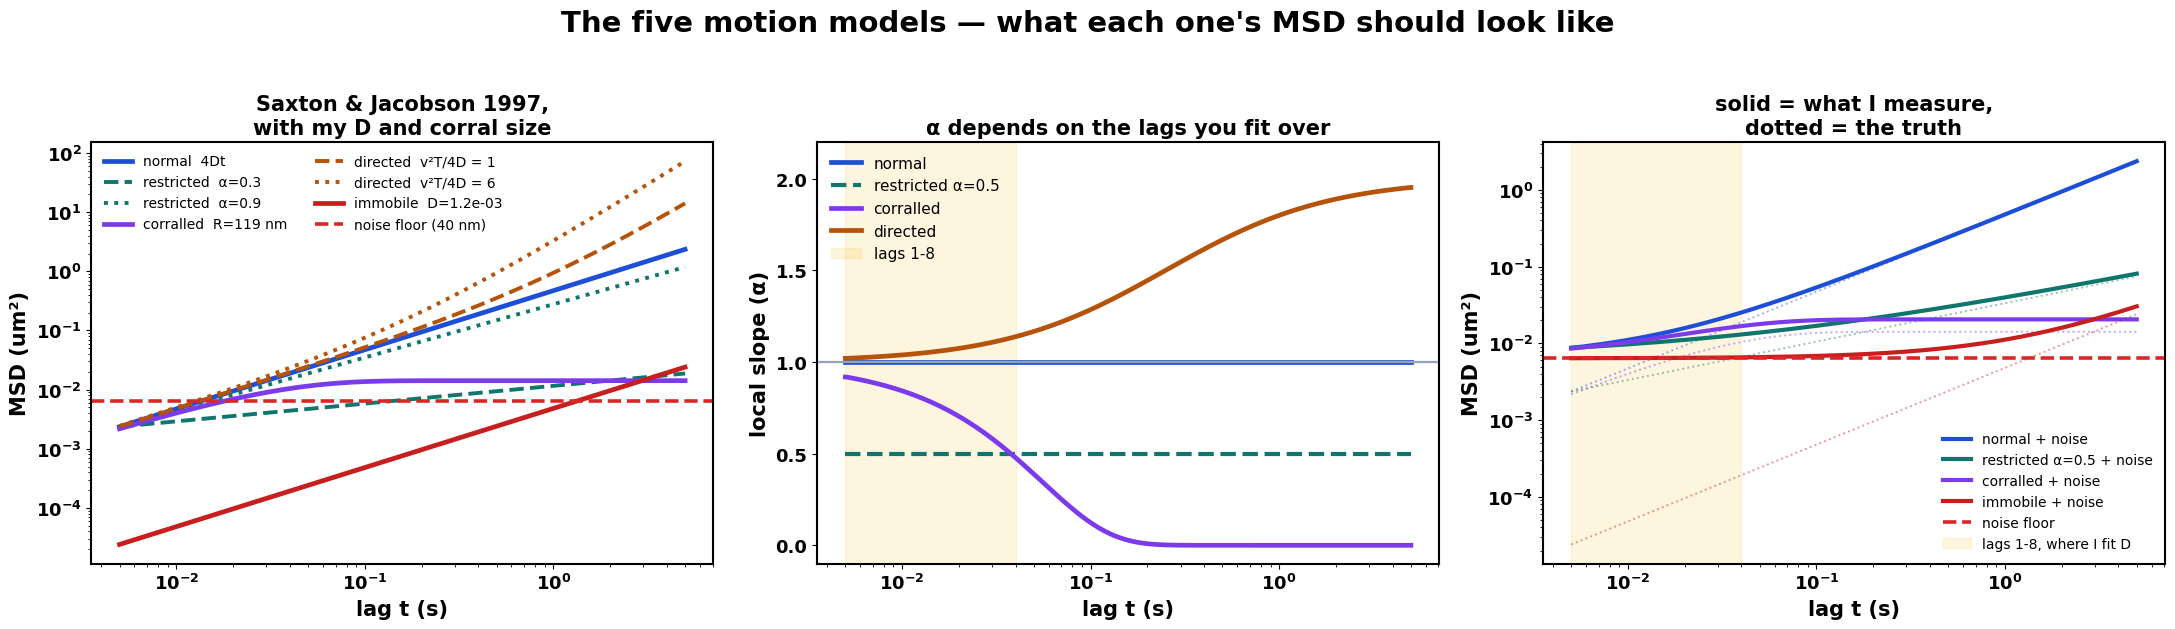

In [21]:
D_  = float(np.median(D_POOL))
rc_ = float(np.median(CORRAL))
t   = np.logspace(np.log10(DT_S), np.log10(5.0), 300)
noise = 4 * float(np.median(SIGMA)) ** 2

msd_normal     = lambda tt: 4 * D_ * tt
msd_restricted = lambda tt, a: 4 * (D_ * DT_S ** (1 - a)) * tt ** a
msd_corralled  = lambda tt: rc_ ** 2 * (1 - np.exp(-4 * D_ * tt / rc_ ** 2))
msd_directed   = lambda tt, dn, T=1.0: (4 * D_ * tt
                                        + (np.sqrt(4 * D_ * dn / T) * tt) ** 2)
msd_immobile   = lambda tt: 4 * D_IMMOBILE[1] * tt

fig, axes = plt.subplots(1, 3, figsize=(22, 6.2))

ax = axes[0]
ax.plot(t, msd_normal(t), lw=3.4, color=COL["normal"], label="normal  4Dt")
for a_, ls in ((0.3, "--"), (0.9, ":")):
    ax.plot(t, msd_restricted(t, a_), lw=2.8, color=COL["restricted"], ls=ls,
            label=f"restricted  α={a_}")
ax.plot(t, msd_corralled(t), lw=3.4, color=COL["corralled"],
        label=f"corralled  R={1000*rc_:.0f} nm")
for dn, ls in ((1, "--"), (6, ":")):
    ax.plot(t, msd_directed(t, dn), lw=2.8, color=COL["directed"], ls=ls,
            label=f"directed  v²T/4D = {dn}")
ax.plot(t, msd_immobile(t), lw=3.4, color=COL["immobile"],
        label=f"immobile  D={D_IMMOBILE[1]:.1e}")
ax.axhline(noise, color="#dc2626", ls="--", lw=2.6,
           label=f"noise floor ({1000*np.median(SIGMA):.0f} nm)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag t (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title(f"Saxton & Jacobson 1997,\nwith my D and corral size", fontsize=15)
ax.legend(fontsize=10, frameon=False, loc="upper left", ncol=2)

ax = axes[1]
slope_of = lambda y: np.gradient(np.log(y), np.log(t))
ax.plot(t, slope_of(msd_normal(t)), lw=3.4, color=COL["normal"], label="normal")
ax.plot(t, slope_of(msd_restricted(t, 0.5)), lw=3, color=COL["restricted"],
        ls="--", label="restricted α=0.5")
ax.plot(t, slope_of(msd_corralled(t)), lw=3.4, color=COL["corralled"],
        label="corralled")
ax.plot(t, slope_of(msd_directed(t, 4)), lw=3.4, color=COL["directed"],
        label="directed")
ax.axhline(1, color="#94a3b8", lw=1.6)
ax.axvspan(DT_S, 8 * DT_S, color="#fbbf24", alpha=.15, zorder=0, label="lags 1-8")
ax.set_xscale("log"); ax.set_ylim(-0.1, 2.2)
ax.set_xlabel("lag t (s)"); ax.set_ylabel("local slope (α)")
ax.set_title("α depends on the lags you fit over", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = axes[2]
for name, key, y in [("normal", "normal", msd_normal(t)),
                     ("restricted α=0.5", "restricted", msd_restricted(t, 0.5)),
                     ("corralled", "corralled", msd_corralled(t)),
                     ("immobile", "immobile", msd_immobile(t))]:
    ax.plot(t, y + noise, lw=3, color=COL[key], label=f"{name} + noise")
    ax.plot(t, y, lw=1.4, color=COL[key], alpha=.45, ls=":")
ax.axhline(noise, color="#dc2626", ls="--", lw=2.6, label="noise floor")
ax.axvspan(DT_S, 8 * DT_S, color="#fbbf24", alpha=.15, zorder=0,
           label="lags 1-8, where I fit D")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag t (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title("solid = what I measure,\ndotted = the truth", fontsize=15)
ax.legend(fontsize=10, frameon=False)

bold_ticks(*axes)
fig.suptitle("The five motion models — what each one's MSD should look like",
             y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "M8_saxton_msd_shapes.png", bbox_inches="tight")

### Fractional Gaussian noise, and a test that it works

Two things to check, and only one is obvious. The **exponent** is easy. The
**variance** is the one that matters and is easy to miss, because a constant
scale factor does not change the slope of a log-log fit at all — so the
exponent test passes whether or not the scale is right. If the variance is not
1, a restricted molecule takes systematically different steps from a free one
at the same D, and the classifier learns to separate the classes by step size
instead of by motion.

In [22]:
def fgn(n, H, rng):
    """Fractional Gaussian noise of unit variance (Davies-Harte); H = alpha/2."""
    if n < 2:
        return rng.standard_normal(max(n, 0))
    k = np.arange(n)
    g = 0.5 * (np.abs(k - 1) ** (2 * H) - 2 * np.abs(k) ** (2 * H)
               + np.abs(k + 1) ** (2 * H))
    c = np.concatenate([g, g[-2:0:-1]])
    lam = np.clip(np.fft.fft(c).real, 0, None)
    m = c.size
    V = rng.standard_normal(m) + 1j * rng.standard_normal(m)
    return np.fft.fft(np.sqrt(lam / m) * V).real[:n]

_rng = np.random.default_rng(SEED)
LAGS = np.arange(1, 41)
rows = []
for a_ in (0.3, 0.5, 0.7, 0.9, 1.0):
    msd = np.zeros(LAGS.size)
    for _ in range(300):
        x = np.cumsum(fgn(800, a_ / 2, _rng))
        y = np.cumsum(fgn(800, a_ / 2, _rng))
        for i, k in enumerate(LAGS):
            msd[i] += ((x[k:] - x[:-k]) ** 2 + (y[k:] - y[:-k]) ** 2).mean()
    fit = np.polyfit(np.log(LAGS), np.log(msd / 300), 1)[0]
    var = float(np.mean([np.var(fgn(5000, a_ / 2, _rng)) for _ in range(20)]))
    rows.append({"asked for": a_, "measured α": round(fit, 3),
                 "α error": round(fit - a_, 3), "step variance": round(var, 3)})
TEST = pd.DataFrame(rows)
print(TEST.to_string(index=False))
print(f"\nexponent      {'PASS' if TEST['α error'].abs().max()<.05 else 'FAIL'}"
      f"  largest error {TEST['α error'].abs().max():.3f}")
print(f"step variance {'PASS' if (TEST['step variance']-1).abs().max()<.05 else 'FAIL'}"
      f"  largest deviation {(TEST['step variance']-1).abs().max():.3f}")

 asked for  measured α  α error  step variance
       0.3       0.300   -0.000          1.001
       0.5       0.502    0.002          0.997
       0.7       0.698   -0.002          1.002
       0.9       0.909    0.009          1.004
       1.0       0.996   -0.004          0.999

exponent      PASS  largest error 0.009
step variance PASS  largest deviation 0.004


### The obstacle model — held out, not trained on

My plan allows restricted motion to be generated either as fractional Gaussian
noise *or* by obstacles. The test below shows obstacles only reach α = 0.79–0.93
over the lags I fit, while my restricted class needs 0.3–0.9 — so mixing them
would make the class bimodal in exponent.

Instead the obstacle model is **held out**: after the model is trained on fGn
alone, I show it obstacle tracks it has never seen and ask whether it still
calls them restricted. That tests whether it learned subdiffusion or merely the
generator I produced it with.

In [23]:
LATTICE_N = 256

def obstructed(n, D, dt, lattice_um, conc, rng):
    """a molecule picking its way between immobile obstacles on a lattice"""
    a = lattice_um
    # hops per frame on an empty lattice, so that MSD per frame = 4*D*dt.
    # Drawn from a Poisson rather than rounded: at 5 ms this quantity is near 1,
    # and rounding it to an integer made the walker up to 52% too fast or 32%
    # too slow depending on the lattice spacing. A random walk's MSD is
    # E[hops]*a^2 whatever the hop count's distribution, so the mean is exact.
    lam = 4 * D * dt / a ** 2
    hops = rng.poisson(lam, n)
    blocked = rng.random((LATTICE_N, LATTICE_N)) < conc
    ix, iy = 0, 0
    while blocked[ix % LATTICE_N, iy % LATTICE_N]:
        ix, iy = int(rng.integers(LATTICE_N)), int(rng.integers(LATTICE_N))
    out = np.empty((n, 2))
    mv = ((1, 0), (-1, 0), (0, 1), (0, -1))
    draws = rng.integers(4, size=int(hops.sum()) + 1)
    j = 0
    for i in range(n):
        for _ in range(hops[i]):
            dx, dy = mv[draws[j]]; j += 1
            if not blocked[(ix + dx) % LATTICE_N, (iy + dy) % LATTICE_N]:
                ix += dx; iy += dy
        out[i] = (ix * a, iy * a)
    return out

_rng = np.random.default_rng(SEED)
N_LONG = 6000
LG = np.unique(np.round(np.logspace(0, np.log10(N_LONG // 4), 25)).astype(int))
rows = []
for conc in (0.20, 0.30, 0.38, 0.41, 0.45, 0.50):
    msd = np.zeros(LG.size); spread = []
    for _ in range(15):
        P = obstructed(N_LONG, D_, DT_S, 0.040, conc, _rng)
        for i, k in enumerate(LG):
            msd[i] += ((P[k:] - P[:-k]) ** 2).sum(1).mean()
        spread.append(np.sqrt(((P - P.mean(0)) ** 2).sum(1).mean()))
    msd /= 15
    early = np.polyfit(np.log(LG[:8]), np.log(msd[:8]), 1)[0]
    late  = np.polyfit(np.log(LG[-8:]), np.log(msd[-8:]), 1)[0]
    mid_m = msd[int(.40*len(msd)):int(.75*len(msd))].mean()
    late_m = msd[int(.75*len(msd)):].mean()
    rows.append({"blocked": conc, "α at the lags I fit": round(early, 2),
                 "α at long lags": round(late, 2),
                 "spread (nm)": round(1000 * np.mean(spread)),
                 "flattens?": "YES" if late_m < 1.25 * mid_m else "no"})
OBS = pd.DataFrame(rows)
OBS.to_csv(TAB_DIR / "obstacle_model_test.csv", index=False)
print(OBS.to_string(index=False))
print(f"\npercolation threshold ~0.4073 blocked. Nothing flattens, so no "
      f"obstacle track\nwould be mistaken for corralled - but α "
      f"{OBS['α at the lags I fit'].min():.2f}-"
      f"{OBS['α at the lags I fit'].max():.2f} does not cover the "
      f"{ALPHA_RANGE[0]}-{ALPHA_RANGE[1]} my restricted class needs.")
print("So: fGn for training, obstacles held out as a generalisation test.")

 blocked  α at the lags I fit  α at long lags  spread (nm) flattens?
    0.20                 0.94            1.04         1158        no
    0.30                 0.88            0.85          722        no
    0.38                 0.83            0.76          439        no
    0.41                 0.84            0.57          366        no
    0.45                 0.80            0.58          258        no
    0.50                 0.75            0.39          148        no

percolation threshold ~0.4073 blocked. Nothing flattens, so no obstacle track
would be mistaken for corralled - but α 0.75-0.94 does not cover the 0.3-0.9 my restricted class needs.
So: fGn for training, obstacles held out as a generalisation test.


### The five generators

In [24]:
RD_MECHANISM = "fgn"
STILL_SHARE, STILL_D, RESIDUAL_D = 0.55, (1e-9, 1e-6), (1e-6, 1.2e-3)

def path_normal(n, dt, p, rng):
    """free Brownian diffusion - Saxton's rho_ND"""
    return np.cumsum(rng.normal(0, np.sqrt(2 * p["D"] * dt), (n, 2)), axis=0)

def path_restricted(n, dt, p, rng):
    """Subdiffusion by fGn, scaled so MSD(t) = 4*D*DT_S**(1-alpha)*t**alpha."""
    alpha = float(p["alpha"])
    s = np.sqrt(2 * p["D"] * DT_S**(1 - alpha) * dt**alpha)
    return np.column_stack([
        np.cumsum(s * fgn(n, alpha / 2, rng)),
        np.cumsum(s * fgn(n, alpha / 2, rng)),
    ])

def path_corralled(n, dt, p, rng):
    """Diffusion inside a circular corral, reflecting off the wall."""
    R, s = p["R"], np.sqrt(2 * p["D"] * dt)
    th, rr = rng.uniform(0, 2 * np.pi), p["R"] * np.sqrt(rng.random())
    pos = np.array([rr * np.cos(th), rr * np.sin(th)])
    out = np.empty((n, 2))
    for i in range(n):
        trial = pos + rng.normal(0, s, 2)
        r = np.hypot(*trial)
        if r > R:
            trial = trial * (2 * R - r) / r
            r2 = np.hypot(*trial)
            if r2 > R:
                trial = trial * (R * 0.99 / r2)
        pos = trial
        out[i] = pos
    return out + p["centre"]

def path_directed(n, dt, p, rng):
    """Brownian diffusion plus a constant velocity (Saxton rho_DM)."""
    s = np.sqrt(2 * p["D"] * dt)
    walk = np.cumsum(rng.normal(0, s, (n, 2)), axis=0)
    tt = np.arange(1, n + 1)[:, None] * dt
    return walk + p["v"] * tt * np.array([np.cos(p["theta"]),
                                          np.sin(p["theta"])])

def path_immobile(n, dt, p, rng):
    """Very slow Brownian motion, from one of two residual-mobility populations."""
    return np.cumsum(rng.normal(0, np.sqrt(2 * p["D"] * dt), (n, 2)), axis=0)

PATH = {"normal": path_normal, "restricted": path_restricted,
        "corralled": path_corralled, "directed": path_directed,
        "immobile": path_immobile}

def draw_params(kind, n, dt, rng, vary=True):
    """Motion parameters for one track; vary=True is the library, False the reference."""
    D = float(rng.choice(D_POOL))
    if vary:
        D *= float(np.exp(rng.uniform(*np.log(D_SCALE))))
    p = {"D": D}
    if kind == "restricted":
        p["mechanism"] = RD_MECHANISM
        p["alpha"] = float(rng.uniform(*ALPHA_RANGE))
    elif kind == "corralled":
        R = float(rng.choice(CORRAL))
        if vary:
            R *= float(np.exp(rng.uniform(*np.log(CORRAL_SCALE))))
        p["R"], p["centre"] = R, np.zeros(2)
    elif kind == "directed":
        p["directedness"] = float(rng.uniform(*DIRECTEDNESS))
        p["v"] = float(np.sqrt(4 * D * p["directedness"] / (n * dt)))
        p["theta"] = float(rng.uniform(0, 2 * np.pi))
    elif kind == "immobile":
        still = rng.random() < STILL_SHARE
        lo, hi = STILL_D if still else RESIDUAL_D
        p["D"] = float(np.exp(rng.uniform(np.log(lo), np.log(hi))))
        p["population"] = "still" if still else "residual"
    return p

# --- does each model produce the MSD it should? fitted PER TRACK -------------
_rng = np.random.default_rng(SEED)
LG = np.unique(np.round(np.logspace(0, np.log10(350), 22)).astype(int))
rows = []
for kind in CLASSES:
    a_e, a_l, lag1, extra = [], [], [], []
    for _ in range(150):
        p = draw_params(kind, 1500, DT_S, _rng, vary=False)
        P = PATH[kind](1500, DT_S, p, _rng)
        m = np.array([((P[k:] - P[:-k]) ** 2).sum(1).mean() for k in LG])
        a_e.append(np.polyfit(np.log(LG[:8]), np.log(m[:8]), 1)[0])
        a_l.append(np.polyfit(np.log(LG[-8:]), np.log(m[-8:]), 1)[0])
        lag1.append(m[0])
        if kind == "restricted":
            extra.append(np.polyfit(np.log(LG), np.log(m), 1)[0] - p["alpha"])
        elif kind == "corralled":
            extra.append(m[-8:].mean() / p["R"] ** 2)
    rows.append({"class": kind,
                 "α early": f"{np.mean(a_e):.2f} ± {np.std(a_e):.2f}",
                 "α late": f"{np.mean(a_l):.2f} ± {np.std(a_l):.2f}",
                 "MSD at lag 1": f"{np.mean(lag1):.2e}",
                 "vs noise": f"{np.mean(lag1)/noise:.2f}x",
                 "the check": (f"α error {np.mean(extra):+.3f}"
                               if kind == "restricted" else
                               f"plateau/R² = {np.mean(extra):.3f}"
                               if kind == "corralled" else "-")})
VAL = pd.DataFrame(rows)
VAL.to_csv(TAB_DIR / "motion_model_validation.csv", index=False)
print(VAL.to_string(index=False))
print(f"\nnoise floor 4σ² = {noise:.2e} um². Restricted α error should be ~0 and")
print("corralled plateau/R² should be ~1. Directed sits at α≈1 over the lags I")
print("fit, by design - directedness is defined over the whole track.")

     class     α early      α late MSD at lag 1 vs noise          the check
    normal 1.00 ± 0.03 0.96 ± 0.19     2.78e-03    0.44x                  -
restricted 0.61 ± 0.17 0.56 ± 0.20     2.58e-03    0.40x     α error -0.011
 corralled 0.70 ± 0.18 0.04 ± 0.15     1.95e-03    0.30x plateau/R² = 0.937
  directed 1.01 ± 0.03 1.23 ± 0.21     2.72e-03    0.43x                  -
  immobile 1.00 ± 0.03 0.97 ± 0.21     1.48e-06    0.00x                  -

noise floor 4σ² = 6.39e-03 um². Restricted α error should be ~0 and
corralled plateau/R² should be ~1. Directed sits at α≈1 over the lags I
fit, by design - directedness is defined over the whole track.


In [25]:
# Check that restricted-motion MSD has the intended scale at different frame times.
# This is a generator check, not validation against experimental data.
_rng_test = np.random.default_rng(SEED + 341)
D_TEST, ALPHA_TEST = 0.08, 0.60
DT_TESTS = [0.005, 0.025, 0.100]
LAGS_TEST = np.array([1, 2, 4, 8, 16])
N_REP, N_STEPS = 80, 1200
rows = []

for dt_test in DT_TESTS:
    accum = np.zeros(len(LAGS_TEST))
    p_test = {"D": D_TEST, "alpha": ALPHA_TEST}
    for _ in range(N_REP):
        P_test = path_restricted(N_STEPS, dt_test, p_test, _rng_test)
        for j, lag in enumerate(LAGS_TEST):
            delta = P_test[lag:] - P_test[:-lag]
            accum[j] += np.mean(np.sum(delta * delta, axis=1))
    observed = accum / N_REP
    t_test = LAGS_TEST * dt_test
    expected = 4 * D_TEST * DT_S**(1 - ALPHA_TEST) * t_test**ALPHA_TEST
    rel_err = np.abs(observed - expected) / expected
    rows.append({
        "frame time (ms)": int(round(dt_test * 1000)),
        "median relative MSD error": float(np.median(rel_err)),
        "max relative MSD error": float(np.max(rel_err)),
        "result": "PASS" if np.median(rel_err) < 0.15 else "REVIEW"
    })

RESTRICTED_SCALE_TEST = pd.DataFrame(rows)
print(RESTRICTED_SCALE_TEST.round(3).to_string(index=False))
print("If a frame-time row says REVIEW, inspect the MSD estimate and increase "
      "N_REP before accepting the generator.")

 frame time (ms)  median relative MSD error  max relative MSD error result
               5                      0.005                   0.011   PASS
              25                      0.002                   0.004   PASS
             100                      0.003                   0.008   PASS
If a frame-time row says REVIEW, inspect the MSD estimate and increase N_REP before accepting the generator.


one molecule per motion type:
   M9_normal     .png   spans     1508 nm
   M9_restricted .png   spans      215 nm
   M9_corralled  .png   spans      382 nm
   M9_directed   .png   spans     2006 nm
   M9_immobile   .png   spans       48 nm
   M9_motion_types.png   all five, one scale


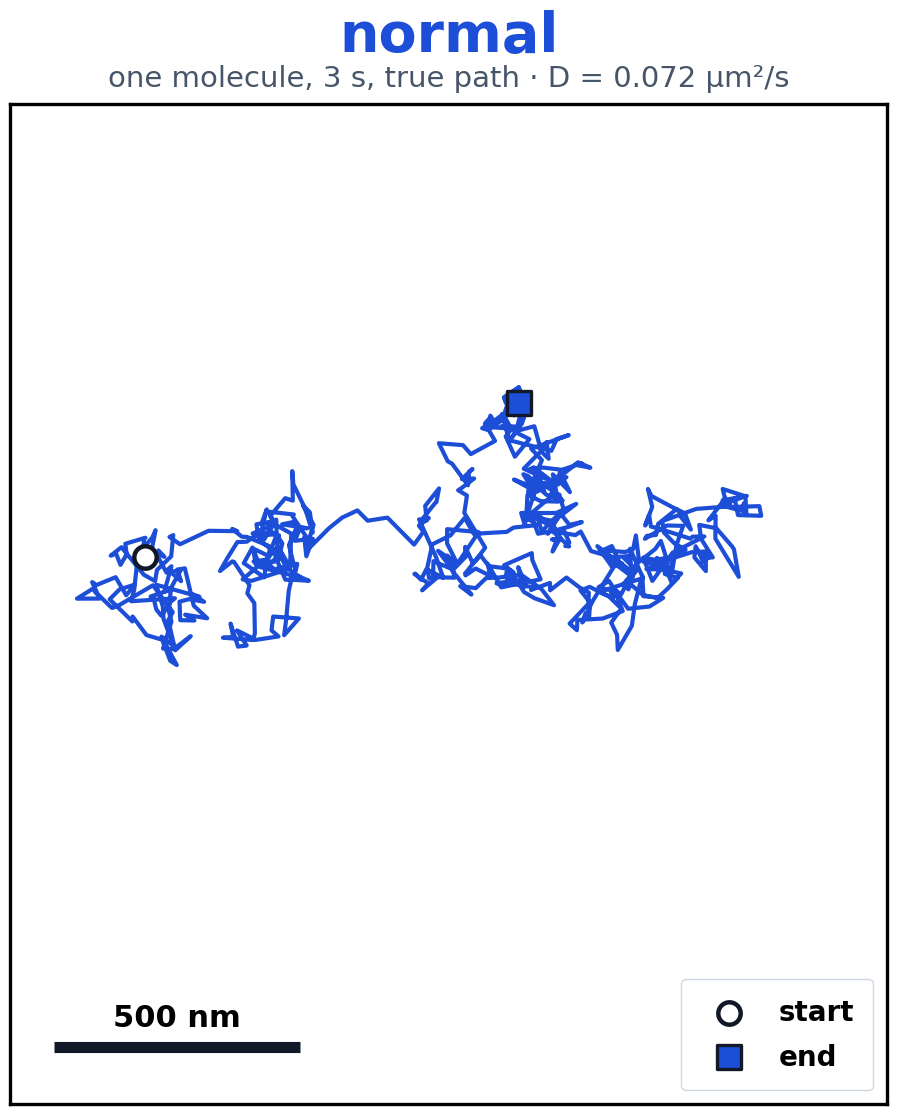

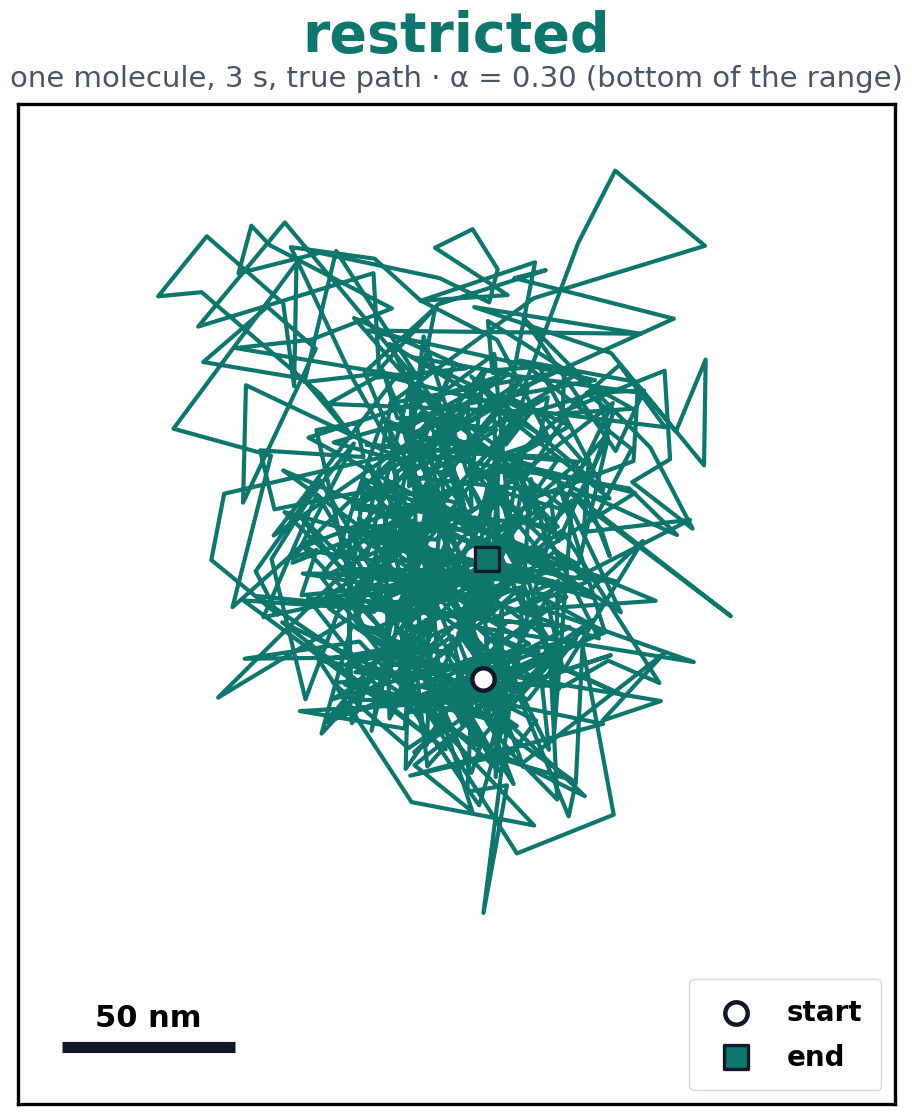

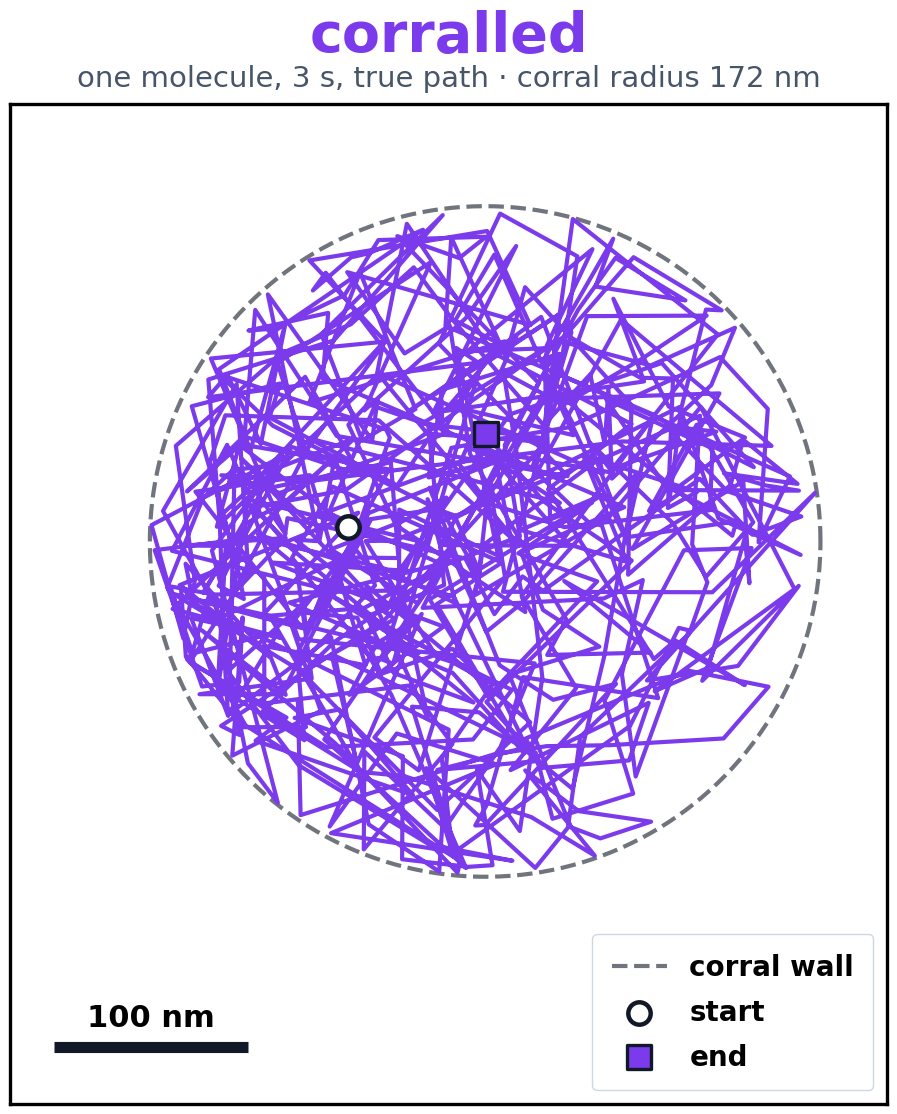

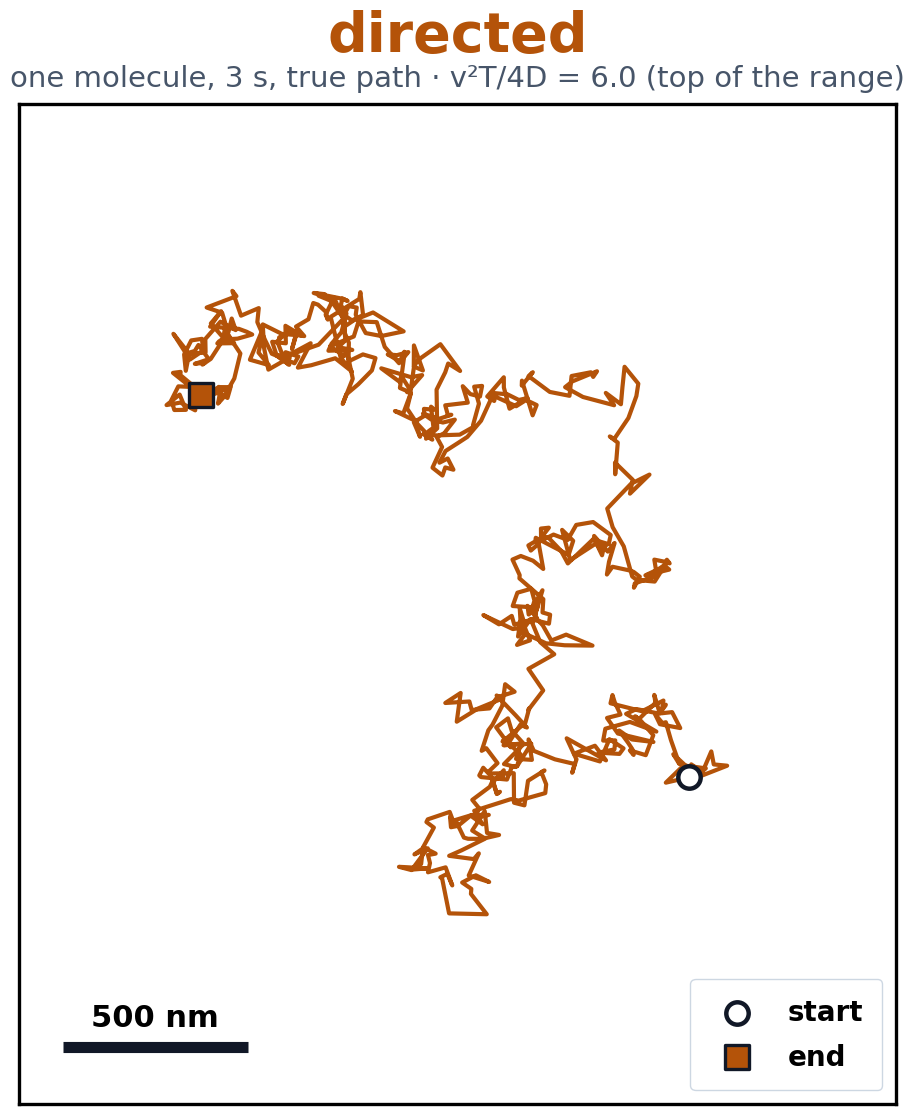

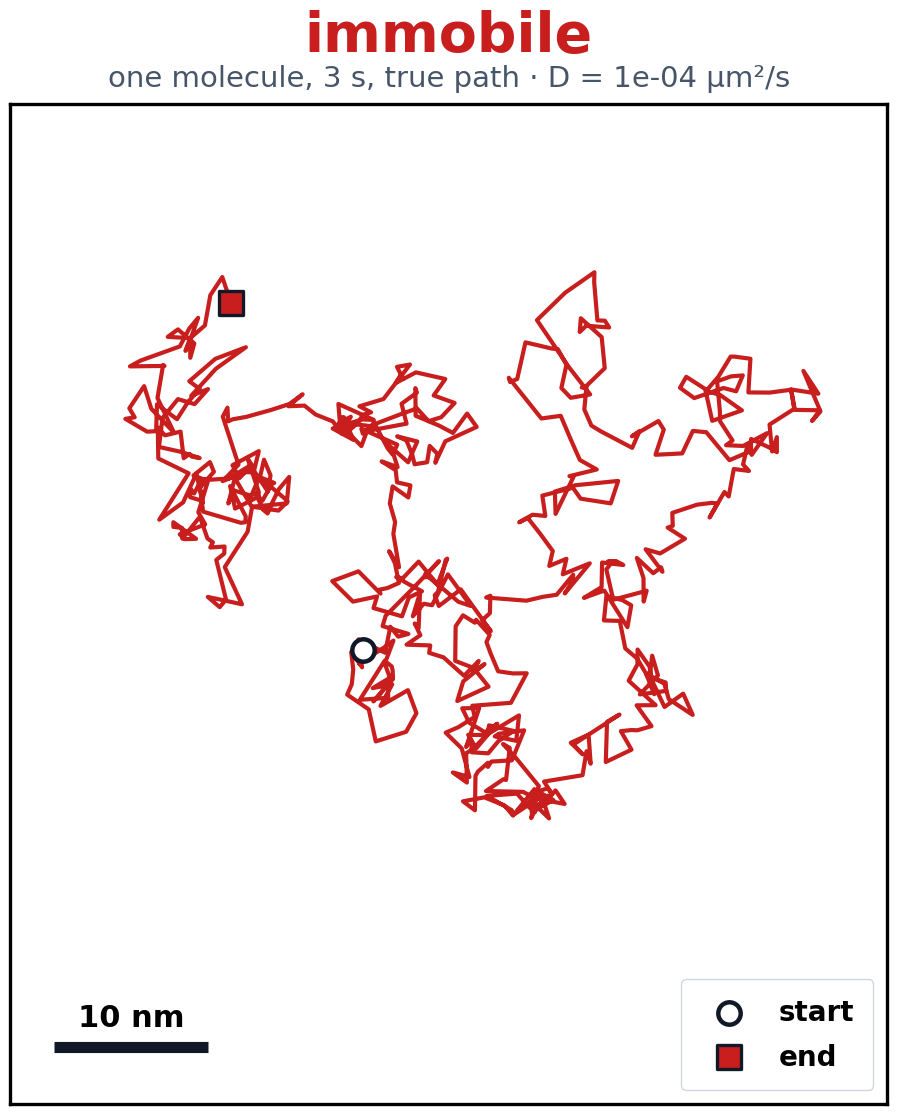

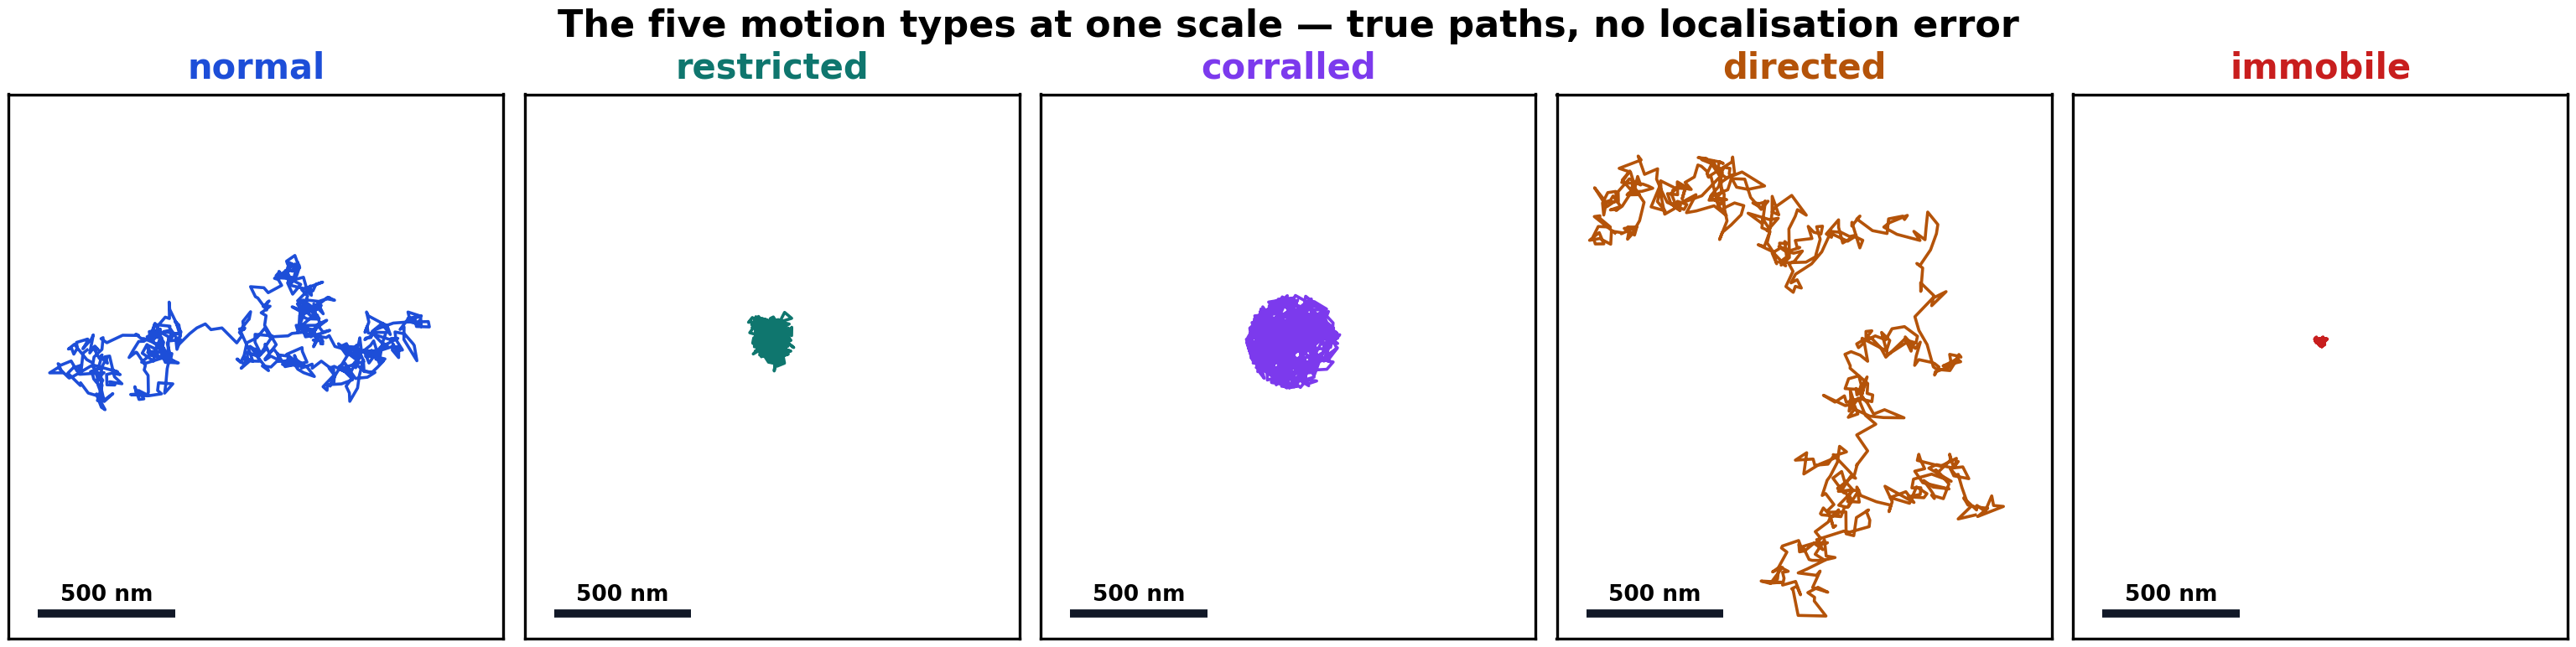

In [26]:
_rng = np.random.default_rng(SEED + 3)
N_SHOW = 600                      # 600 frames = 3 s, like a typical real track

# one molecule per class. The mean is kept as well as the path, because the
# drawing is centred on it and the corral wall has to be placed from the same
# point.
# For the gallery, each class is shown at the end of its range where the class
# is legible: directedness at the top, where the drift wins over the diffusion,
# and alpha at the bottom, where the subdiffusion is visible. At the other ends
# both look like ordinary diffusion - which is true of the classes and is why
# they are hard to tell apart, but it makes a poor picture of what they mean.
# The library still draws across the whole range; this is an illustration.
SHOWCASE = {"directed": ("directedness", DIRECTEDNESS[1]),
            "restricted": ("alpha", ALPHA_RANGE[0])}

tracks = {}
for k in CLASSES:
    p = draw_params(k, N_SHOW, DT_S, _rng, vary=False)
    if k in SHOWCASE:
        field, value = SHOWCASE[k]
        p[field] = value
        if k == "directed":          # the velocity follows from directedness
            p["v"] = float(np.sqrt(4 * p["D"] * value / (N_SHOW * DT_S)))
    P = PATH[k](N_SHOW, DT_S, p, _rng)
    tracks[k] = (P, p, P.mean(0))

def value_of(k, p):
    if k == "normal":     return f"D = {p['D']:.3f} \u00b5m\u00b2/s"
    if k == "restricted": return f"\u03b1 = {p['alpha']:.2f}"
    if k == "corralled":  return f"corral radius {1000*p['R']:.0f} nm"
    if k == "directed":   return f"v\u00b2T/4D = {p['directedness']:.1f}"
    return f"D = {p['D']:.0e} \u00b5m\u00b2/s"

SPAN = {}
for k in CLASSES:
    Praw, p, mu = tracks[k]
    C = 1000 * (Praw - mu)                       # nm, centred on the path
    reach = np.abs(C).max()
    if k == "corralled":                          # the wall has to fit too
        wx, wy = 1000 * (p["centre"] - mu)
        reach = max(reach, np.hypot(wx, wy) + 1000 * p["R"])
    SPAN[k] = 2 * reach
    m = reach * 1.18

    fig, ax = plt.subplots(figsize=(10.5, 11.4))
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(wx + 1000 * p["R"] * np.cos(th), wy + 1000 * p["R"] * np.sin(th),
                ls="--", lw=3, color="#111827", alpha=.6, zorder=2,
                label="corral wall")
    ax.plot(C[:, 0], C[:, 1], lw=3, color=COL[k], solid_joinstyle="round",
            zorder=3, label="_nolegend_")
    ax.scatter(C[0, 0], C[0, 1], s=260, marker="o", facecolor="white",
               edgecolor="#111827", lw=3.2, zorder=6, label="start")
    ax.scatter(C[-1, 0], C[-1, 1], s=290, marker="s", facecolor=COL[k],
               edgecolor="#111827", lw=2.4, zorder=6, label="end")

    # a strip below the data: the scale bar and the legend live there, so
    # nothing is ever drawn over the molecule
    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.28, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)

    raw = 2 * m * 0.24
    e = 10 ** np.floor(np.log10(raw))
    L = min([1, 2, 5, 10], key=lambda q: abs(q * e - raw)) * e
    yb = -m * 1.15
    ax.plot([-m * 0.90, -m * 0.90 + L], [yb, yb], lw=8, color="#111827",
            solid_capstyle="butt")
    ax.text(-m * 0.90 + L / 2, yb + m * 0.035, f"{L:.0f} nm", ha="center",
            va="bottom", fontsize=22, fontweight="bold")

    ax.set_title(k, fontsize=40, fontweight="bold", color=COL[k], pad=38)
    _edge = " (top of the range)" if k == "directed" else (
            " (bottom of the range)" if k == "restricted" else "")
    ax.text(0.5, 1.012,
            f"one molecule, 3 s, true path \u00b7 {value_of(k, p)}{_edge}",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=21,
            color="#475569")
    leg = ax.legend(loc="lower right", fontsize=20, frameon=True,
                    framealpha=.95, edgecolor="#cbd5e1", borderpad=.7,
                    labelspacing=.6, handletextpad=.8)
    for t in leg.get_texts():
        t.set_fontweight("bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"M9_{k}.png", bbox_inches="tight")

# --- and the five at one scale, so the classes can be compared --------------
fig, axes = plt.subplots(1, 5, figsize=(31, 7.6))
lim = 1000 * np.abs(tracks["normal"][0] - tracks["normal"][2]).max() * 1.2
for ax, k in zip(axes, CLASSES):
    Praw, p, mu = tracks[k]
    C = 1000 * (Praw - mu)
    ax.plot(C[:, 0], C[:, 1], lw=2.6, color=COL[k], solid_joinstyle="round")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim * 1.20, lim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)
    ax.set_title(k, fontsize=30, fontweight="bold", color=COL[k], pad=14)
    raw = 2 * lim * 0.26
    e = 10 ** np.floor(np.log10(raw))
    L = min([1, 2, 5, 10], key=lambda q: abs(q * e - raw)) * e
    yb = -lim * 1.10
    ax.plot([-lim * 0.88, -lim * 0.88 + L], [yb, yb], lw=7, color="#111827",
            solid_capstyle="butt")
    ax.text(-lim * 0.88 + L / 2, yb + lim * 0.035, f"{L:.0f} nm", ha="center",
            va="bottom", fontsize=19, fontweight="bold")
fig.suptitle("The five motion types at one scale \u2014 true paths, "
             "no localisation error", fontsize=32, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "M9_motion_types.png", bbox_inches="tight")

print("one molecule per motion type:")
for k in CLASSES:
    print(f"   M9_{k:11s}.png   spans {SPAN[k]:8.0f} nm")
print("   M9_motion_types.png   all five, one scale")

## 2b. The five motion types, drawn at stated values

Everywhere else the parameters are drawn from measured pools and differ track
to track, which is what a training set needs and what a figure cannot show.
Here each class appears once at a single named value, so the picture can be
described in a caption.

| type | model | value shown |
|---|---|---|
| normal | Brownian diffusion | D = 0.118 µm²/s — my measured median mobile D |
| restricted | fractional Gaussian noise | α = 0.60, inside my 0.3–0.9 range |
| corralled | reflecting circular boundary | R = 119 nm — my measured median corral radius |
| directed | Brownian diffusion plus a constant velocity | v²T/4D = 3.5, inside my 1–6 range |
| immobile | very slow Brownian motion | D = 10⁻⁷ µm²/s — the very-slow population |

**Imaging conditions:** 600 frames over 3 s at 5 ms per frame, with 40 nm
localisation error per coordinate.

Nothing in this section feeds the library, the reference or any result. It
only draws.

In [27]:
# --- the values this section shows, all in one place ------------------------
SHOW_N      = 600       # frames
SHOW_DT     = 0.005     # s, so 3 s in total
SHOW_SIGMA  = 0.040     # um per coordinate
SHOW_PARAMS = {
    "normal":     {"D": 0.118},
    "restricted": {"D": 0.118, "alpha": 0.60, "mechanism": "fgn"},
    "corralled":  {"D": 0.118, "R": 0.119, "centre": np.zeros(2)},
    "directed":   {"D": 0.118, "directedness": 3.5,
                   "v": float(np.sqrt(4 * 0.118 * 3.5 / (600 * 0.005))),
                   "theta": 0.6},
    "immobile":   {"D": 1e-7, "population": "still"},
}
SHOW_CAPTION = {
    "normal":     "Brownian diffusion, D = 0.118 um2/s, my measured median "
                  "mobile diffusion coefficient",
    "restricted": "fractional Gaussian noise with alpha = 0.60, inside my "
                  "0.3-0.9 range",
    "corralled":  "reflecting circular boundary of radius 119 nm, my measured "
                  "median corral radius",
    "directed":   "Brownian diffusion plus a constant velocity, directedness "
                  "v2T/4D = 3.5, inside my 1-6 range",
    "immobile":   "very slow Brownian motion, D = 1e-7 um2/s, the very-slow "
                  "population",
}
SHOW_VALUE = {"normal": "D = 0.118 \u00b5m\u00b2/s", "restricted": "\u03b1 = 0.60",
              "corralled": "R = 119 nm", "directed": "v\u00b2T/4D = 3.5",
              "immobile": "D = 10\u207b\u2077 \u00b5m\u00b2/s"}

_srng = np.random.default_rng(SEED + 404)
show = {}
for k in CLASSES:
    Pt = PATH[k](SHOW_N, SHOW_DT, SHOW_PARAMS[k], _srng)
    obs = Pt + _srng.normal(0, SHOW_SIGMA, Pt.shape)
    show[k] = (Pt - Pt.mean(0), obs - Pt.mean(0), SHOW_PARAMS[k])

print("the five motion types, at stated values")
print(f"600 frames over 3 s at {1000*SHOW_DT:.0f} ms, "
      f"{1000*SHOW_SIGMA:.0f} nm localisation error per coordinate")
print()
for k in CLASSES:
    T, O, _ = show[k]
    print(f"   {k:11s} true path spans {2000*np.abs(T).max():6.0f} nm, "
          f"recorded {2000*np.abs(O).max():6.0f} nm")

the five motion types, at stated values
600 frames over 3 s at 5 ms, 40 nm localisation error per coordinate

   normal      true path spans   1262 nm, recorded   1318 nm
   restricted  true path spans    801 nm, recorded    850 nm
   corralled   true path spans    262 nm, recorded    397 nm
   directed    true path spans   2110 nm, recorded   2178 nm
   immobile    true path spans      1 nm, recorded    272 nm



CAPTION (also saved to tables/visualisation_caption.txt)

The five motion types PiMoTIF simulates. Normal: Brownian diffusion, D = 0.118 um2/s, my
measured median mobile diffusion coefficient. Restricted: fractional Gaussian noise with
alpha = 0.60, inside my 0.3-0.9 range. Corralled: reflecting circular boundary of radius
119 nm, my measured median corral radius. Directed: Brownian diffusion plus a constant
velocity, directedness v2T/4D = 3.5, inside my 1-6 range. Immobile: very slow Brownian
motion, D = 1e-7 um2/s, the very-slow population. Imaging conditions: 600 frames over 3
s at 5 ms per frame, with 40 nm localisation error per coordinate.


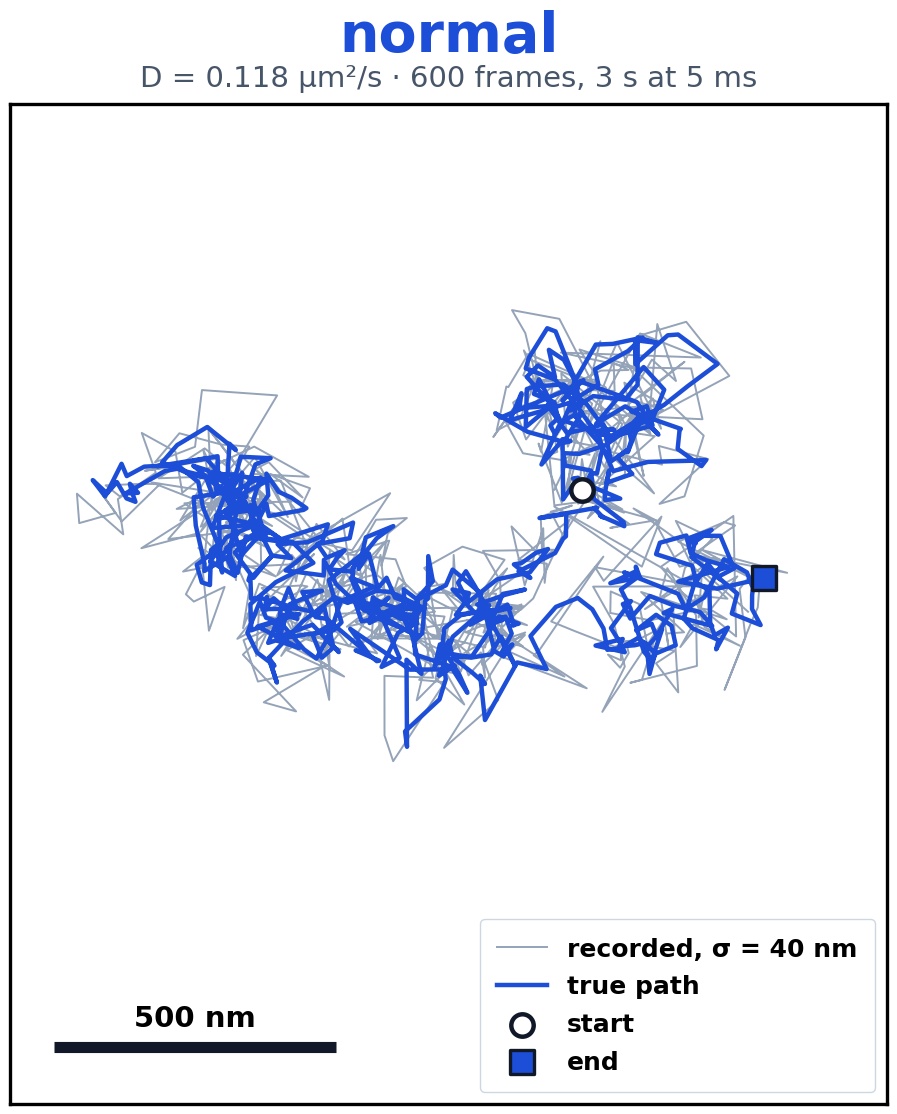

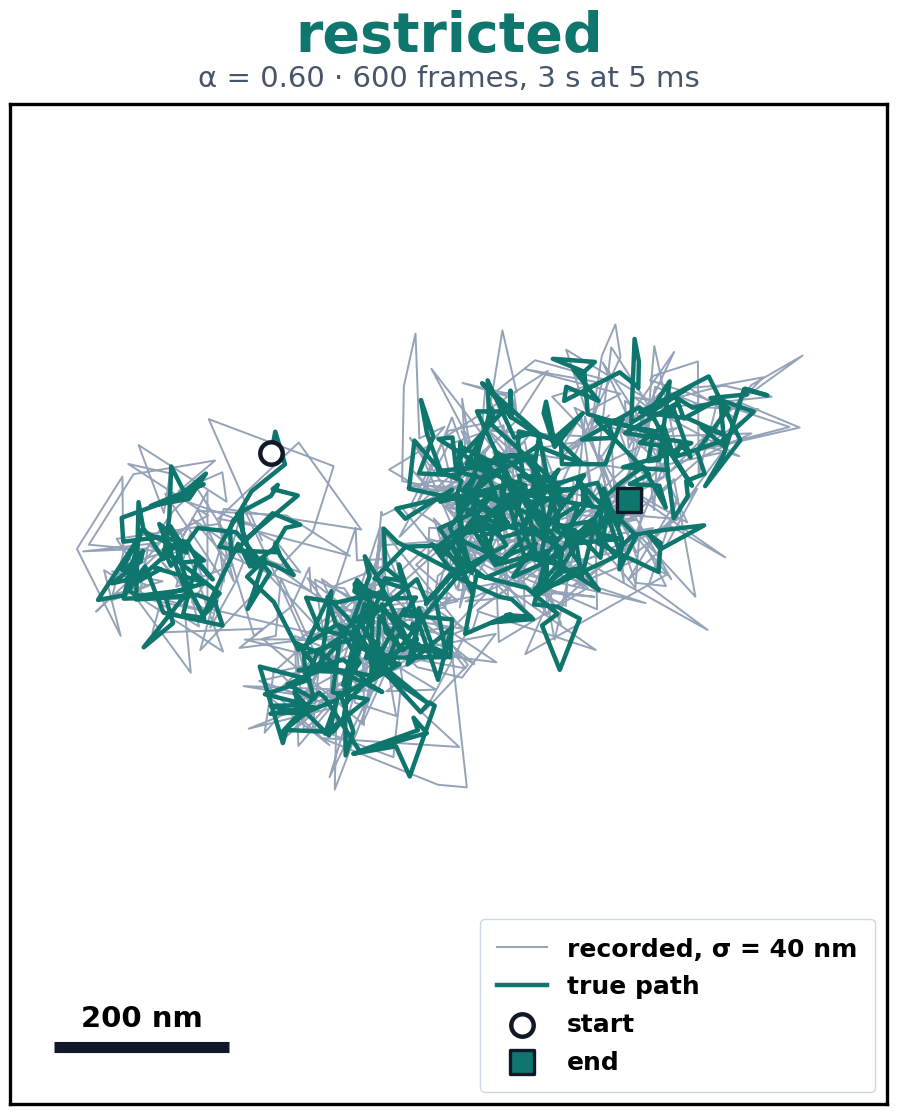

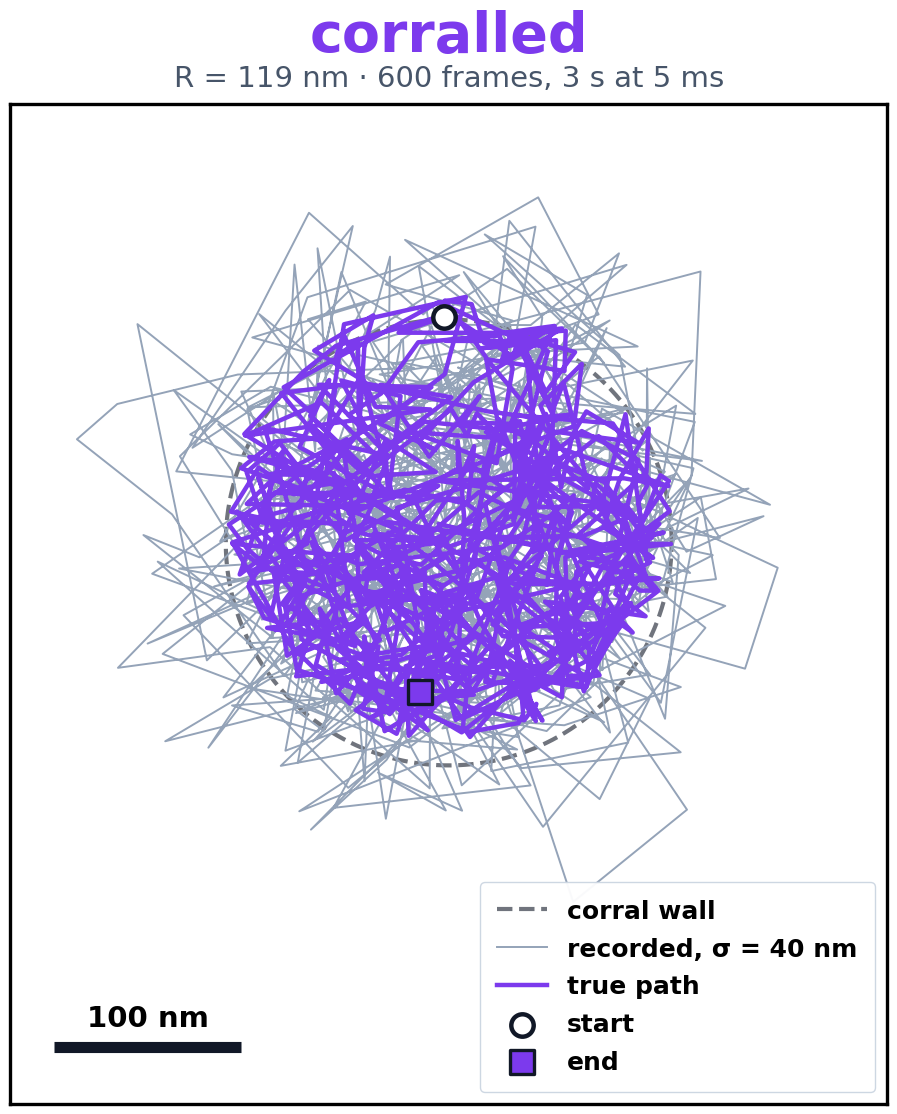

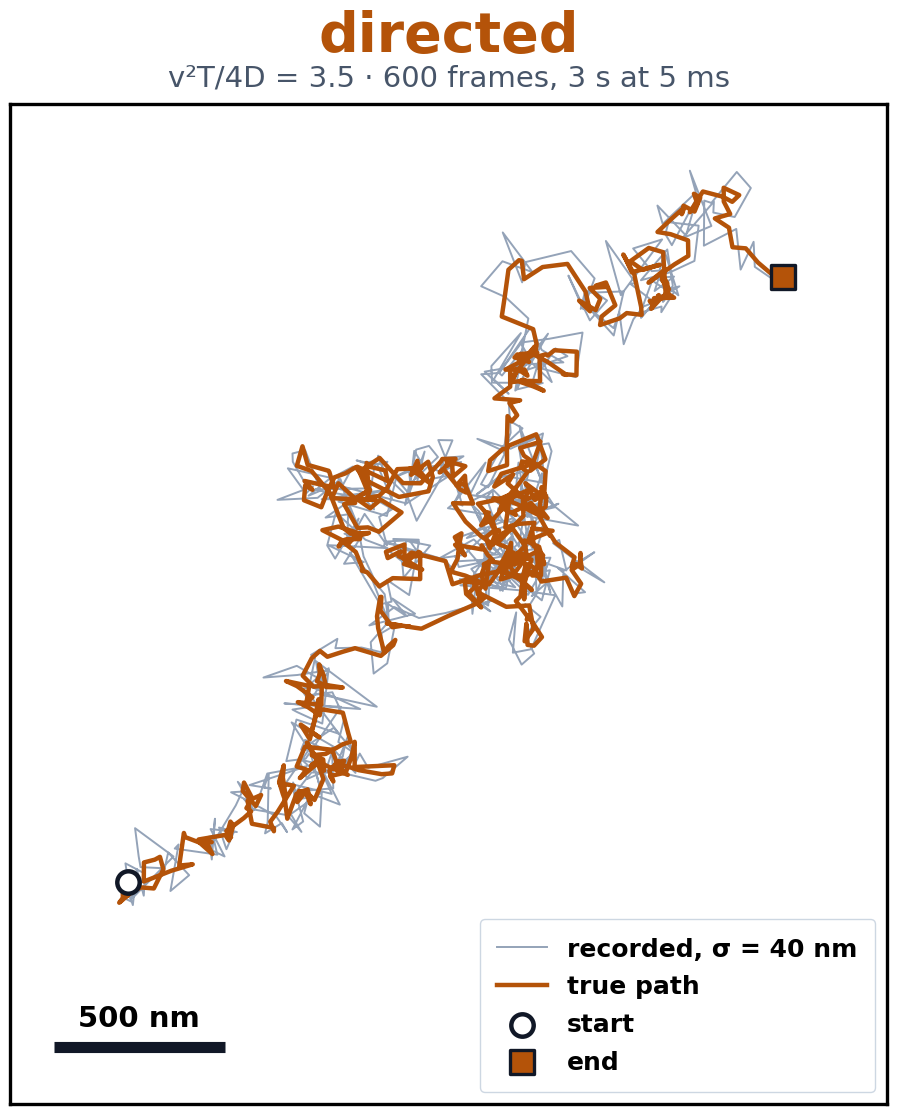

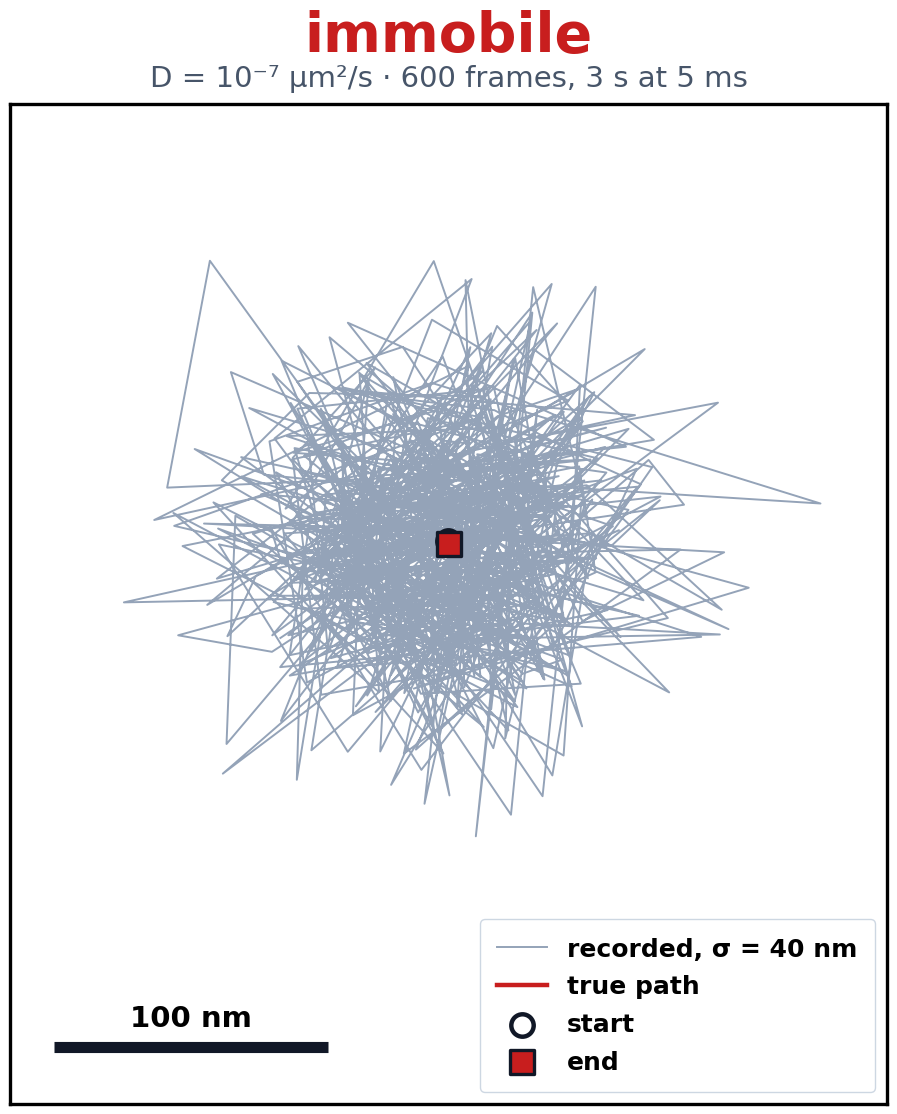

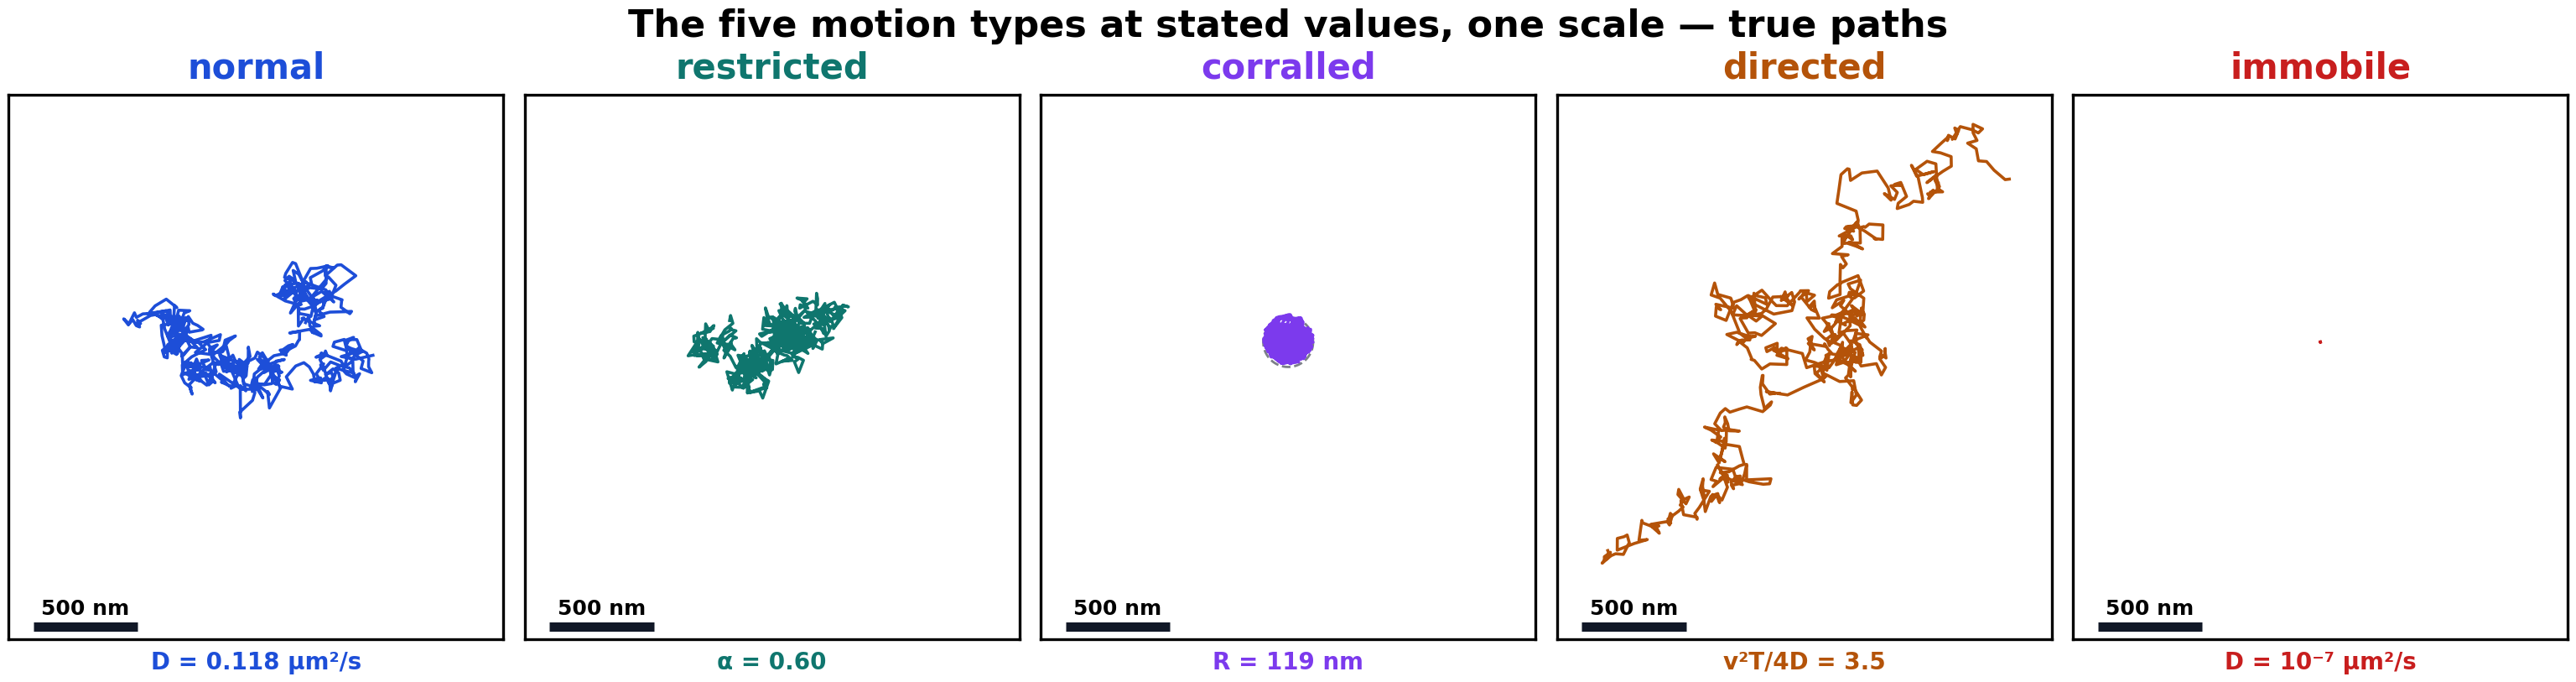

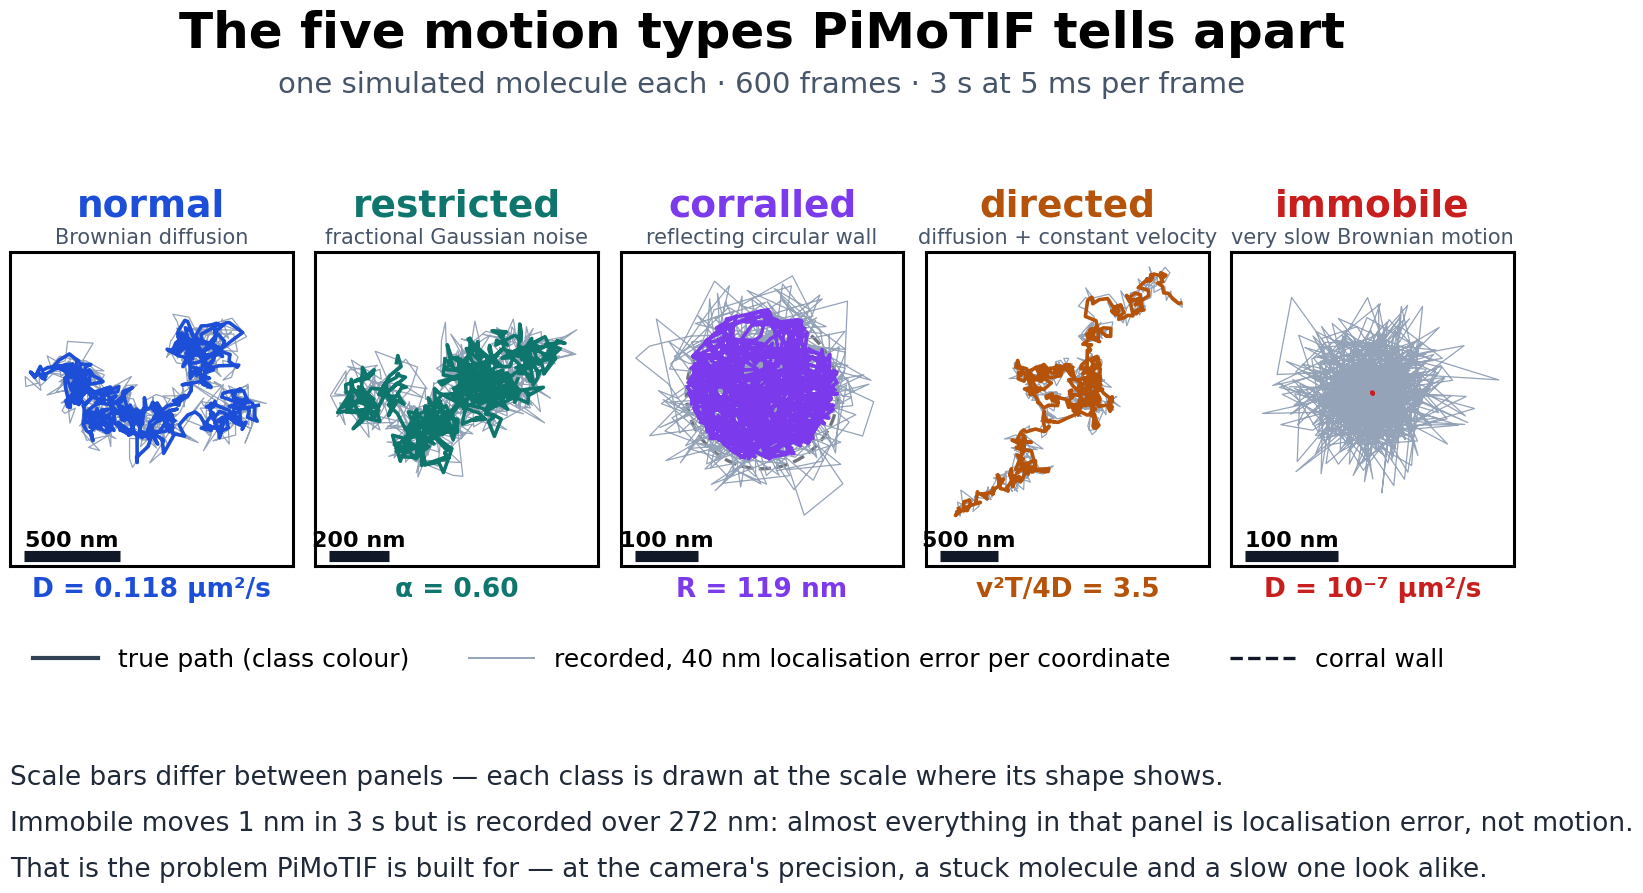

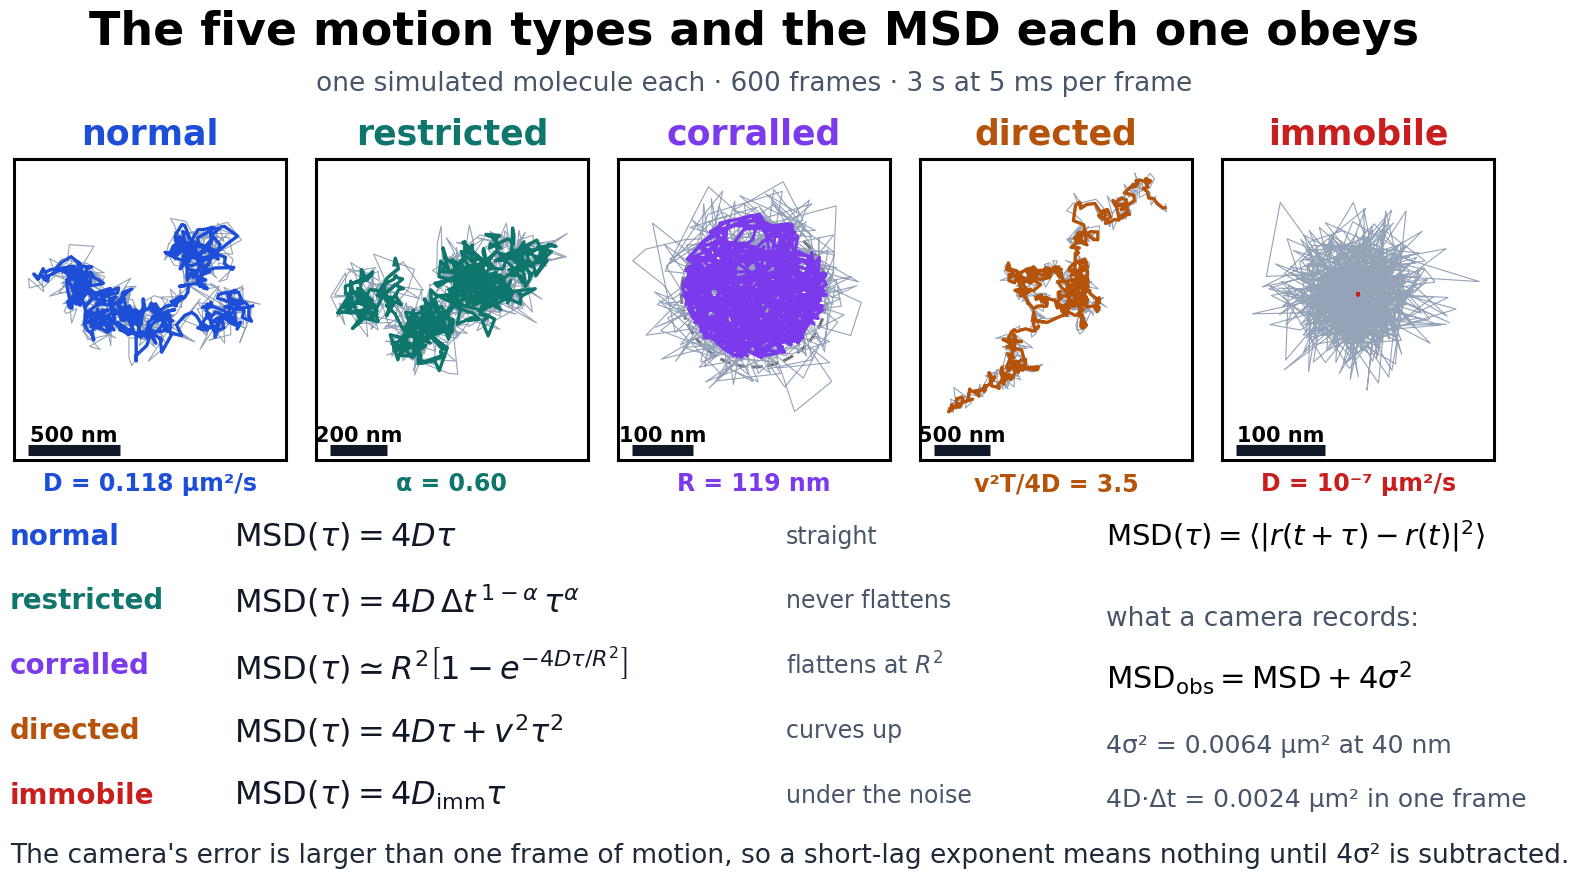

In [28]:
def _bar(ax, m, frac=0.24, fs=21):
    raw = 2 * m * frac
    e = 10 ** np.floor(np.log10(raw))
    L = min([1, 2, 5, 10], key=lambda q: abs(q * e - raw)) * e
    yb = -m * 1.15
    ax.plot([-m * 0.90, -m * 0.90 + L], [yb, yb], lw=8, color="#111827",
            solid_capstyle="butt")
    ax.text(-m * 0.90 + L / 2, yb + m * 0.035, f"{L:.0f} nm", ha="center",
            va="bottom", fontsize=fs, fontweight="bold")

for k in CLASSES:
    T, O, p = show[k]
    reach = 1000 * np.abs(O).max()
    if k == "corralled":
        reach = max(reach, 1000 * p["R"] * 1.1)
    m = reach * 1.18

    fig, ax = plt.subplots(figsize=(10.5, 11.4))
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=3, color="#111827", alpha=.6, zorder=2,
                label="corral wall")
    ax.plot(1000 * O[:, 0], 1000 * O[:, 1], lw=1.4, color="#94a3b8",
            zorder=2, label=f"recorded, \u03c3 = {1000*SHOW_SIGMA:.0f} nm")
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=3.2, color=COL[k],
            solid_joinstyle="round", zorder=3, label="true path")
    ax.scatter(1000 * T[0, 0], 1000 * T[0, 1], s=260, marker="o",
               facecolor="white", edgecolor="#111827", lw=3.2, zorder=6,
               label="start")
    ax.scatter(1000 * T[-1, 0], 1000 * T[-1, 1], s=290, marker="s",
               facecolor=COL[k], edgecolor="#111827", lw=2.4, zorder=6,
               label="end")

    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.28, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)
    _bar(ax, m)
    ax.set_title(k, fontsize=40, fontweight="bold", color=COL[k], pad=38)
    ax.text(0.5, 1.012, f"{SHOW_VALUE[k]} \u00b7 600 frames, 3 s at 5 ms",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=21,
            color="#475569")
    leg = ax.legend(loc="lower right", fontsize=18, frameon=True,
                    framealpha=.95, edgecolor="#cbd5e1", borderpad=.7,
                    labelspacing=.55)
    for t in leg.get_texts():
        t.set_fontweight("bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"V_{k}.png", bbox_inches="tight")

# the five together, at one scale, true paths only
fig, axes = plt.subplots(1, 5, figsize=(31, 7.6))
# the widest of the five sets the scale, so nothing is cut off
lim = 1.12 * max(1000 * np.abs(show[k][0]).max() for k in CLASSES)
for ax, k in zip(axes, CLASSES):
    T, _, p = show[k]
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 300)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=2, color="#111827", alpha=.55)
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=2.6, color=COL[k],
            solid_joinstyle="round")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim * 1.20, lim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)
    ax.set_title(k, fontsize=30, fontweight="bold", color=COL[k], pad=14)
    ax.text(0.5, -0.02, SHOW_VALUE[k], transform=ax.transAxes, ha="center",
            va="top", fontsize=20, fontweight="bold", color=COL[k])
    _bar(ax, lim, frac=0.26, fs=18)
fig.suptitle("The five motion types at stated values, one scale \u2014 true paths",
             fontsize=32, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "V_motion_types.png", bbox_inches="tight")

# --- and one 16:9 slide: all five, each at its own scale, explained ---------
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

MODEL = {"normal":     "Brownian diffusion",
         "restricted": "fractional Gaussian noise",
         "corralled":  "reflecting circular wall",
         "directed":   "diffusion + constant velocity",
         "immobile":   "very slow Brownian motion"}

fig = plt.figure(figsize=(16, 9), facecolor="white")
gs = fig.add_gridspec(2, 5, height_ratios=[1.0, 0.34], hspace=0.02,
                      wspace=0.08, left=0.03, right=0.97, top=0.83,
                      bottom=0.04)
fig.text(0.5, 0.955, "The five motion types PiMoTIF tells apart",
         ha="center", va="center", fontsize=36, fontweight="bold")
fig.text(0.5, 0.898,
         "one simulated molecule each · 600 frames · 3 s at 5 ms per frame",
         ha="center", va="center", fontsize=21, color="#475569")

for j, k in enumerate(CLASSES):
    T, O, p = show[k]
    ax = fig.add_subplot(gs[0, j])
    reach = 1000 * np.abs(O).max()
    if k == "corralled":
        reach = max(reach, 1000 * p["R"] * 1.1)
    m = reach * 1.12
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=2.4, color="#111827", alpha=.6, zorder=2)
    ax.plot(1000 * O[:, 0], 1000 * O[:, 1], lw=0.9, color="#94a3b8", zorder=2)
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=2.6, color=COL[k],
            solid_joinstyle="round", zorder=3)
    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.22, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    _bar(ax, m, frac=0.26, fs=16)
    ax.set_title(k, fontsize=27, fontweight="bold", color=COL[k], pad=26)
    ax.text(0.5, 1.015, MODEL[k], transform=ax.transAxes, ha="center",
            va="bottom", fontsize=15, color="#475569")
    ax.text(0.5, -0.035, SHOW_VALUE[k], transform=ax.transAxes, ha="center",
            va="top", fontsize=19, fontweight="bold", color=COL[k])

axb = fig.add_subplot(gs[1, :]); axb.axis("off")
axb.set_xlim(0, 1); axb.set_ylim(0, 1)
axb.legend(handles=[
    Line2D([], [], color="#334155", lw=3, label="true path (class colour)"),
    Line2D([], [], color="#94a3b8", lw=1.4,
           label="recorded, 40 nm localisation error per coordinate"),
    Line2D([], [], color="#111827", lw=2.4, ls="--", label="corral wall")],
    loc="upper left", bbox_to_anchor=(0.0, 1.30), ncol=3, frameon=False,
    fontsize=18, handlelength=2.6, columnspacing=2.4)

_im_true = 2000 * np.abs(show["immobile"][0]).max()
_im_rec = 2000 * np.abs(show["immobile"][1]).max()
for y, txt in [
    (0.52, "Scale bars differ between panels — each class is drawn at the "
           "scale where its shape shows."),
    (0.26, f"Immobile moves {_im_true:.0f} nm in 3 s but is recorded over "
           f"{_im_rec:.0f} nm: almost everything in that panel is localisation "
           "error, not motion."),
    (0.00, "That is the problem PiMoTIF is built for — at the camera's "
            "precision, a stuck molecule and a slow one look alike.")]:
    axb.text(0.0, y, txt, fontsize=19, color="#1f2937", va="top")

fig.savefig(FIG_DIR / "V_slide.png", dpi=200, facecolor="white",
            bbox_inches="tight")

# --- the same slide, with the MSD each class obeys --------------------------
EQN = {
    "normal":     r"$\mathrm{MSD}(\tau)=4D\tau$",
    "restricted": r"$\mathrm{MSD}(\tau)=4D\,\Delta t^{\,1-\alpha}\,\tau^{\alpha}$",
    "corralled":  r"$\mathrm{MSD}(\tau)\simeq R^{2}\left[1-e^{-4D\tau/R^{2}}\right]$",
    "directed":   r"$\mathrm{MSD}(\tau)=4D\tau+v^{2}\tau^{2}$",
    "immobile":   r"$\mathrm{MSD}(\tau)=4D_{\mathrm{imm}}\tau$",
}
SAYS = {"normal":     "straight",
        "restricted": "never flattens",
        "corralled":  r"flattens at $R^{2}$",
        "directed":   "curves up",
        "immobile":   "under the noise"}

fig = plt.figure(figsize=(16, 9), facecolor="white")
gs = fig.add_gridspec(1, 5, wspace=0.08, left=0.035, right=0.965,
                      top=0.805, bottom=0.47)
fig.text(0.5, 0.945, "The five motion types and the MSD each one obeys",
         ha="center", va="center", fontsize=33, fontweight="bold")
fig.text(0.5, 0.888, "one simulated molecule each " + "\u00b7" +
         " 600 frames " + "\u00b7" + " 3 s at 5 ms per frame",
         ha="center", va="center", fontsize=19, color="#475569")

for j, k in enumerate(CLASSES):
    T, O, p = show[k]
    ax = fig.add_subplot(gs[0, j])
    reach = 1000 * np.abs(O).max()
    if k == "corralled":
        reach = max(reach, 1000 * p["R"] * 1.1)
    m = reach * 1.12
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=2.2, color="#111827", alpha=.6, zorder=2)
    ax.plot(1000 * O[:, 0], 1000 * O[:, 1], lw=0.8, color="#94a3b8", zorder=2)
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=2.4, color=COL[k],
            solid_joinstyle="round", zorder=3)
    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.22, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    _bar(ax, m, frac=0.26, fs=15)
    ax.set_title(k, fontsize=25, fontweight="bold", color=COL[k], pad=10)
    ax.text(0.5, -0.04, SHOW_VALUE[k], transform=ax.transAxes, ha="center",
            va="top", fontsize=17, fontweight="bold", color=COL[k])

# one line per class, in the class colour: name, equation, what it looks like
y = 0.385
for k in CLASSES:
    fig.text(0.035, y, k, fontsize=20, fontweight="bold", color=COL[k],
             va="center")
    fig.text(0.175, y, EQN[k], fontsize=23, color="#111827", va="center")
    fig.text(0.520, y, SAYS[k], fontsize=17, color="#475569", va="center")
    y -= 0.072

fig.text(0.72, 0.385,
         r"$\mathrm{MSD}(\tau)=\langle|r(t+\tau)-r(t)|^{2}\rangle$",
         fontsize=21, va="center")
fig.text(0.72, 0.293, "what a camera records:", fontsize=19, va="center",
         color="#475569")
fig.text(0.72, 0.228,
         r"$\mathrm{MSD}_{\mathrm{obs}}=\mathrm{MSD}+4\sigma^{2}$",
         fontsize=22, va="center")
fig.text(0.72, 0.152, "4" + "\u03c3" + "\u00b2" +
         f" = {4*SHOW_SIGMA**2:.4f} " + "\u00b5m\u00b2" +
         f" at {1000*SHOW_SIGMA:.0f} nm", fontsize=18, color="#475569",
         va="center")
fig.text(0.72, 0.092, "4D" + "\u00b7" + "\u0394t" +
         f" = {4*0.118*SHOW_DT:.4f} " + "\u00b5m\u00b2" + " in one frame",
         fontsize=18, color="#475569", va="center")

fig.text(0.035, 0.030, "The camera's error is larger than one frame of motion, "
         "so a short-lag exponent means nothing until 4" + "\u03c3\u00b2" +
         " is subtracted.", fontsize=19, color="#1f2937", va="center")

fig.savefig(FIG_DIR / "V_slide_equations.png", dpi=200, facecolor="white",
            bbox_inches="tight")

CAPTION = ("The five motion types PiMoTIF simulates. "
           + " ".join(f"{k.capitalize()}: {SHOW_CAPTION[k]}." for k in CLASSES)
           + f" Imaging conditions: {SHOW_N} frames over "
             f"{SHOW_N*SHOW_DT:.0f} s at {1000*SHOW_DT:.0f} ms per frame, with "
             f"{1000*SHOW_SIGMA:.0f} nm localisation error per coordinate.")
(TAB_DIR / "visualisation_caption.txt").write_text(CAPTION, encoding="utf-8")
print()
print("CAPTION (also saved to tables/visualisation_caption.txt)")
print()
import textwrap
print(textwrap.fill(CAPTION, 88))

## 3. The instrument — turning motion into a recording

**Blinking is measured, not modelled.** Every simulated track inherits a real
track's on/off pattern, so the dark states have my dye's statistics rather
than a model of them. I only ever *thin* a pattern to make a molecule blink
more; adding a detection where the real molecule was dark would be inventing
photophysics I have not observed.

**Re-thinning matters more than it looks.** Longer tracks have higher duty in
my data (r = +0.39), because a molecule that blinks a lot never survives my
200-detection filter. So a window cut from a long donor inherits that donor's
unusually clean blinking, and without re-thinning every short track in the
library would be unrealistically tidy.

**A molecule keeps moving while it is dark.** The motion is generated over
every frame a track spans, including the invisible ones, and only then are the
dark frames discarded. Generating only the visible frames would make every gap
a freeze, and the classifier would learn that blinking means stopping.

**Localisation error belongs to the molecule, not the recording.** Frame time,
density, exposure threshold and drift are properties of a movie and are drawn
once per movie. Precision is not: within one of my fields tracks span 11–95 nm
while the field medians span only 32–49, so most of the variation is how
bright each molecule is.

**Duty comes from the pool that matches the class.** My fixed cells blink at
0.714 and my live ones at 0.76, so the immobile reference draws from the fixed
distribution and the four mobile classes from the live one.

Blinking from a real donor pattern, re-recorded at this track's frame time,
cut to length, re-thinned, then drift and localisation error.

**Re-thinning matters more than it looks.** Longer tracks have higher duty in
my data (r = +0.39), because a molecule that blinks a lot never survives my
200-detection filter. So a window cut from a long donor inherits that donor's
unusually clean blinking, and without re-thinning every short track in the
library would be unrealistically tidy.

In [29]:
def reframe(obs, dt, exposure_min):
    """Draw a scale bar about a third of the panel wide."""
    obs = np.asarray(obs, np.int64)
    if dt <= DT_S * 1.0001 or obs.size == 0:
        return obs
    span = int(obs[-1]) + 1
    on = np.zeros(span); on[obs] = 1.0
    c = np.concatenate([[0.0], np.cumsum(on)])
    def upto(x):
        x = np.clip(x, 0.0, float(span))
        i = np.clip(np.floor(x).astype(np.int64), 0, span - 1)
        return c[i] + (x - i) * on[i]
    k = dt / DT_S
    n_new = int(np.floor(span / k))
    if n_new < 2:
        return np.array([], np.int64)
    e = np.arange(n_new + 1) * k
    frac = (upto(e[1:]) - upto(e[:-1])) / k
    return np.flatnonzero(frac >= exposure_min).astype(np.int64)

def window_of(idx, n_target, rng):
    """Cut a contiguous run of about n_target detections. None keeps it whole.

    The reference passes None: one real donor carries its length, its duty and
    its gap pattern together, and cutting it apart loses the correlations
    between them. The library and the fixed-length windows still cut, because
    there the point is to reach lengths my own experiment never produced.
    """
    idx = np.asarray(idx, np.int64)
    if n_target is None or idx.size <= n_target:
        return idx - (idx[0] if idx.size else 0)
    s = int(rng.integers(0, idx.size - n_target + 1))
    w = idx[s:s + n_target]
    return w - w[0]

def thin_to_duty(idx, duty_target, rng):
    """Drop detections until the pattern blinks as much as asked. Never adds."""
    idx = np.asarray(idx, np.int64)
    if idx.size <= MIN_SIM_DET:
        return idx
    span = int(idx[-1] - idx[0] + 1)
    if duty_target >= idx.size / span:
        return idx
    n_keep = int(max(MIN_SIM_DET, round(duty_target * span)))
    if n_keep >= idx.size:
        return idx
    mid = rng.choice(idx[1:-1], size=n_keep - 2, replace=False)
    return np.sort(np.concatenate([idx[:1], mid, idx[-1:]])).astype(np.int64)

# the direction my stage actually goes, field by field. Drawing from these
# reproduces the anisotropy - 46 of 52 fields creeping the same way in x -
# without my having to impose it.
DRIFT_ANGLES = np.arctan2(DRIFT_TAB.dy_um.to_numpy(),
                          DRIFT_TAB.dx_um.to_numpy())
N_FIELDS = 40          # simulated movies to spread the tracks across
_field_cache = {}

def field_drift(field_id, n_frames, scale):
    """One drift trajectory per movie, cached so its tracks share it."""
    key = (int(field_id), int(n_frames), round(float(scale), 4))
    if key not in _field_cache:
        r = np.random.default_rng(SEED + 9973 * key[0])
        total = float(r.choice(DRIFT)) * scale
        th = float(r.choice(DRIFT_ANGLES))
        tt = np.arange(n_frames)[:, None] / max(n_frames, 1)
        ramp = (total * (1 - WANDER_FRAC)
                * np.array([np.cos(th), np.sin(th)]) * tt)
        w = np.cumsum(r.normal(0, 1, (n_frames, 2)), axis=0)
        w = w / max(np.abs(w).max(), 1e-9) * total * WANDER_FRAC
        _field_cache[key] = (ramp + w, total, th)
    return _field_cache[key]

def drift_of(span, f0, rng, n_frames, scale=None, field_id=None):
    """The slice of this movie's drift over the frames a track was alive."""
    scale = 1.0 if scale is None else scale
    if field_id is None:                      # no field given: its own movie
        field_id = int(rng.integers(1_000_000))
    traj, total, th = field_drift(field_id, n_frames, scale)
    f0 = int(min(f0, max(n_frames - span, 0)))     # never run off the end
    sl = traj[f0:f0 + span]
    if sl.shape[0] < span:                         # span longer than the movie
        sl = np.vstack([sl, np.repeat(sl[-1:], span - sl.shape[0], axis=0)])
    return sl - sl[0], total                  # relative to where it started

_rng = np.random.default_rng(SEED)
rows = []
for dt_, exp_ in [(0.005, 0.5), (0.010, 0.5), (0.025, 0.3), (0.025, 0.5),
                  (0.025, 0.7), (0.050, 0.5), (0.100, 0.5)]:
    n_det, duty, lost = [], [], 0
    for i in range(len(PAT_LIVE)):
        r = reframe(PAT_LIVE[i], dt_, exp_)
        if r.size < MIN_SIM_DET:
            lost += 1; continue
        n_det.append(r.size); duty.append(r.size / (r[-1] - r[0] + 1))
    rows.append({"frame time": f"{1000*dt_:.0f} ms", "threshold": exp_,
                 "detections": f"{np.median(n_det):.0f}",
                 "duty": f"{np.median(duty):.2f}",
                 "patterns lost": f"{100*lost/len(PAT_LIVE):.1f}%"})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nmy real live tracks: median {LIVE.n_det.median():.0f} detections, "
      f"duty {LIVE.duty.median():.2f}")
print("The 5 ms row must match those exactly - at my own frame rate reframe()")
print("does nothing and the threshold never fires. Slower imaging makes tracks")
print("look CLEANER, because a short blink inside a long exposure dims the")
print("frame instead of removing it.")

frame time  threshold detections duty patterns lost
      5 ms        0.5        458 0.76          0.0%
     10 ms        0.5        272 0.88          0.0%
     25 ms        0.3        111 0.92          0.0%
     25 ms        0.5         96 0.85          0.0%
     25 ms        0.7         77 0.71          0.9%
     50 ms        0.5         51 0.91          0.2%
    100 ms        0.5         26 0.94          2.7%

my real live tracks: median 458 detections, duty 0.76
The 5 ms row must match those exactly - at my own frame rate reframe()
does nothing and the threshold never fires. Slower imaging makes tracks
look CLEANER, because a short blink inside a long exposure dims the
frame instead of removing it.


### The two tracking artefacts

**Unresolved pair:** two molecules closer than the microscope can separate.
The fitter sees one spot at their centroid, so the "molecule" moves whenever
either one does. The track stays **compact**.

**Mis-link:** the tracker loses one molecule and picks up a different one
nearby. The track jumps and carries on, making a **stretched** shape.

My field simulation predicted 1.5% mis-linking at my density. My own fixed
data says about 14%: that is the rate at which one mechanism reproduces both
the 6.91% stretched tracks and the 2.73 95th percentile, and nothing else
moved either number. The likely reason the field simulation was low is that my
tracker bridges up to 19 dark frames, so a neighbour has nineteen chances to
wander within the jump limit, not one.

**This matters beyond the simulation.** My cutoff *is* that 95th percentile,
so it is set largely by tracking artefacts rather than by how immobile
molecules behave — which makes 23.4% an overestimate.

In [30]:
# Tracking-artifact rates are calibrated from the experimental analysis above.
# Mis-linking: approximately 14% at the measured median density.
MISLINK_AT_MINE = 0.14

# Unresolved-pair proxy: fraction of fixed tracks >1.5x the single-molecule
# brightness mode, calculated in Cell 27. This is not a definitive pair count.
# PAIR_AT_MINE was calculated from fixed-track brightness in Cell 27.

_K = -np.log1p(-MISLINK_AT_MINE) / my_density
_KP = -np.log1p(-PAIR_AT_MINE) / my_density

def mislink_rate(density):
    """Density-dependent mis-link rate, anchored at the measured density."""
    return float(np.clip(1 - np.exp(-_K * density), 0, 0.9))

def pair_rate_measured(density):
    """Unresolved-pair proxy, extrapolated from the measured density."""
    return float(np.clip(1 - np.exp(-_KP * density), 0, 0.9))

def pair_rate(density, vary):
    """Measured proxy for the reference, a wide stress-test range for the library."""
    if not vary:
        return pair_rate_measured(density)
    lo, hi = UNRESOLVED
    w = np.clip(
        (np.log(density) - np.log(DENSITY_RANGE[0])) /
        (np.log(DENSITY_RANGE[1]) - np.log(DENSITY_RANGE[0])), 0, 1
    )
    return float(lo + w * (hi - lo))

def add_pair(fr, xy, kind, dt, rng, vary=True):
    """Return the centroid of two unresolved simulated molecules."""
    span = int(fr[-1] - fr[0] + 1)
    p2 = draw_params(kind, span, dt, rng, vary=vary)
    other = PATH[kind](span, dt, p2, rng)[fr - fr[0]]
    theta = rng.uniform(0, 2 * np.pi)
    separation = PSF_R * np.sqrt(rng.random())
    other = other - other[0] + xy[0] + separation * np.array(
        [np.cos(theta), np.sin(theta)]
    )
    return 0.5 * (xy + other)

def add_mislink(fr, xy, rng):
    """Insert one tracker-like jump no larger than the linker limit."""
    n = xy.shape[0]
    if n < 20:
        return xy, np.nan
    cut = int(rng.integers(int(0.25 * n), int(0.75 * n)))
    theta = rng.uniform(0, 2 * np.pi)
    jump = R_LINK * np.sqrt(rng.random()) * np.array(
        [np.cos(theta), np.sin(theta)]
    )
    out = xy.copy()
    out[cut:] = out[cut:] - out[cut] + out[cut - 1] + jump
    return out, cut

print(f"Median measured density: {my_density:.3f} puncta/um²")
print(f"Mis-link rate at this density: {100*mislink_rate(my_density):.1f}%")
print(f"Brightness-based unresolved-pair proxy: {100*PAIR_AT_MINE:.2f}%")
print(f"Field-simulation pair prediction at this density: "
      f"{100*pair_rate_fieldsim(my_density):.2f}%")
print(f"Library pair stress-test range: {100*UNRESOLVED[0]:.1f}-"
      f"{100*UNRESOLVED[1]:.1f}%")
print("Note: the density extrapolations are assumptions, not measured curves.")

Median measured density: 0.052 puncta/um²
Mis-link rate at this density: 14.0%
Brightness-based unresolved-pair proxy: 0.79%
Field-simulation pair prediction at this density: 0.08%
Library pair stress-test range: 0.5-25.0%
Note: the density extrapolations are assumptions, not measured curves.


### Assembling one complete track

The order follows what happens in a real experiment. Steps 5 and 6 are in that
order on purpose: a molecule keeps moving while it is dark, so the position
after a gap has to be where it drifted to. Generating only the visible frames
would make every gap a freeze, and the classifier would learn that blinking
means stopping.

In [31]:
def make_track(kind, dt, n_target, duty_target, sigma, exposure_min,
               drift_scale, density, rng, vary=True, patterns=None,
               n_frames=None, field_id=None):
    """One simulated track: motion, blinking, drift, noise and artefacts.

    1. borrow a real molecule's blinking pattern   6. keep the visible frames
    2. re-record it at this track's frame time     7. add the stage's drift
    3. cut a window of the length wanted           8. unresolved pair, if any
    4. re-thin it to the duty cycle wanted         9. add localisation error
    5. generate the motion over the frames spanned 10. mis-link, if any
    """
    n_frames = n_frames or int(round(MOVIE_S / dt))
    patterns = patterns if patterns is not None else PAT_LIVE
    # keep looking for a donor long enough to cut a window from, and fall back
    # to the longest seen rather than the last tried
    best = None
    for _ in range(40):
        obs = patterns[int(rng.integers(len(patterns)))]
        obs = reframe(obs, dt, exposure_min)
        if obs.size < MIN_SIM_DET:
            continue
        if best is None or obs.size > best.size:
            best = obs
        if obs.size >= (n_target if n_target is not None else 0):
            break
    if best is None:
        return None
    obs = window_of(best, n_target, rng)
    obs = thin_to_duty(obs, duty_target, rng)
    if obs.size < MIN_SIM_DET:
        return None

    span = int(obs[-1] - obs[0] + 1)
    f0 = int(rng.integers(0, max(1, n_frames - span)))
    fr = (obs - obs[0]).astype(np.int64)

    p = draw_params(kind, span, dt, rng, vary=vary)
    true = PATH[kind](span, dt, p, rng)
    drift, drift_total = drift_of(span, f0, rng, n_frames, drift_scale,
                                  field_id)
    xy = (true + drift)[fr]

    is_pair = rng.random() < pair_rate(density, vary)
    if is_pair:
        xy = add_pair(fr, xy, kind, dt, rng, vary=vary)

    # the sigma pool ALREADY contains bad localisations, so the core is scaled
    # down to put the total back where the measurement says it should be
    noise_ = rng.normal(0, sigma, xy.shape)
    noise_[rng.random(xy.shape[0]) < OUTLIER_FRAC] *= OUTLIER_SCALE
    xy = xy + noise_ / np.sqrt(1 - OUTLIER_FRAC
                               + OUTLIER_FRAC * OUTLIER_SCALE ** 2)

    is_mislink = rng.random() < mislink_rate(density)
    cut = np.nan
    if is_mislink:
        xy, cut = add_mislink(fr, xy, rng)

    # detections and elapsed frames differ once a molecule blinks, so record both
    gaps_ = np.diff(fr) - 1
    meta = {"kind": kind, "dt": dt, "n_det": int(fr.size), "span": span,
            "duration_s": span * dt, "n_gaps": int((gaps_ > 0).sum()),
            "longest_gap": int(gaps_.max()) if gaps_.size else 0,
            "f0": f0, "duty": fr.size / span, "duty_wanted": duty_target,
            "n_det_wanted": n_target, "sigma_um": sigma,
            "exposure_min": exposure_min, "drift_um": drift_total,
            "density": density, "field_id": field_id,
            "is_pair": is_pair, "is_mislink": is_mislink,
            "mislink_at": cut, "D": p["D"], "alpha": p.get("alpha", np.nan),
            "R_um": p.get("R", np.nan),
            "directedness": p.get("directedness", np.nan),
            "population": p.get("population", "-")}
    return fr, xy, meta

## 4. Building the library and the reference

**Every track belongs to a movie.** A movie fixes the frame time, the density,
the exposure threshold and the stage drift; its tracks differ in motion,
length, blinking and localisation error. That is what a recording is, and it
is why `movie_id` is saved with every track: two tracks from one movie are not
independent, so the classifier's train/test split has to be by movie, not by
track. Splitting randomly would put a near-twin of almost every test track
into training.

**The library spans conditions on purpose; the reference is my own experiment
exactly.** Judging the library against my data would be judging it for doing
its job. Only the reference is compared against my real tracks.

**Detections are not frames.** The bands are in detections, and with a duty
cycle of 0.2 a 50-detection track spans 250 frames. Both are recorded, along
with the band each track was asked for and the band it ended up in — thinning
and blinking move tracks between them.

**The library** spans every condition a different experiment might have, and is
stratified over the nine frame-rate × length cells so no combination is empty.
A model trained on it should survive data that is not mine.

**The reference** is my own conditions exactly, and is what I compare against
my real data. Judging the library against my data instead would be judging it
for doing its job.

In [32]:
def band_of(value, bands):
    """Return a zero-based band index using [lo, hi) intervals."""
    for i, (lo, hi) in enumerate(bands):
        last = (i == len(bands) - 1)
        if lo <= value < hi or (last and value == hi):
            return i
    return -1

# Each field_id now identifies one simulated movie. Frame time, field drift,
# density, localization precision and exposure threshold are fixed within that
# movie; individual tracks can still have different motion and blinking.
N_MOVIES_PER_CELL = 10
_NEXT_FIELD_ID = 0
_NEXT_TRACK_ID = 0      # global, so ids never collide between the library,
                        # the reference and the fixed set

def build(n_each, vary, rng, len_pool=None, desc="", classes=None,
          whole=False):
    """Build tracks grouped into movies that share their recording conditions."""
    global _NEXT_FIELD_ID, _NEXT_TRACK_ID
    classes = CLASSES if classes is None else list(classes)
    # four plain arrays rather than a DataFrame per track: concatenating
    # thousands of small frames is what ran the kernel out of memory
    col_gid, col_fr, col_x, col_y, labels = [], [], [], [], []
    cells = ([(db, lb) for db in range(len(DT_BANDS))
              for lb in range(len(LEN_BANDS))] if vary else [(0, 2)])
    n_movies = max(1, min(N_MOVIES_PER_CELL, int(n_each)))
    total = len(classes) * len(cells) * n_each

    with tqdm(total=total, desc=desc) as bar:
        for db, lb in cells:
            for movie_i in range(n_movies):
                fid = _NEXT_FIELD_ID
                _NEXT_FIELD_ID += 1

                if vary:
                    dt = float(np.exp(rng.uniform(*np.log(DT_BANDS[db]))))
                    lo, hi = LEN_BANDS[lb]
                    hi = min(hi, int(round(MOVIE_S / dt)))
                    if hi < lo:
                        # This movie cannot support the requested detection
                        # band at its frame time; count the requests as skipped.
                        for _kind in classes:
                            q = n_each // n_movies + (movie_i < n_each % n_movies)
                            bar.update(q)
                        continue
                    # sigma is NOT a movie property - see below
                    sigma_lo, sigma_hi = SIGMA_RANGE
                    expo_movie = float(rng.uniform(*EXPOSURE_RANGE))
                    density_movie = float(np.exp(rng.uniform(*np.log(DENSITY_RANGE))))
                    drift_scale = float(rng.uniform(*DRIFT_SCALE))
                else:
                    dt = DT_S
                    sigma_lo = sigma_hi = None     # drawn from my measured pool
                    expo_movie = 0.5
                    density_movie = my_density
                    drift_scale = 1.0
                    lo, hi = 1, max(2, int(round(MOVIE_S / dt)))

                n_frames = max(2, int(round(MOVIE_S / dt)))
                for kind in classes:
                    count = n_each // n_movies + (movie_i < n_each % n_movies)
                    for _ in range(count):
                        bar.update(1)
                        if vary:
                            n_target = int(np.exp(rng.uniform(np.log(lo), np.log(hi))))
                            # Keep non-final bands half-open so an exact upper
                            # boundary cannot accidentally enter the next band.
                            if lb < len(LEN_BANDS) - 1:
                                n_target = min(n_target, hi - 1)
                            duty = float(rng.uniform(*DUTY_RANGE))
                            sigma_track = float(np.exp(
                                rng.uniform(np.log(sigma_lo), np.log(sigma_hi))))
                        elif whole:
                            # The donor is a real track from the matching
                            # population, so its length, its duty and its gap
                            # pattern already ARE my measured distributions -
                            # and they belong to one molecule. Drawing them
                            # separately put the duty at 0.605 against a real
                            # 0.714. None means "do not cut", 1.0 "do not thin".
                            n_target = None
                            duty = 1.0
                            sigma_track = float(rng.choice(SIGMA))
                        else:
                            # a window of a length I asked for: this one must
                            # cut, and the duty comes from the matching pool
                            n_target = int(rng.choice(len_pool))
                            duty_pool = (FIX.duty if kind == "immobile"
                                         else LIVE.duty)
                            duty = float(rng.choice(duty_pool.to_numpy()))
                            sigma_track = float(rng.choice(SIGMA))

                        pats = PAT_FIX if kind == "immobile" else PAT_LIVE
                        out = make_track(
                            kind, dt, n_target, duty, sigma_track, expo_movie,
                            drift_scale, density_movie, rng, vary=vary,
                            patterns=pats, n_frames=n_frames, field_id=fid,
                        )
                        if out is None:
                            continue
                        fr, xy, meta = out
                        tid = _NEXT_TRACK_ID
                        _NEXT_TRACK_ID += 1
                        meta["track_gid"] = tid
                        meta["movie_id"] = fid
                        meta["dt_band"] = band_of(dt, DT_BANDS)
                        meta["len_band_asked"] = lb if vary else -1
                        meta["len_band"] = band_of(meta["n_det"], LEN_BANDS)
                        col_gid.append(np.full(fr.size, tid, np.int32))
                        col_fr.append(fr.astype(np.int32))
                        col_x.append(xy[:, 0].astype(np.float32))
                        col_y.append(xy[:, 1].astype(np.float32))
                        labels.append(meta)

    if not col_gid:
        raise RuntimeError(f"No tracks were generated for {desc!r}; check length "
                           f"bands and movie duration.")
    out = pd.DataFrame({"track_gid": np.concatenate(col_gid),
                        "frame": np.concatenate(col_fr),
                        "x_um": np.concatenate(col_x),
                        "y_um": np.concatenate(col_y)})
    del col_gid, col_fr, col_x, col_y
    gc.collect()
    return out, pd.DataFrame(labels)

_rng = np.random.default_rng(SEED)
LIB, LIB_LAB = build(N_PER_CELL, True, _rng, desc="library")
REF_TR, REF_LAB = build(N_REF, False, _rng, whole=True, desc="reference")
FIXSIM, FIXSIM_LAB = build(N_REF_FIX, False, _rng, classes=["immobile"],
                           whole=True, desc="fixed")

for name, T, L in [("library", LIB, LIB_LAB), ("reference", REF_TR, REF_LAB),
                   ("fixed", FIXSIM, FIXSIM_LAB)]:
    print(f"{name:10s} {len(L):6,} tracks | {len(T):9,} detections | "
          f"dt {1000*L.dt.min():.0f}-{1000*L.dt.max():.0f} ms | "
          f"n_det {L.n_det.min()}-{L.n_det.max()} | "
          f"span {L.span.min()}-{L.span.max()} frames")
print()
print("did the simulated tracks come out the length I asked for?")
print(f"   reference: asked {REF_LAB.n_det_wanted.median():.0f} detections, "
      f"got {REF_LAB.n_det.median():.0f} "
      f"({100*REF_LAB.n_det.median()/REF_LAB.n_det_wanted.median():.0f}%)")
print(f"   fixed:     asked {FIXSIM_LAB.n_det_wanted.median():.0f}, "
      f"got {FIXSIM_LAB.n_det.median():.0f} "
      f"({100*FIXSIM_LAB.n_det.median()/FIXSIM_LAB.n_det_wanted.median():.0f}%)")
print(f"   my real live {LIVE.n_det.median():.0f}, "
      f"my real fixed {FIX.n_det.median():.0f}")
print("   The reference should land near my real live median and the fixed set")
print("   near my real fixed one. Short of that, the donor pool is being")
print("   truncated rather than cut.")
print()
print("DETECTIONS ARE NOT FRAMES. A track of 50 detections at duty 0.2 spans")
print("250 frames; at duty 1.0 it spans 50. Both are recorded:")
print(LIB_LAB.groupby("len_band")[["n_det", "span", "duration_s"]]
      .median().round(2).to_string())
print()
print("asked for (rows) against ended up in (columns):")
print(pd.crosstab(LIB_LAB.len_band_asked, LIB_LAB.len_band).to_string())
_moved = 100 * (LIB_LAB.len_band_asked != LIB_LAB.len_band).mean()
print(f"{_moved:.1f}% of tracks landed in a different band from the one asked")
print("for - thinning and blinking move them, which is why both are kept.")
assert (LIB_LAB.f0 + LIB_LAB.span <= np.round(MOVIE_S / LIB_LAB.dt)).all(), \
    "a track runs past the end of its movie"
print("\nevery track fits inside its movie: OK")
print()
print(f"drift is shared within a simulated movie. "
      f"{LIB_LAB.field_id.nunique()} movies,")
print(f"{len(LIB_LAB)/max(LIB_LAB.field_id.nunique(),1):.0f} tracks each on "
      f"average. Within one field every molecule")
print("gets the same stage trajectory, sliced over the frames it was alive:")
_chk = (REF_LAB.groupby("field_id").drift_um
        .agg(["nunique", "median", "size"]).head(5))
print(_chk.rename(columns={"nunique": "distinct values", "median": "nm/movie",
                           "size": "tracks"}).round(4).to_string())
print("'distinct values' should be 1 in every row - one drift per field.")
print()
print("MOVIE_ID/FIELD_ID is saved with every track. Tracks from one movie share")
print("the recording conditions and stage trajectory, so they are not independent.")
print("Split train/test data by movie_id (or field_id), not randomly by track.")
print(f"   library:   {LIB_LAB.field_id.nunique()} fields, "
      f"{len(LIB_LAB)/max(LIB_LAB.field_id.nunique(),1):.0f} tracks each")
print(f"   reference: {REF_LAB.field_id.nunique()} fields, "
      f"{len(REF_LAB)/max(REF_LAB.field_id.nunique(),1):.0f} tracks each")
print()
print("Within each movie, frame time and drift are shared by all its tracks.")
print("Different movies can have different frame times and drift trajectories.")
print()
print("library, tracks per band cell:")
print(pd.crosstab(LIB_LAB.dt_band, LIB_LAB.len_band).to_string())
print()
print(f"artefacts - library: {100*LIB_LAB.is_pair.mean():.1f}% pairs, "
      f"{100*LIB_LAB.is_mislink.mean():.1f}% mis-linked")
print(f"         reference: {100*REF_LAB.is_pair.mean():.1f}% pairs, "
      f"{100*REF_LAB.is_mislink.mean():.1f}% mis-linked "
      f"(calibrated {100*MISLINK_AT_MINE:.0f}%)")

library:   0%|          | 0/5400 [00:00<?, ?it/s]

reference:   0%|          | 0/3000 [00:00<?, ?it/s]

fixed:   0%|          | 0/3000 [00:00<?, ?it/s]

library     5,400 tracks |   981,541 detections | dt 5-100 ms | n_det 10-4405 | span 10-5006 frames
reference   3,000 tracks | 2,878,109 detections | dt 5-5 ms | n_det 200-5998 | span 230-6000 frames
fixed       3,000 tracks | 4,409,992 detections | dt 5-5 ms | n_det 200-6000 | span 211-6000 frames

did the simulated tracks come out the length I asked for?
   reference: asked nan detections, got 506 (nan%)
   fixed:     asked nan, got 848 (nan%)
   my real live 458, my real fixed 807
   The reference should land near my real live median and the fixed set
   near my real fixed one. Short of that, the donor pool is being
   truncated rather than cut.

DETECTIONS ARE NOT FRAMES. A track of 50 detections at duty 0.2 spans
250 frames; at duty 1.0 it spans 50. Both are recorded:
          n_det   span  duration_s
len_band                          
0          18.0   36.0        0.90
1          97.0  188.0        5.07
2         425.0  724.0       14.10

asked for (rows) against ended up in (co

C:\Users\chatt\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\chatt\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\chatt\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
C:\Users\chatt\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


C:\Users\chatt\AppData\Local\Programs\Python\Python310\lib\site-packages\numpy\lib\_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


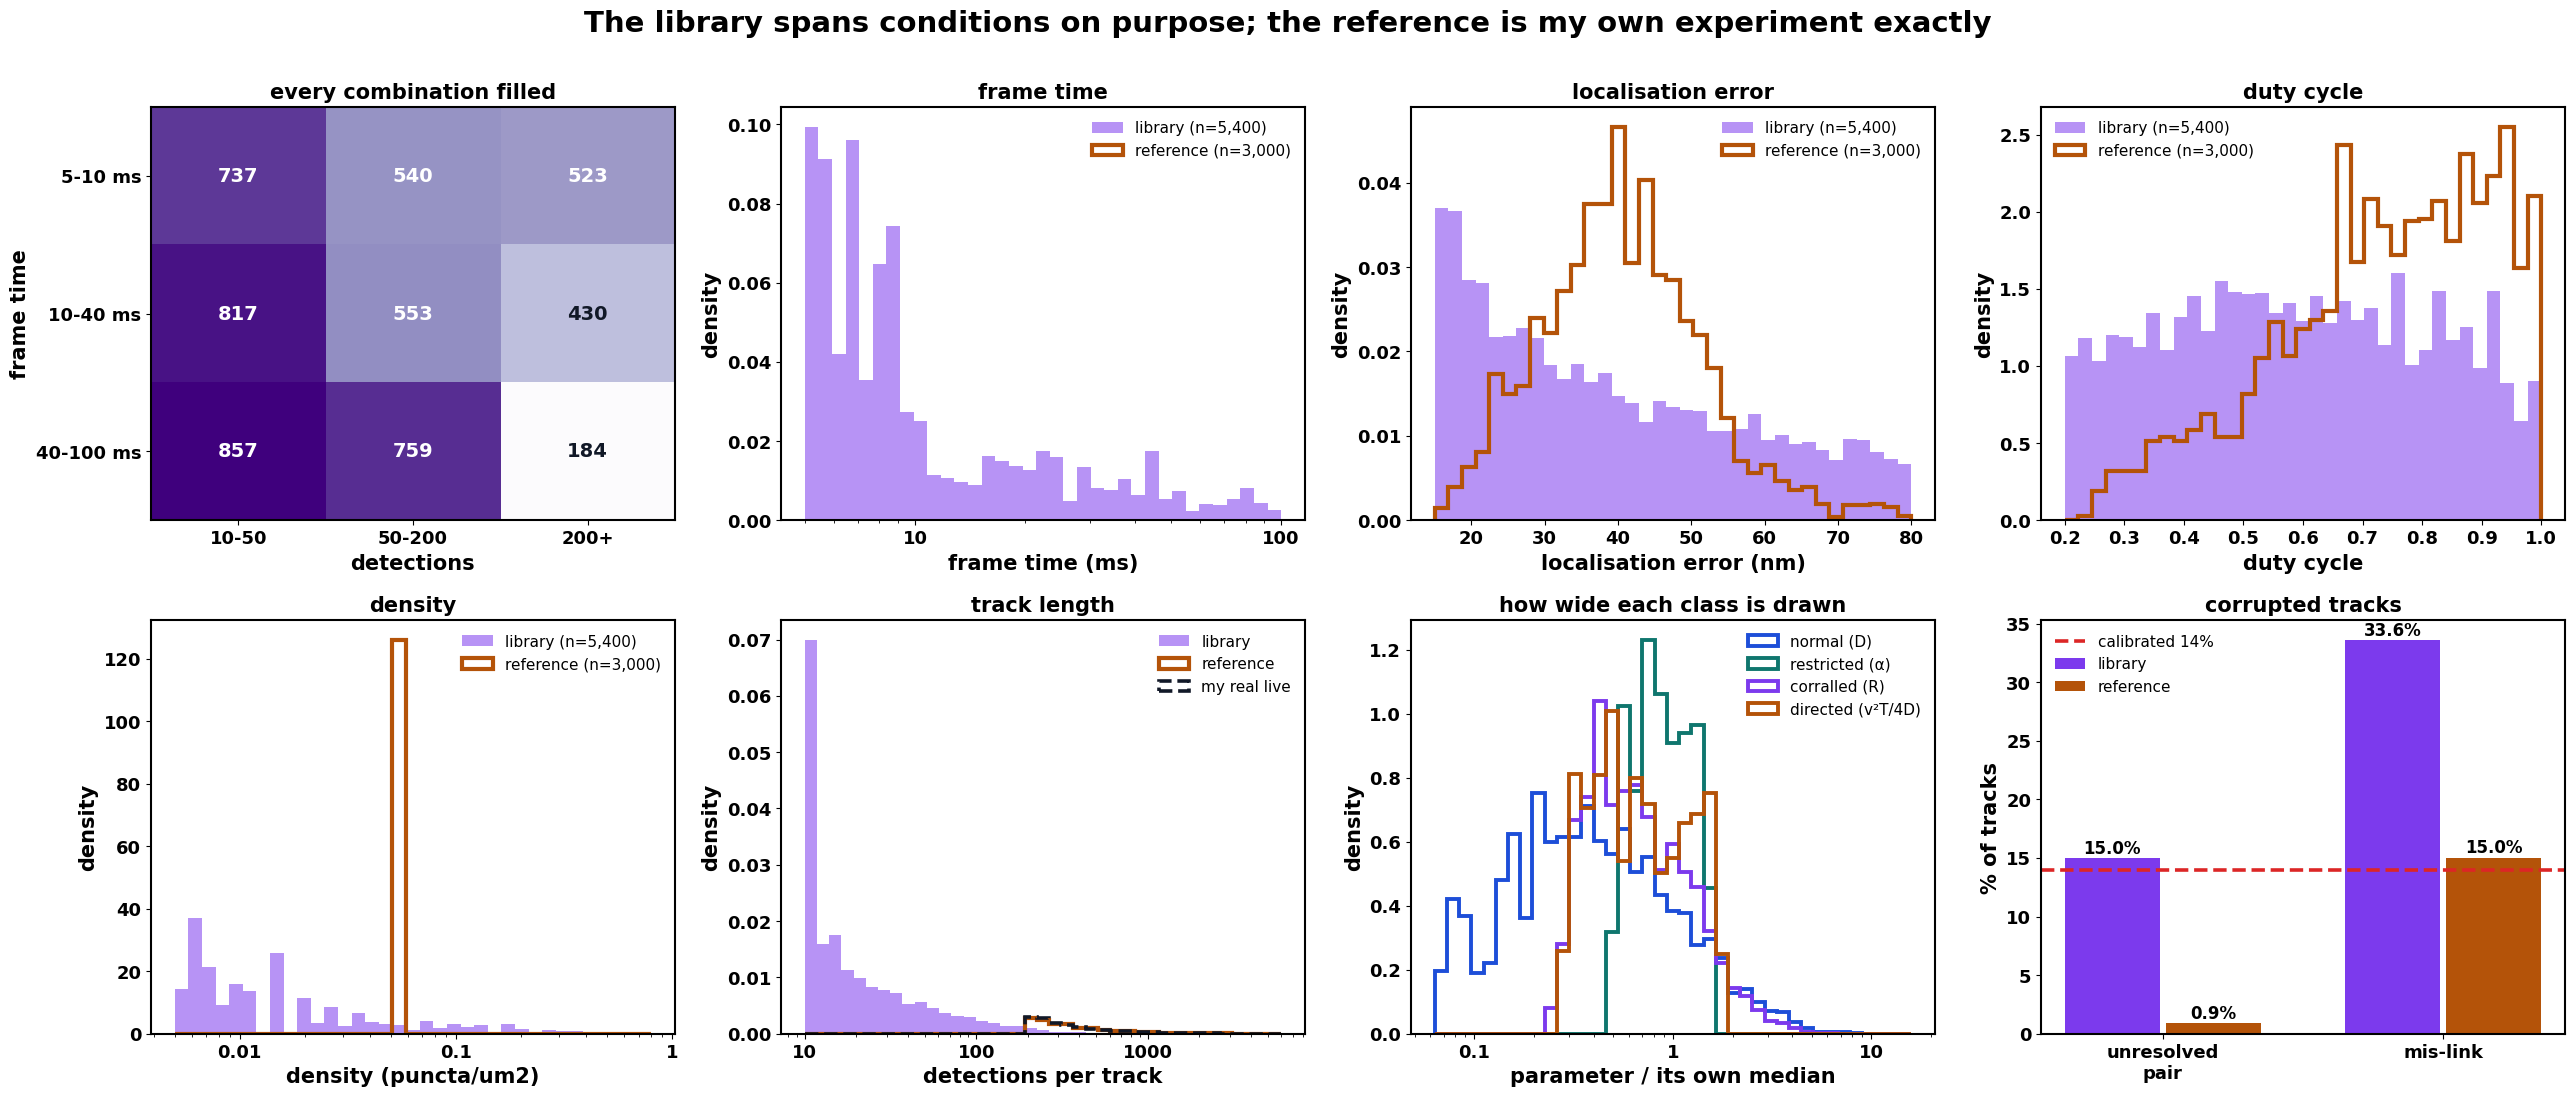

In [33]:
fig, axes = plt.subplots(2, 4, figsize=(26, 11))
C_LIB, C_REF = "#7c3aed", "#b45309"

ax = axes[0, 0]
ct = pd.crosstab(LIB_LAB.dt_band, LIB_LAB.len_band)
ax.imshow(ct.to_numpy(), cmap="Purples", aspect="auto")
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.iloc[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=14,
                fontweight="bold",
                color="white" if v > ct.to_numpy().max() * .6 else "#111827")
ax.set_xticks(range(3))
ax.set_xticklabels([f"{lo}-{hi}" if hi < 6000 else f"{lo}+"
                    for lo, hi in LEN_BANDS])
ax.set_yticks(range(3))
ax.set_yticklabels([f"{1000*lo:.0f}-{1000*hi:.0f} ms" for lo, hi in DT_BANDS])
ax.set_xlabel("detections"); ax.set_ylabel("frame time")
ax.set_title("every combination filled", fontsize=15)

for ax, col, lab, rr, logx in [
        (axes[0, 1], "dt", "frame time (ms)", DT_RANGE, True),
        (axes[0, 2], "sigma_um", "localisation error (nm)", SIGMA_RANGE, False),
        (axes[0, 3], "duty", "duty cycle", DUTY_RANGE, False),
        (axes[1, 0], "density", "density (puncta/um2)", DENSITY_RANGE, True)]:
    mult = 1000 if col in ("dt", "sigma_um") else 1
    lo, hi = rr[0] * mult, rr[1] * mult
    bins = (np.logspace(np.log10(lo), np.log10(hi), 36) if logx
            else np.linspace(lo, hi, 36))
    ax.hist(LIB_LAB[col] * mult, bins=bins, density=True, color=C_LIB, alpha=.55,
            label=f"library (n={len(LIB_LAB):,})")
    ax.hist(REF_LAB[col] * mult, bins=bins, density=True, histtype="step", lw=3,
            color=C_REF, label=f"reference (n={len(REF_LAB):,})")
    if logx:
        ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
        ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xlabel(lab); ax.set_ylabel("density")
    ax.set_title(lab.split(" (")[0], fontsize=15)
    ax.legend(fontsize=11, frameon=False)

ax = axes[1, 1]
bins = np.logspace(np.log10(MIN_SIM_DET), np.log10(6000), 40)
ax.hist(LIB_LAB.n_det, bins=bins, density=True, color=C_LIB, alpha=.55,
        label="library")
ax.hist(REF_LAB.n_det, bins=bins, density=True, histtype="step", lw=3,
        color=C_REF, label="reference")
ax.hist(LIVE.n_det, bins=bins, density=True, histtype="step", lw=2.6,
        color="#111827", ls="--", label="my real live")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("detections per track"); ax.set_ylabel("density")
ax.set_title("track length", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = axes[1, 2]
for k, col, lab in [("normal", "D", "D"), ("restricted", "alpha", "α"),
                    ("corralled", "R_um", "R"),
                    ("directed", "directedness", "v²T/4D")]:
    v = LIB_LAB.loc[LIB_LAB.kind == k, col].dropna()
    ax.hist(v / v.median(), bins=np.logspace(-1.2, 1.2, 40), density=True,
            histtype="step", lw=2.8, color=COL[k], label=f"{k} ({lab})")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("parameter / its own median"); ax.set_ylabel("density")
ax.set_title("how wide each class is drawn", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = axes[1, 3]
x = np.arange(2)
lib_v = [100 * LIB_LAB.is_pair.mean(), 100 * LIB_LAB.is_mislink.mean()]
ref_v = [100 * REF_LAB.is_pair.mean(), 100 * REF_LAB.is_mislink.mean()]
ax.bar(x - .18, lib_v, .34, color=C_LIB, label="library")
ax.bar(x + .18, ref_v, .34, color=C_REF, label="reference")
for xi, v in list(zip(x - .18, lib_v)) + list(zip(x + .18, ref_v)):
    ax.text(xi, v + .4, f"{v:.1f}%", ha="center", fontsize=12, fontweight="bold")
ax.axhline(100 * MISLINK_AT_MINE, color="#dc2626", ls="--", lw=2.6,
           label=f"calibrated {100*MISLINK_AT_MINE:.0f}%")
ax.set_xticks(x); ax.set_xticklabels(["unresolved\npair", "mis-link"])
ax.set_ylabel("% of tracks")
ax.set_title("corrupted tracks", fontsize=15)
ax.legend(fontsize=11, frameon=False)

bold_ticks(*axes.ravel())
fig.suptitle("The library spans conditions on purpose; the reference is my own "
             "experiment exactly", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "S3_library_contents.png", bbox_inches="tight")

## 5. The gate — does the simulation reproduce cells where nothing moves?

Before any of this is used for machine learning, the simulated immobile tracks
have to reproduce my real fixed cells. This is the only place I have real data
where I know the answer, so it is the only honest check available.

In [34]:
for name, T, L in [("library", LIB, LIB_LAB), ("reference", REF_TR, REF_LAB),
                   ("fixed", FIXSIM, FIXSIM_LAB)]:
    T.to_parquet(OUT / f"sim_{name}_tracks.parquet", index=False)
    L.to_csv(OUT / f"sim_{name}_labels.csv", index=False)
    print(f"wrote sim_{name}_tracks.parquet ({len(L):,} tracks)")

def srg_of_sim(T, L, report=True):
    """sRg, Rg, step and aspect for every simulated track; counts those dropped."""
    rows, dropped = [], []
    for tid_, g in tqdm(T.groupby("track_gid", sort=False),
                        total=T.track_gid.nunique(), desc="sRg"):
        fr = g.frame.to_numpy()
        P = g[["x_um", "y_um"]].to_numpy(np.float64)
        step = np.linalg.norm(np.diff(P, axis=0)[np.diff(fr) == 1], axis=1)
        if step.size < 2:
            dropped.append(tid_)
            continue
        c = P - P.mean(0)
        Rg = np.sqrt((c ** 2).sum(1).mean())
        w = np.sqrt(np.clip(np.linalg.eigvalsh(np.cov(c.T)), 1e-12, None))
        rows.append({"track_gid": tid_, "sRg": SQ * Rg / step.mean(),
                     "Rg_um": Rg, "step_um": step.mean(),
                     "aspect": w[1] / w[0], "n_det_": len(fr),
                     "n_steps": int(step.size)})
    if report and dropped:
        D_ = L[L.track_gid.isin(dropped)]
        print(f"   dropped {len(dropped):,} of {L.track_gid.nunique():,} tracks "
              f"({100*len(dropped)/L.track_gid.nunique():.1f}%) - fewer than "
              f"two gap-free steps")
        if len(D_):
            by = D_.groupby("kind").size()
            print(f"      by class: "
                  + ", ".join(f"{k} {v}" for k, v in by.items()))
            print(f"      their median duty {D_.duty.median():.2f}, "
                  f"n_det {D_.n_det.median():.0f}, "
                  f"dt {1000*D_.dt.median():.0f} ms")
    return pd.DataFrame(rows).merge(L, on="track_gid")

S_FIX = srg_of_sim(FIXSIM, FIXSIM_LAB)
S_REF = srg_of_sim(REF_TR, REF_LAB)
S_LIB = srg_of_sim(LIB, LIB_LAB)

# the positions are on disk and summarised; only the labels and the sRg tables
# are read from here on
del LIB, REF_TR, FIXSIM
gc.collect()

# Four things the gate has to check, not one. A simulation can match sRg
# exactly and still have unrealistic step sizes, track lengths or gap patterns -
# sRg is a ratio, so errors in Rg and step cancel inside it.
_rg = FIX.set_index("track_gid")
_rdut = _rg.duty.reindex(R_FIX.track_gid).to_numpy()
# --- what got excluded, and from what -----------------------------------
# Every filter here drops tracks, and a percentage without its denominator is
# not a result. This is the audit.
EXCL = pd.DataFrame([
    ("real fixed", N_REAL_FIX, len(R_FIX),
     f"needs {MIN_TRACK_LEN}+ detections and 2+ gap-free steps"),
    ("real live", N_REAL_LIVE, len(R_LIVE),
     f"needs {MIN_TRACK_LEN}+ detections and 2+ gap-free steps"),
    ("  ...of which mobile", len(R_LIVE), int((R_LIVE.sRg > CUTOFF).sum()),
     "above my cutoff - the pool D is measured from"),
    ("  ...with a fitted D", int((R_LIVE.sRg > CUTOFF).sum()), len(D_POOL),
     "the MSD fit needs 4+ usable lags and D > 0"),
    ("  ...with a corral", len(CORRAL_TAB), len(CORRAL),
     "MSD must flatten AND clear twice the noise"),
    ("simulated library", LIB_LAB.track_gid.nunique(), len(S_LIB),
     "2+ gap-free steps"),
    ("simulated reference", REF_LAB.track_gid.nunique(), len(S_REF),
     "2+ gap-free steps"),
    ("simulated fixed", FIXSIM_LAB.track_gid.nunique(), len(S_FIX),
     "2+ gap-free steps"),
], columns=["set", "entered", "survived", "the filter"])
EXCL["kept %"] = (100 * EXCL.survived / EXCL.entered).round(1)
EXCL.to_csv(TAB_DIR / "exclusions.csv", index=False)
print("WHAT GOT EXCLUDED, AND FROM WHAT")
print(EXCL.to_string(index=False))
print()
print("The simulated rows matter most: tracks with fewer than two gap-free")
print("steps are the shortest and most heavily blinked, so if many are dropped,")
print("every error rate below is quoted on the easy tracks only.")
print()

gate = pd.DataFrame([
    ("median sRg", R_FIX.sRg.median(), S_FIX.sRg.median()),
    ("75th percentile", R_FIX.sRg.quantile(.75), S_FIX.sRg.quantile(.75)),
    ("95th percentile", R_FIX.sRg.quantile(.95), S_FIX.sRg.quantile(.95)),
    ("stretched %", STRETCHED, 100 * (S_FIX.aspect > ASPECT_CUT).mean()),
    ("median of mean step (nm)", 1000 * R_FIX.step_um.median(),
     1000 * S_FIX.step_um.median()),
    ("90th pct of mean step (nm)", 1000 * R_FIX.step_um.quantile(.90),
     1000 * S_FIX.step_um.quantile(.90)),
    ("median Rg (nm)", 1000 * R_FIX.Rg_um.median(),
     1000 * S_FIX.Rg_um.median()),
    ("median detections", R_FIX.n_det.median(), S_FIX.n_det.median()),
    ("median duty cycle", float(np.nanmedian(_rdut)), S_FIX.duty.median()),
], columns=["what", "my real fixed", "simulated"])
gate["diff %"] = 100 * (gate["simulated"] - gate["my real fixed"]) \
                 / gate["my real fixed"]
gate = gate.round(3)
gate.to_csv(TAB_DIR / "gate.csv", index=False)
print()
print(gate.to_string(index=False))
ks = stats.ks_2samp(R_FIX.sRg.dropna(), S_FIX.sRg.dropna())
print(f"\nwhole distribution (KS): D = {ks.statistic:.3f}")
print("D is the largest gap between the two cumulative distributions, so 0.05")
print("means they never differ by more than 5% of the tracks at any sRg.")

wrote sim_library_tracks.parquet (5,400 tracks)


wrote sim_reference_tracks.parquet (3,000 tracks)


wrote sim_fixed_tracks.parquet (3,000 tracks)


sRg:   0%|          | 0/3000 [00:00<?, ?it/s]

sRg:   0%|          | 0/3000 [00:00<?, ?it/s]

sRg:   0%|          | 0/5400 [00:00<?, ?it/s]

   dropped 40 of 5,400 tracks (0.7%) - fewer than two gap-free steps
      by class: corralled 3, directed 6, immobile 14, normal 7, restricted 10
      their median duty 0.26, n_det 10, dt 30 ms


WHAT GOT EXCLUDED, AND FROM WHAT
                 set  entered  survived                                    the filter  kept %
          real fixed     3025      3025   needs 200+ detections and 2+ gap-free steps   100.0
           real live     2392      2392   needs 200+ detections and 2+ gap-free steps   100.0
  ...of which mobile     2392      1833 above my cutoff - the pool D is measured from    76.6
  ...with a fitted D     1833      1833    the MSD fit needs 4+ usable lags and D > 0   100.0
    ...with a corral     2392        96    MSD must flatten AND clear twice the noise     4.0
   simulated library     5400      5360                             2+ gap-free steps    99.3
 simulated reference     3000      3000                             2+ gap-free steps   100.0
     simulated fixed     3000      3000                             2+ gap-free steps   100.0

The simulated rows matter most: tracks with fewer than two gap-free
steps are the shortest and most heavily blinked, so 

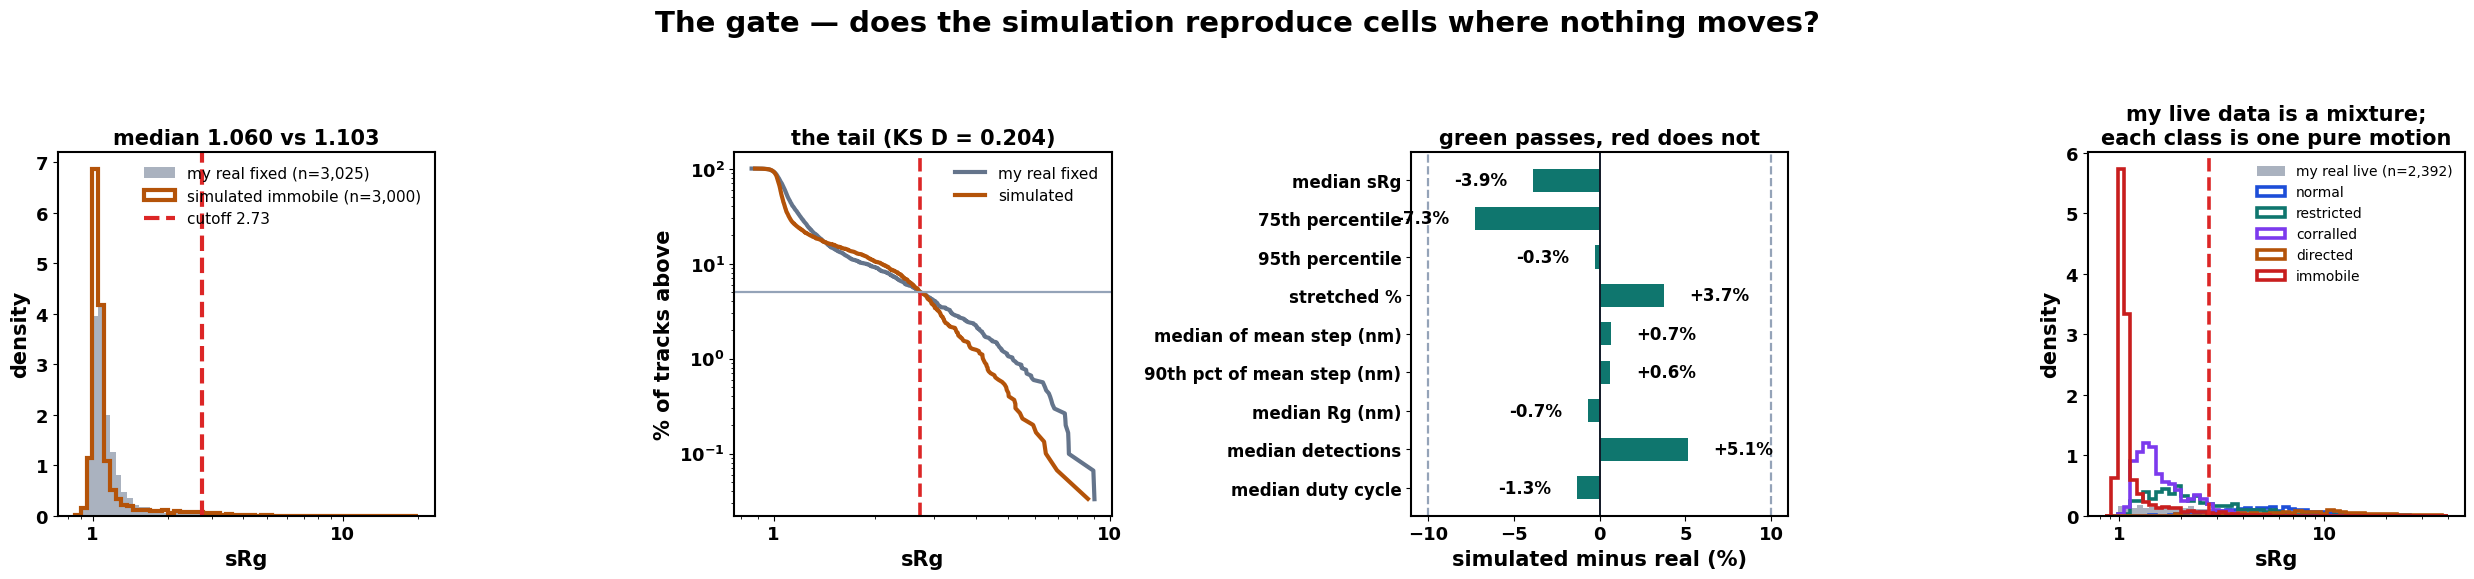

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))

ax = axes[0]
bins = np.logspace(np.log10(0.85), np.log10(20), 60)
ax.hist(R_FIX.sRg, bins=bins, density=True, color=C_FIX, alpha=.55,
        label=f"my real fixed (n={len(R_FIX):,})")
ax.hist(S_FIX.sRg, bins=bins, density=True, histtype="step", lw=3,
        color=C_SIM, label=f"simulated immobile (n={len(S_FIX):,})")
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("sRg"); ax.set_ylabel("density")
ax.set_title(f"median {S_FIX.sRg.median():.3f} vs "
             f"{R_FIX.sRg.median():.3f}", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
for lab, v, c in [("my real fixed", R_FIX.sRg, C_FIX),
                  ("simulated", S_FIX.sRg, C_SIM)]:
    s = np.sort(v.dropna())
    ax.plot(s, 100 * (1 - np.arange(s.size) / s.size), lw=3, color=c, label=lab)
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=2.6)
ax.axhline(5, color="#94a3b8", lw=1.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("sRg"); ax.set_ylabel("% of tracks above")
ax.set_title(f"the tail (KS D = {ks.statistic:.3f})", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = axes[2]
g = gate.iloc[::-1]
cols = ["#dc2626" if abs(d) > 10 else "#0f766e" for d in g["diff %"]]
ax.barh(np.arange(len(g)), g["diff %"], color=cols, height=.6)
ax.axvline(0, color="#111827", lw=1.4)
for lim_ in (-10, 10):
    ax.axvline(lim_, color="#94a3b8", ls="--", lw=1.6)
for i, (d, w) in enumerate(zip(g["diff %"], g["what"])):
    ax.text(d + (1.5 if d >= 0 else -1.5), i, f"{d:+.1f}%", va="center",
            ha="left" if d >= 0 else "right", fontsize=12, fontweight="bold")
ax.set_yticks(np.arange(len(g))); ax.set_yticklabels(g["what"], fontsize=12)
ax.set_xlabel("simulated minus real (%)")
ax.set_title("green passes, red does not", fontsize=15)

ax = axes[3]
bins = np.logspace(np.log10(0.85), np.log10(40), 55)
ax.hist(R_LIVE.sRg, bins=bins, density=True, color=C_FIX, alpha=.55,
        label=f"my real live (n={len(R_LIVE):,})")
for k in CLASSES:
    v = S_REF.loc[S_REF.kind == k, "sRg"]
    ax.hist(v, bins=bins, density=True, histtype="step", lw=2.6, color=COL[k],
            label=k)
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=2.6)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("sRg"); ax.set_ylabel("density")
ax.set_title("my live data is a mixture;\neach class is one pure motion",
             fontsize=15)
ax.legend(fontsize=10, frameon=False)

bold_ticks(*axes)
fig.suptitle("The gate — does the simulation reproduce cells where nothing "
             "moves?", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "S4_gate.png", bbox_inches="tight")

### Fitting the immobile class

The gate's median sRg comes out below my real fixed data, and across six seeds
the simulated median is steady to about ±0.004 — so a gap of a few percent is
many standard deviations, not noise. It says the simulated immobile molecules
are slightly too still.

This is the one thing in the notebook I cannot measure. My fixed cells tell me
what residual motion *looks like*, not what diffusion coefficient produced it,
so the split between frozen and residually mobile molecules has to be fitted.
My plan has a section for exactly this.

Fitted on the median only. The 95th percentile and the stretched fraction stay
out of it: both already pass within the run-to-run spread, and letting a fit
touch them would mean the residual mobility quietly absorbing whatever the
mis-linking model does not account for.

In [36]:
_rng = np.random.default_rng(SEED + 55)
TARGET_MED = float(R_FIX.sRg.median())
len_pool_fix = FIX.n_det.to_numpy()
duty_pool_fix = FIX.duty.to_numpy()

def immobile_median(still_share, resid_hi, n=400):
    """Median sRg produced by a given frozen/residual split."""
    out = []
    for _ in range(n):
        lo_, hi_ = (STILL_D if _rng.random() < still_share else (1e-6, resid_hi))
        p_D = float(np.exp(_rng.uniform(np.log(lo_), np.log(hi_))))
        r = make_track("immobile", DT_S, int(_rng.choice(len_pool_fix)),
                       float(_rng.choice(duty_pool_fix)),
                       float(_rng.choice(SIGMA)), 0.5, 1.0, my_density,
                       _rng, vary=False, patterns=PAT_FIX)
        if r is None:
            continue
        fr, xy, _ = r
        span = int(fr[-1] - fr[0] + 1)
        true = np.cumsum(_rng.normal(0, np.sqrt(2 * p_D * DT_S), (span, 2)), 0)
        d_, _t = drift_of(span, 0, _rng, N_FRAMES, 1.0)
        v = (true + d_)[fr] + _rng.normal(0, float(_rng.choice(SIGMA)),
                                          (fr.size, 2))
        step = np.linalg.norm(np.diff(v, axis=0)[np.diff(fr) == 1], axis=1)
        if step.size < 2:
            continue
        Rg = np.sqrt(((v - v.mean(0)) ** 2).sum(1).mean())
        out.append(SQ * Rg / step.mean())
    return float(np.median(out)) if out else np.nan

rows = []
for share in (0.20, 0.35, 0.50, 0.55, 0.70):
    for hi_ in (1.2e-3, 3e-3, 6e-3):
        m = immobile_median(share, hi_)
        rows.append({"still share": share, "residual D max": f"{hi_:.1e}",
                     "median sRg": round(m, 4),
                     "off by": round(100 * (m - TARGET_MED) / TARGET_MED, 2)})
FIT_IMM = pd.DataFrame(rows)
FIT_IMM["|off by|"] = FIT_IMM["off by"].abs()
FIT_IMM = FIT_IMM.sort_values("|off by|").drop(columns="|off by|")
FIT_IMM.to_csv(TAB_DIR / "immobile_population_fit.csv", index=False)
print(f"my real fixed median sRg: {TARGET_MED:.4f}")
print(f"currently using still share {STILL_SHARE}, residual D up to "
      f"{RESIDUAL_D[1]:.1e}")
print()
print(FIT_IMM.to_string(index=False))
print()
print("Take the top row and set STILL_SHARE and RESIDUAL_D to it, then re-run.")
print("The constants stay hard-coded on purpose: a notebook that re-tunes itself")
print("every run cannot be said to have been validated against anything.")

my real fixed median sRg: 1.1032
currently using still share 0.55, residual D up to 1.2e-03

 still share residual D max  median sRg  off by
        0.20        6.0e-03      1.0510   -4.73
        0.35        6.0e-03      1.0391   -5.81
        0.20        3.0e-03      1.0325   -6.40
        0.20        1.2e-03      1.0322   -6.44
        0.35        3.0e-03      1.0283   -6.79
        0.35        1.2e-03      1.0271   -6.90
        0.50        6.0e-03      1.0239   -7.18
        0.55        6.0e-03      1.0229   -7.28
        0.50        1.2e-03      1.0217   -7.39
        0.70        3.0e-03      1.0200   -7.54
        0.50        3.0e-03      1.0197   -7.57
        0.55        3.0e-03      1.0194   -7.59
        0.55        1.2e-03      1.0186   -7.67
        0.70        6.0e-03      1.0161   -7.90
        0.70        1.2e-03      1.0134   -8.14

Take the top row and set STILL_SHARE and RESIDUAL_D to it, then re-run.
The constants stay hard-coded on purpose: a notebook that re-tunes

## 6. What my cutoff gets wrong

The question the whole simulation exists to answer: **if a molecule is actually
moving, how often does my sRg cutoff call it immobile?**

Two versions. At my own conditions, from the reference — the error in the
experiment I have run, and the number for my document. And per band cell, from
the library — a lookup table, because 2.731 is not the right cutoff at 100 ms
with 50 detections, and a future experiment needs its own.

In [37]:
mine = S_REF.assign(called_immobile=S_REF.sRg <= CUTOFF)
err_mine = 100 * mine.groupby("kind").called_immobile.mean()
mob = mine[mine.kind != "immobile"]

def rate_ci(flags, n_boot=400, seed=SEED):
    """Bootstrap interval on an error rate, by resampling the tracks."""
    v = np.asarray(flags, bool)
    if v.size < 20:
        return np.nan, np.nan
    r = np.random.default_rng(seed)
    bs = [100 * r.choice(v, v.size, replace=True).mean() for _ in range(n_boot)]
    return float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

print(f"AT MY OWN CONDITIONS, cutoff = {CUTOFF:.3f}")
rows_mine = []
for k in CLASSES:
    sel = mine[mine.kind == k]
    lo_, hi_ = rate_ci(sel.called_immobile.to_numpy())
    rows_mine.append({"class": k, "called immobile %": round(err_mine[k], 1),
                      "95% CI": f"{lo_:.1f}-{hi_:.1f}", "ci_lo": lo_,
                      "ci_hi": hi_, "n": len(sel)})
lo_, hi_ = rate_ci(mob.called_immobile.to_numpy())
rows_mine.append({"class": "all mobile",
                  "called immobile %": round(100 * mob.called_immobile.mean(), 1),
                  "95% CI": f"{lo_:.1f}-{hi_:.1f}", "ci_lo": lo_, "ci_hi": hi_,
                  "n": len(mob)})
ERR_MINE = pd.DataFrame(rows_mine).set_index("class")
ERR_MINE.to_csv(TAB_DIR / "cutoff_error_my_conditions.csv")
print(ERR_MINE.drop(columns=["ci_lo", "ci_hi"]).to_string())
print("\nEvery one of the first four is moving by construction, so those four")
print("numbers are errors. The interval is on the RATE, from resampling the")
print("tracks - the seed spread in section 7 is a second, independent estimate.")

def cut_ci(v, n_boot=200, seed=SEED):
    v = np.asarray(v)[np.isfinite(v)]
    if v.size < 40:
        return np.nan, np.nan, np.nan
    r = np.random.default_rng(seed)
    bs = [np.quantile(r.choice(v, v.size, replace=True), .95)
          for _ in range(n_boot)]
    return (float(np.quantile(v, .95)), float(np.percentile(bs, 2.5)),
            float(np.percentile(bs, 97.5)))

rows = []
for db, (dlo, dhi) in enumerate(DT_BANDS):
    for lb, (nlo, nhi) in enumerate(LEN_BANDS):
        cell = S_LIB[(S_LIB.dt_band == db) & (S_LIB.len_band == lb)]
        imm, mo = cell[cell.kind == "immobile"], cell[cell.kind != "immobile"]
        if len(imm) < 40 or len(mo) < 40:
            continue
        cut, lo_, hi_ = cut_ci(imm.sRg.to_numpy())
        r = {"frame time": f"{1000*dlo:.0f}-{1000*dhi:.0f} ms",
             "detections": f"{nlo}-{nhi}" if nhi < 6000 else f"{nlo}+",
             "immobile": len(imm), "mobile": len(mo), "cutoff": round(cut, 3),
             "95% CI": f"{lo_:.2f}-{hi_:.2f}",
             "all mobile": round(100 * float((mo.sRg <= cut).mean()), 1)}
        for k in CLASSES[:-1]:
            sel = mo[mo.kind == k]
            r[k] = (round(100 * float((sel.sRg <= cut).mean()), 1)
                    if len(sel) >= 20 else np.nan)
        rows.append(r)
CELLS = pd.DataFrame(rows)
CELLS.to_csv(TAB_DIR / "cutoff_error_per_condition.csv", index=False)
print()
print("THE LOOKUP TABLE - each cell's own cutoff, and what it costs")
print(CELLS.to_string(index=False))

AT MY OWN CONDITIONS, cutoff = 2.731


            called immobile %     95% CI     n
class                                         
normal                    3.8    2.2-5.5   600
restricted               51.3  47.3-55.2   600
corralled                89.0  86.5-91.3   600
directed                  0.3    0.0-0.8   600
immobile                 95.2  93.3-97.0   600
all mobile               36.1  34.1-38.0  2400

Every one of the first four is moving by construction, so those four
numbers are errors. The interval is on the RATE, from resampling the
tracks - the seed spread in section 7 is a second, independent estimate.



THE LOOKUP TABLE - each cell's own cutoff, and what it costs
frame time detections  immobile  mobile  cutoff    95% CI  all mobile  normal  restricted  corralled  directed
   5-10 ms      10-50       142     584   2.640 1.91-3.01        69.9    70.1        87.5       83.9      38.8
   5-10 ms     50-200       105     435   3.862 3.01-4.75        62.3    39.5        93.6       94.4      20.4
   5-10 ms       200+       109     414   3.888 3.32-5.31        38.9     9.4        57.7       87.9       1.0
  10-40 ms      10-50       152     651   3.215 1.99-5.15        72.5    68.2        90.1       94.6      38.2
  10-40 ms     50-200       114     439   3.919 3.65-4.44        53.8    27.3        81.0       98.1      12.0
  10-40 ms       200+        90     340   4.533 3.43-5.90        44.1     5.3        68.2       94.3       3.4
 40-100 ms      10-50       160     682   1.825 1.69-2.81        40.0    10.8        63.3       85.0       4.0
 40-100 ms     50-200       155     604   4.015 3.

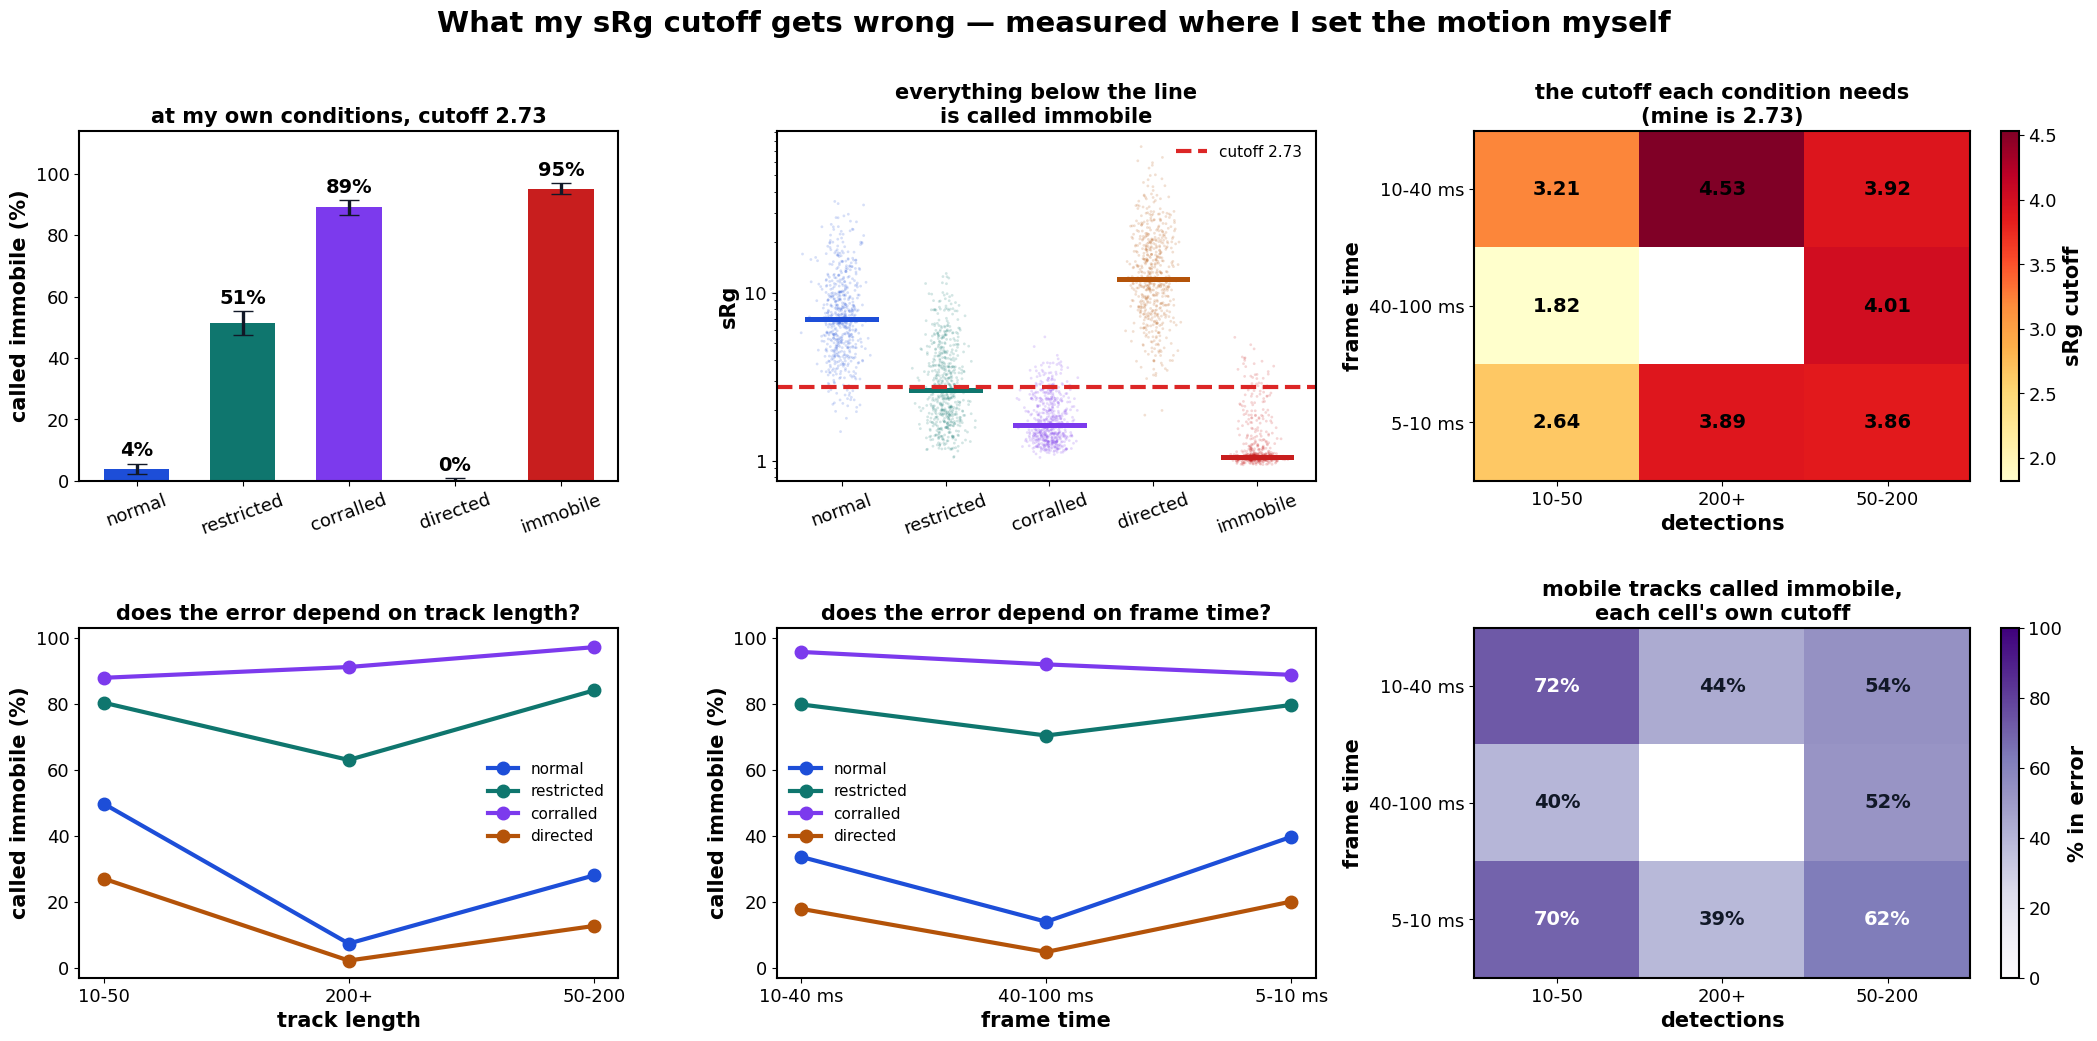

In [38]:
fig = plt.figure(figsize=(26, 11))
gs = fig.add_gridspec(2, 3, hspace=.42, wspace=.28, width_ratios=[1, 1, 1.15])

ax = fig.add_subplot(gs[0, 0])
v = err_mine.reindex(CLASSES)
E = ERR_MINE.reindex(CLASSES)
yerr = np.vstack([v.to_numpy() - E.ci_lo.to_numpy(),
                  E.ci_hi.to_numpy() - v.to_numpy()])
bars = ax.bar(np.arange(5), v.to_numpy(), yerr=yerr, capsize=7,
              color=[COL[k] for k in CLASSES], width=.62,
              error_kw=dict(lw=2.4, ecolor="#111827"))
for b, x_, hi__ in zip(bars, v.to_numpy(), E.ci_hi.to_numpy()):
    ax.text(b.get_x() + b.get_width() / 2, hi__ + 2.5, f"{x_:.0f}%",
            ha="center", fontsize=14, fontweight="bold")
ax.set_xticks(np.arange(5)); ax.set_xticklabels(CLASSES, rotation=20)
ax.set_ylabel("called immobile (%)"); ax.set_ylim(0, 114)
ax.set_title(f"at my own conditions, cutoff {CUTOFF:.2f}", fontsize=15)

ax = fig.add_subplot(gs[0, 1])
for i, k in enumerate(CLASSES):
    s = S_REF.loc[S_REF.kind == k, "sRg"].dropna()
    ax.scatter(np.full(len(s), i) + rng_global.normal(0, .10, len(s)), s, s=4,
               alpha=.18, color=COL[k], edgecolors="none")
    ax.plot([i - .33, i + .33], [s.median()] * 2, lw=3.6, color=COL[k])
ax.axhline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(fmt)
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xticks(np.arange(5)); ax.set_xticklabels(CLASSES, rotation=20)
ax.set_ylabel("sRg")
ax.set_title("everything below the line\nis called immobile", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = fig.add_subplot(gs[0, 2])
piv = CELLS.pivot(index="frame time", columns="detections", values="cutoff")
im = ax.imshow(piv.to_numpy(), cmap="YlOrRd", aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        val = piv.iloc[i, j]
        if np.isfinite(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=14,
                    fontweight="bold")
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
ax.set_xlabel("detections"); ax.set_ylabel("frame time")
ax.set_title(f"the cutoff each condition needs\n(mine is {CUTOFF:.2f})",
             fontsize=15)
plt.colorbar(im, ax=ax, label="sRg cutoff")

for ax_i, (col, lab) in enumerate([("detections", "track length"),
                                   ("frame time", "frame time")]):
    ax = fig.add_subplot(gs[1, ax_i])
    order = [o for o in (piv.columns if col == "detections" else piv.index)]
    xs = np.arange(len(order))
    for k in CLASSES[:-1]:
        m = CELLS.groupby(col)[k].mean().reindex(order)
        ax.plot(xs, m.to_numpy(), "o-", lw=3, ms=9, color=COL[k], label=k)
    ax.set_xticks(xs); ax.set_xticklabels(order)
    ax.set_xlabel(lab); ax.set_ylabel("called immobile (%)")
    ax.set_ylim(-3, 103)
    ax.set_title(f"does the error depend on {lab}?", fontsize=15)
    ax.legend(fontsize=11, frameon=False)

ax = fig.add_subplot(gs[1, 2])
piv2 = CELLS.pivot(index="frame time", columns="detections",
                   values="all mobile").reindex(piv.index)[piv.columns]
im = ax.imshow(piv2.to_numpy(), cmap="Purples", aspect="auto", vmin=0, vmax=100)
for i in range(piv2.shape[0]):
    for j in range(piv2.shape[1]):
        val = piv2.iloc[i, j]
        if np.isfinite(val):
            ax.text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=14,
                    fontweight="bold",
                    color="white" if val > 60 else "#111827")
ax.set_xticks(range(piv2.shape[1])); ax.set_xticklabels(piv2.columns)
ax.set_yticks(range(piv2.shape[0])); ax.set_yticklabels(piv2.index)
ax.set_xlabel("detections"); ax.set_ylabel("frame time")
ax.set_title("mobile tracks called immobile,\neach cell's own cutoff",
             fontsize=15)
plt.colorbar(im, ax=ax, label="% in error")

fig.suptitle("What my sRg cutoff gets wrong — measured where I set the motion "
             "myself", y=0.99)
fig.savefig(FIG_DIR / "S5_cutoff_error.png", bbox_inches="tight")

## 7. How much of this is just the random seed?

Every number so far comes from one run with one seed. Before any of them goes
into a document I need to know how much they move when only the seed changes —
otherwise I cannot tell a real difference from the simulation's own noise.

From here on, any gap between the simulation and my real data is quoted in
units of this spread. Half a standard deviation is noise; four is a real
disagreement.

In [39]:
N_SEEDS, N_EACH_SEED = 6, 600

def one_seed(seed):
    rng = np.random.default_rng(seed)
    fT, fL = build(N_EACH_SEED, False, rng, classes=["immobile"],
                   len_pool=FIX.n_det.to_numpy(), desc=f"seed {seed} fix")
    rT, rL = build(N_EACH_SEED // 3, False, rng,
                   len_pool=LIVE.n_det.to_numpy(), desc=f"seed {seed} ref")
    # report=False: the drop rate is reported once in the main build, and six
    # more copies of it would bury the seed numbers
    F, R = srg_of_sim(fT, fL, report=False), srg_of_sim(rT, rL, report=False)
    mo = R[R.kind != "immobile"]
    out = {"seed": seed, "median sRg": float(F.sRg.median()),
           "95th sRg": float(F.sRg.quantile(.95)),
           "stretched %": 100 * float((F.aspect > ASPECT_CUT).mean()),
           "all mobile called immobile %":
               100 * float((mo.sRg <= CUTOFF).mean())}
    for k in CLASSES[:-1]:
        out[k] = 100 * float((R[R.kind == k].sRg <= CUTOFF).mean())
    return out

SEEDS = pd.DataFrame([one_seed(SEED + 100 * i) for i in range(N_SEEDS)])
SEEDS.to_csv(TAB_DIR / "seed_spread.csv", index=False)
cols_ = [c for c in SEEDS.columns if c != "seed"]
summ = pd.DataFrame({"mean": SEEDS[cols_].mean(), "sd": SEEDS[cols_].std(),
                     "min": SEEDS[cols_].min(),
                     "max": SEEDS[cols_].max()}).round(3)
print(SEEDS.round(2).to_string(index=False))
print("\nacross six seeds:")
print(summ.to_string())
print("\nTHE GATE, in units of the simulation's own run-to-run spread:")
for lab, real in [("median sRg", float(R_FIX.sRg.median())),
                  ("95th sRg", CUTOFF), ("stretched %", STRETCHED)]:
    m_, s_ = summ.loc[lab, "mean"], summ.loc[lab, "sd"]
    print(f"   {lab:16s} real {real:7.3f}  simulated {m_:7.3f}  "
          f"sd {s_:6.3f}  -> {abs(m_-real)/s_ if s_>0 else np.nan:.1f} sd out")

seed 0 fix:   0%|          | 0/600 [00:00<?, ?it/s]

seed 0 ref:   0%|          | 0/1000 [00:00<?, ?it/s]

sRg:   0%|          | 0/600 [00:00<?, ?it/s]

sRg:   0%|          | 0/1000 [00:00<?, ?it/s]

seed 100 fix:   0%|          | 0/600 [00:00<?, ?it/s]

...

seed 500 fix:   0%|          | 0/600 [00:00<?, ?it/s]

seed 500 ref:   0%|          | 0/1000 [00:00<?, ?it/s]

sRg:   0%|          | 0/600 [00:00<?, ?it/s]

sRg:   0%|          | 0/1000 [00:00<?, ?it/s]

 seed  median sRg  95th sRg  stretched %  all mobile called immobile %  normal  restricted  corralled  directed
    0        1.06      2.53         6.00                         36.62     5.5        54.5       86.0       0.5
  100        1.07      2.98         8.17                         38.50     8.5        54.5       90.0       1.0
  200        1.05      2.57         6.00                         37.50     3.0        55.5       90.0       1.5
  300        1.06      2.93         7.00                         36.38     3.0        53.0       87.5       2.0
  400        1.05      2.84         7.17                         38.00     4.5        58.0       89.5       0.0
  500        1.05      2.31         5.17                         38.12     6.5        55.0       90.5       0.5

across six seeds:
                                mean     sd     min     max
median sRg                     1.058  0.006   1.050   1.067
95th sRg                       2.694  0.263   2.312   2.978
stretched %      

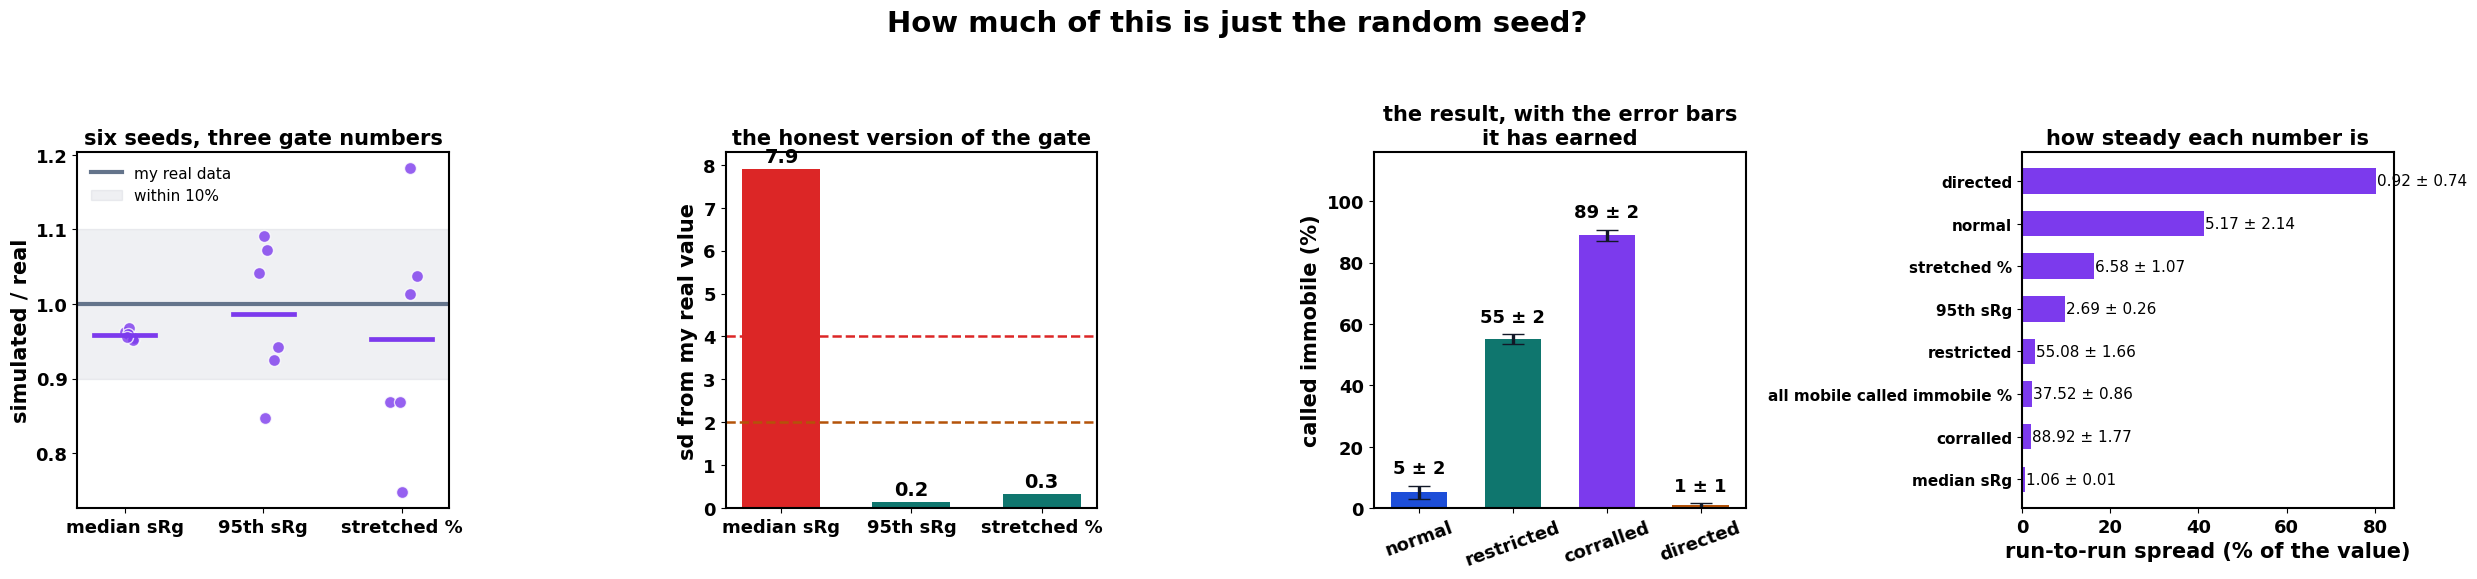

In [40]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
C_SEED = "#7c3aed"
items = [("median sRg", float(R_FIX.sRg.median())), ("95th sRg", CUTOFF),
         ("stretched %", STRETCHED)]

ax = axes[0]
for i, (lab, real) in enumerate(items):
    v = SEEDS[lab].to_numpy()
    ax.scatter(np.full(len(v), i) + rng_global.normal(0, .05, len(v)), v / real,
               s=75, color=C_SEED, alpha=.8, edgecolors="white", lw=1, zorder=3)
    ax.plot([i - .22, i + .22], [v.mean() / real] * 2, lw=3.4, color=C_SEED,
            zorder=4)
ax.axhline(1.0, color=C_FIX, lw=3, label="my real data")
ax.axhspan(0.9, 1.1, color=C_FIX, alpha=.10, zorder=0, label="within 10%")
ax.set_xticks(range(3)); ax.set_xticklabels([l for l, _ in items])
ax.set_ylabel("simulated / real")
ax.set_title("six seeds, three gate numbers", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
sds = []
for lab, real in items:
    v = SEEDS[lab].to_numpy(); s_ = v.std()
    sds.append(abs(v.mean() - real) / s_ if s_ > 0 else np.nan)
cols2 = ["#0f766e" if d < 2 else "#b45309" if d < 4 else "#dc2626" for d in sds]
bars = ax.bar(np.arange(3), sds, color=cols2, width=.6)
for b, d in zip(bars, sds):
    ax.text(b.get_x() + b.get_width() / 2, d + .15, f"{d:.1f}", ha="center",
            fontsize=14, fontweight="bold")
for y_, c_, t_ in [(2, "#b45309", "worth a look"), (4, "#dc2626", "real gap")]:
    ax.axhline(y_, color=c_, ls="--", lw=1.8)
ax.set_xticks(range(3)); ax.set_xticklabels([l for l, _ in items])
ax.set_ylabel("sd from my real value")
ax.set_title("the honest version of the gate", fontsize=15)

ax = axes[2]
ks_ = CLASSES[:-1]
m_ = [SEEDS[k].mean() for k in ks_]; s_ = [SEEDS[k].std() for k in ks_]
ax.bar(np.arange(len(ks_)), m_, yerr=s_, capsize=8, width=.6,
       color=[COL[k] for k in ks_], error_kw=dict(lw=2.4, ecolor="#111827"))
for i, (mm, ss) in enumerate(zip(m_, s_)):
    ax.text(i, mm + ss + 4, f"{mm:.0f} ± {ss:.0f}", ha="center", fontsize=13,
            fontweight="bold")
ax.set_xticks(np.arange(len(ks_))); ax.set_xticklabels(ks_, rotation=20)
ax.set_ylabel("called immobile (%)"); ax.set_ylim(0, 116)
ax.set_title("the result, with the error bars\nit has earned", fontsize=15)

ax = axes[3]
rr = pd.DataFrame([{"number": c, "mean": SEEDS[c].mean(), "sd": SEEDS[c].std(),
                    "rel": 100 * SEEDS[c].std() / abs(SEEDS[c].mean())}
                   for c in cols_]).sort_values("rel")
ax.barh(np.arange(len(rr)), rr["rel"], color=C_SEED, height=.6)
for i, (v_, mm, ss) in enumerate(zip(rr["rel"], rr["mean"], rr["sd"])):
    ax.text(v_ + .2, i, f"{mm:.2f} ± {ss:.2f}", va="center", fontsize=11)
ax.set_yticks(np.arange(len(rr))); ax.set_yticklabels(rr["number"], fontsize=11)
ax.set_xlabel("run-to-run spread (% of the value)")
ax.set_title("how steady each number is", fontsize=15)

bold_ticks(*axes)
fig.suptitle("How much of this is just the random seed?", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "S6_seed_spread.png", bbox_inches="tight")

## 8. How long does a window have to be?

Everything above labels a whole track. My live data says that is the wrong
unit: with a 1.5 s window, 52% of my real tracks change state at least once,
and the clearest ones switch visibly. A model trained on pure tracks and
applied to a molecule that diffuses, stops and moves off again returns one
label and gives no sign that it was a compromise.

So the unit becomes a window, and the question is **how short a window can be
and still tell the five motions apart.**

I answer it without a model. Training one here would answer a different
question - whether some particular set of features works - and would decide
things that belong in notebook 02. Instead, for each PAIR of motion types I
take the one quantity the equations say separates them, and measure how much
the two distributions overlap. The overlap is a rank statistic: 0.5 means the
two classes are indistinguishable on that quantity, 1.0 means they never
overlap. If a pair sits at 0.5, no model will separate it; if it sits near 1,
any sensible model will.

| pair | what the equations say separates them |
|---|---|
| normal / restricted | \u03b1 |
| normal / corralled | the plateau ratio |
| normal / directed | directedness |
| restricted / corralled | the plateau ratio |
| restricted / directed | the long-lag \u03b1 |
| corralled / directed | directedness |
| anything / immobile | how far the MSD climbs above 4\u03c3\u00b2 |

Each quantity is assigned **before** looking at the result. Choosing the best
of ten afterwards would inflate every number.

The hard pair looks like corralled against immobile: a corral at my measured
median radius plateaus at R\u00b2 = 0.0142 \u00b5m\u00b2 against a floor of
4\u03c3\u00b2 = 0.0064 \u00b5m\u00b2, a factor of 2.2. Normal diffusion, by
contrast, clears the floor in about three frames.

In [41]:
WIN_LADDER = [50, 100, 200, 400, 800]     # detections per window
N_WIN_PER_CLASS = 300


def window_stats(T, L, floor=noise):
    """The physical quantities from each window, with the camera taken out.

    The raw MSD at short lags is mostly 4*sigma^2, so its slope is near zero for
    every class - fitting it would be comparing noise with noise. Everything
    here is computed on MSD - 4*sigma^2, over the lags where that difference is
    real. `clears` - how far the MSD ever climbs above the floor - is kept in
    its own right, because for an immobile molecule it is the whole story.
    """
    rows = []
    for tid_, g in tqdm(T.groupby("track_gid", sort=False),
                        total=T.track_gid.nunique(), desc="statistics"):
        fr = g.frame.to_numpy()
        Pp = g[["x_um", "y_um"]].to_numpy(np.float64)
        rows.append({"track_gid": tid_,
                     **stats_of_window(fr, Pp, float(L.dt.iloc[0]), floor)})
    return pd.DataFrame(rows).merge(
        L[["track_gid", "kind", "movie_id", "n_det", "dt", "duty"]],
        on="track_gid")


def stats_of_window(fr, Pp, dt, floor=noise):
    """One window in, the physical quantities out. Used on tracks and on
    rolling windows, so both are measured identically."""
    d1 = np.diff(Pp, axis=0)[np.diff(fr) == 1]
    if d1.shape[0] < 4:
        return dict(step=np.nan, Rg=np.nan, sRg=np.nan, clears=np.nan,
                    alpha=np.nan, alpha_long=np.nan, plateau=np.nan,
                    D=np.nan, directedness=np.nan)
    step = float(np.linalg.norm(d1, axis=1).mean())
    c = Pp - Pp.mean(0)
    Rg = float(np.sqrt((c ** 2).sum(1).mean()))

    grid = np.full((fr.max() - fr.min() + 1, 2), np.nan)
    grid[fr - fr.min()] = Pp
    top = max(8, min(len(grid) // 4, 80))
    lags = np.unique(np.round(np.logspace(0, np.log10(top), 14)).astype(int))
    msd = np.full(lags.size, np.nan)
    for i, k in enumerate(lags):
        if k >= len(grid):
            break
        dd = grid[k:] - grid[:-k]
        ok = np.isfinite(dd).all(1)
        if ok.sum() >= 8:
            msd[i] = (dd[ok] ** 2).sum(1).mean()
    clears = float(np.nanmax(msd) / floor) if np.isfinite(msd).any() else 0.0

    sig = msd - floor
    use = np.isfinite(sig) & (sig > 0.25 * floor)
    lg, m = lags[use], sig[use]
    if lg.size >= 4:
        half = max(2, lg.size // 2)
        alpha = float(np.polyfit(np.log(lg[:half]), np.log(m[:half]), 1)[0])
        a_long = float(np.polyfit(np.log(lg[-half:]), np.log(m[-half:]), 1)[0])
        plateau = float(m[-1] / m[half - 1])
        D = float(m[0] / (4 * lg[0] * dt))
    else:
        # never climbed clear of the camera - which is itself the measurement
        alpha, a_long, plateau, D = np.nan, np.nan, 1.0, 1e-9

    good = grid[np.isfinite(grid).all(1)]
    net = float(np.linalg.norm(good[-1] - good[0]))
    direct = net ** 2 / (4 * D * len(grid) * dt) if D > 0 else 0.0
    return dict(step=step, Rg=Rg, sRg=SQ * Rg / step, clears=clears,
                alpha=alpha, alpha_long=a_long, plateau=plateau, D=D,
                directedness=direct)


# the quantity for each pair, fixed in advance from the equations
PAIR_STAT = {
    ("normal", "restricted"):   "alpha",
    ("normal", "corralled"):    "plateau",
    ("normal", "directed"):     "directedness",
    ("normal", "immobile"):     "clears",
    ("restricted", "corralled"): "plateau",
    ("restricted", "directed"): "alpha_long",
    ("restricted", "immobile"): "clears",
    ("corralled", "directed"):  "directedness",
    ("corralled", "immobile"):  "clears",
    ("directed", "immobile"):   "clears",
}


def separability(a, b):
    """How far two distributions are apart, as a rank statistic.

    0.5 means a value from one is as likely to be above as below a value from
    the other - no separation at all. 1.0 means they never overlap. Nothing is
    fitted; this is a property of the two samples.
    """
    a = np.asarray(a, float); b = np.asarray(b, float)
    a = a[np.isfinite(a)]; b = b[np.isfinite(b)]
    if a.size < 10 or b.size < 10:
        return np.nan
    r = stats.rankdata(np.concatenate([a, b]))
    u = r[:a.size].sum() - a.size * (a.size + 1) / 2
    auc = u / (a.size * b.size)
    return float(max(auc, 1 - auc))


sep_rows, SEP = [], {}
for W in WIN_LADDER:
    rngW = np.random.default_rng(SEED + 7000 + W)
    Tw, Lw = build(N_WIN_PER_CLASS, False, rngW,
                   len_pool=np.array([W]), desc=f"windows {W}")
    S = window_stats(Tw, Lw)
    del Tw
    gc.collect()

    M = pd.DataFrame(np.nan, index=CLASSES, columns=CLASSES)
    row = {"window asked": W,
           "detections (median)": float(S.n_det.median()),
           "seconds": float(S.n_det.median() * DT_S / max(S.duty.median(), .01)),
           "windows": int(len(S))}
    for (ka, kb), q in PAIR_STAT.items():
        v = separability(S.loc[S.kind == ka, q], S.loc[S.kind == kb, q])
        M.loc[ka, kb] = M.loc[kb, ka] = v
        row[f"{ka[:4]}/{kb[:4]}"] = v
    SEP[W] = M
    row["hardest pair"] = min(
        ((v, f"{a}/{b}") for (a, b), q in PAIR_STAT.items()
         if np.isfinite(M.loc[a, b]) for v in [M.loc[a, b]]),
        default=(np.nan, "-"))[1]
    row["hardest value"] = float(np.nanmin(M.to_numpy()))
    sep_rows.append(row)
    del S, Lw
    gc.collect()

SEPTAB = pd.DataFrame(sep_rows)
SEPTAB.to_csv(TAB_DIR / "window_separability.csv", index=False)
print(SEPTAB.round(3).to_string(index=False))

windows 50:   0%|          | 0/1500 [00:00<?, ?it/s]

statistics:   0%|          | 0/1500 [00:00<?, ?it/s]

windows 100:   0%|          | 0/1500 [00:00<?, ?it/s]

statistics:   0%|          | 0/1500 [00:00<?, ?it/s]

windows 200:   0%|          | 0/1500 [00:00<?, ?it/s]

...

windows 400:   0%|          | 0/1500 [00:00<?, ?it/s]

statistics:   0%|          | 0/1500 [00:00<?, ?it/s]

windows 800:   0%|          | 0/1500 [00:00<?, ?it/s]

statistics:   0%|          | 0/1500 [00:00<?, ?it/s]

 window asked  detections (median)  seconds  windows  norm/rest  norm/corr  norm/dire  norm/immo  rest/corr  rest/dire  rest/immo  corr/dire  corr/immo  dire/immo         hardest pair  hardest value
           50                 47.0    0.355     1500      0.724      0.755      0.748      0.937      0.563      0.772      0.827      0.869      0.848      0.967 restricted/corralled          0.563
          100                 96.0    0.737     1500      0.730      0.884      0.824      0.981      0.663      0.871      0.884      0.943      0.878      0.992 restricted/corralled          0.663
          200                196.5    1.504     1500      0.732      0.942      0.790      0.992      0.732      0.935      0.929      0.973      0.911      0.998 restricted/corralled          0.732
          400                365.0    2.669     1500      0.764      0.990      0.806      0.999      0.801      0.940      0.941      0.975      0.917      0.997    normal/restricted          0.764
     


At the longest window the hardest pair is normal/restricted at 0.77.
A pair at 0.5 cannot be separated by any model; a pair near 1 will be
separated by almost any model. This is a property of the data, not of a
classifier - the features and the model are notebook 02's decisions.


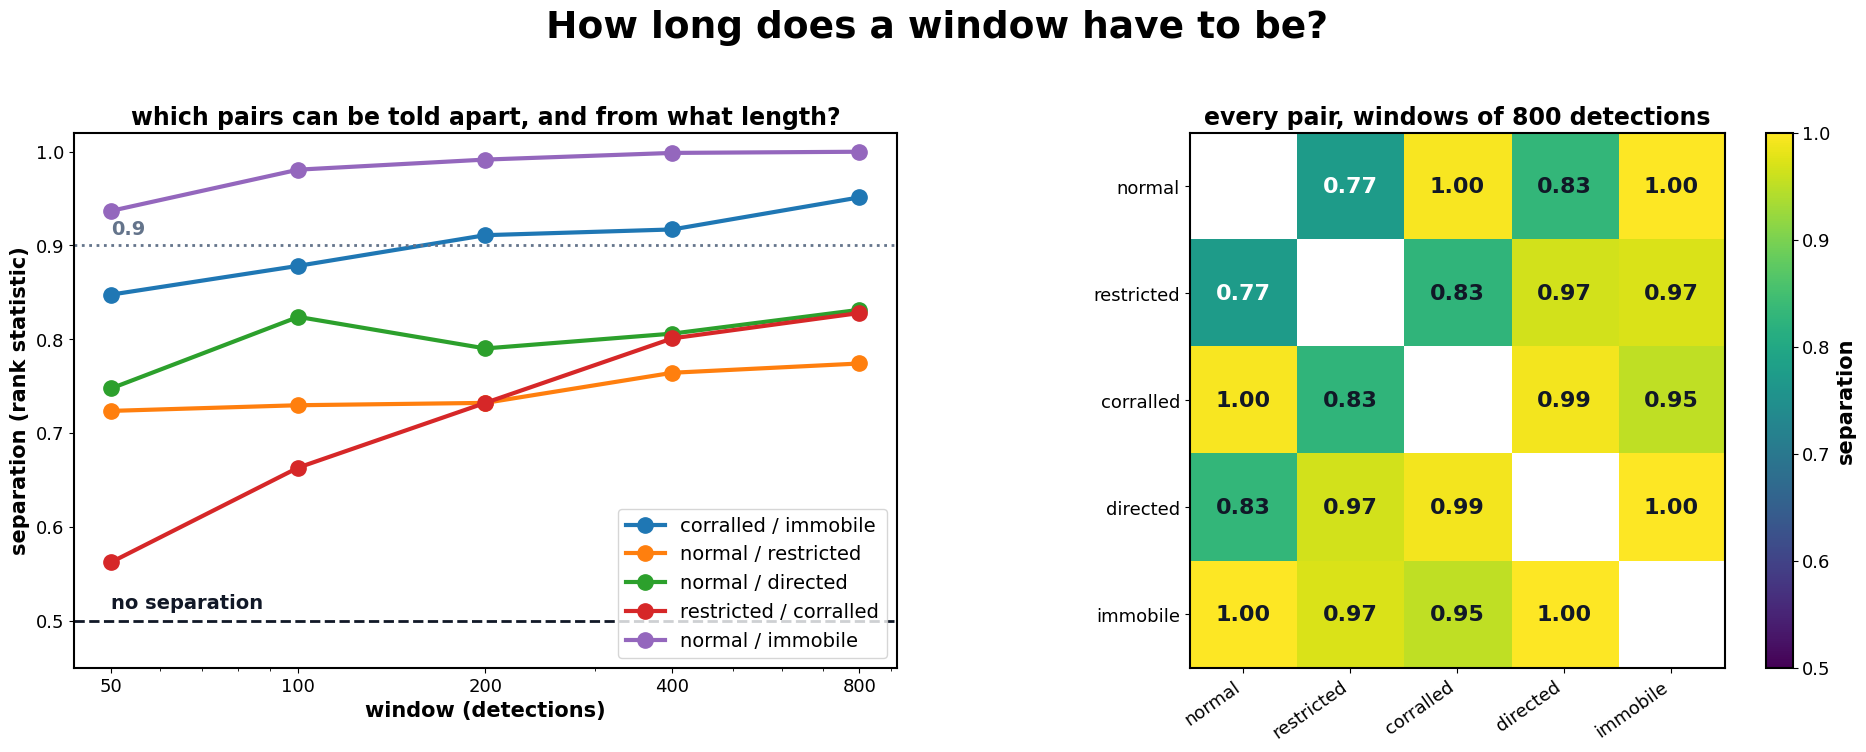

In [42]:
PAIRS_SHOW = [("corralled", "immobile"), ("normal", "restricted"),
              ("normal", "directed"), ("restricted", "corralled"),
              ("normal", "immobile")]
fig, axes = plt.subplots(1, 2, figsize=(19, 7.4))
x = SEPTAB["window asked"].to_numpy()

ax = axes[0]
for a, b in PAIRS_SHOW:
    y = [SEP[W].loc[a, b] for W in x]
    ax.plot(x, y, "o-", lw=3, ms=11, label=f"{a} / {b}")
ax.axhline(0.5, ls="--", lw=2, color="#111827")
ax.text(x[0], 0.513, "no separation", fontsize=14, fontweight="bold",
        color="#111827")
ax.axhline(0.9, ls=":", lw=2, color="#64748b")
ax.text(x[0], 0.912, "0.9", fontsize=14, color="#64748b", fontweight="bold")
ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels(x)
ax.set_xlabel("window (detections)")
ax.set_ylabel("separation (rank statistic)")
ax.set_ylim(0.45, 1.02)
ax.set_title("which pairs can be told apart, and from what length?",
             fontweight="bold")
ax.legend(fontsize=14, loc="lower right")

ax = axes[1]
Wb = int(x[-1])
M = SEP[Wb].to_numpy(float)
im = ax.imshow(np.where(np.isfinite(M), M, np.nan), cmap="viridis",
               vmin=0.5, vmax=1.0)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if np.isfinite(M[i, j]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                    fontsize=16, fontweight="bold",
                    color="white" if M[i, j] < 0.82 else "#111827")
ax.set_xticks(range(len(CLASSES))); ax.set_yticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=35, ha="right")
ax.set_yticklabels(CLASSES)
ax.set_title(f"every pair, windows of {Wb} detections", fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.045, label="separation")

fig.suptitle("How long does a window have to be?", fontsize=27,
             fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "S7_window_separability.png", bbox_inches="tight")

hard = SEPTAB.iloc[-1]
print()
print(f"At the longest window the hardest pair is {hard['hardest pair']} at "
      f"{hard['hardest value']:.2f}.")
print("A pair at 0.5 cannot be separated by any model; a pair near 1 will be")
print("separated by almost any model. This is a property of the data, not of a")
print("classifier - the features and the model are notebook 02's decisions.")

## 8b. The rolling window on tracks that actually switch

The ladder above uses windows of one pure motion. Real molecules change, so
the question that follows is what a rolling window does when the motion
changes underneath it.

Here I build tracks that switch motion type at known times, slide a window
along them, and measure the two numbers a rolling window lives or dies by:

- **switch lag** - how many frames after a real switch before the call follows
- **false switch rate** - how often the call flips when nothing happened

The call comes from transparent threshold rules read straight off the
equations - never climbs clear of 4\u03c3\u00b2 means immobile, steepening
and travelling far means directed, flattening means corralled, sublinear
without flattening means restricted, otherwise normal. **These are rules, not
a model.** They are the same rules I ran on my real FOV1 data, so the
simulated and real numbers are directly comparable, and a trained model in
notebook 02 should beat them.

A switch cannot be seen sooner than the window is long: until the window has
moved entirely past the switch, it contains both motions. So a lag of about
half a window is the floor, not a failure.

In [43]:
SWITCH_WIN = 300        # detections per rolling window
SWITCH_STEP = 25        # how far the window moves each time
DWELL_FRAMES = (200, 900)
N_SWITCH = 200


def path_switching(n, dt, rng, dwell=DWELL_FRAMES, kinds=None, vary=False):
    """A true path that changes motion type at random times.

    Each segment is generated by its own model, converted to steps, and the
    steps are concatenated - so the position is continuous at a switch and only
    the step statistics change, which is what a change of state is.
    """
    kinds = CLASSES if kinds is None else list(kinds)
    steps, state, i, last = [], np.empty(n, dtype=object), 0, None
    while i < n:
        k = kinds[int(rng.integers(len(kinds)))]
        while k == last and len(kinds) > 1:
            k = kinds[int(rng.integers(len(kinds)))]
        last = k
        L = min(int(rng.integers(*dwell)), n - i)
        if L < 2:
            state[i:] = k
            break
        p = draw_params(k, L, dt, rng, vary=vary)
        seg = PATH[k](L, dt, p, rng)
        steps.append(np.diff(seg, axis=0, prepend=seg[:1]))
        state[i:i + L] = k
        i += L
    return np.cumsum(np.concatenate(steps), axis=0)[:n], state[:n]


def call_from_stats(f):
    """The same rules as on my real data, read off the equations."""
    if not np.isfinite(f["clears"]) or f["clears"] < 1.5:
        return "immobile"
    if not np.isfinite(f["alpha"]):
        return "immobile"
    if f["alpha_long"] > 1.25 and f["directedness"] > 1.0:
        return "directed"
    if f["alpha_long"] < 0.45 and f["plateau"] < 1.5:
        return "corralled"
    if 0.3 < f["alpha"] < 0.85:
        return "restricted"
    return "normal"


_rng = np.random.default_rng(SEED + 909)
lags, flips = [], 0
pure_n = pure_ok = mixed_n = mixed_ok = 0
n_windows_total, example = 0, None
for t_i in tqdm(range(N_SWITCH), desc="switching tracks"):
    span = int(round(MOVIE_S / DT_S))
    true, state = path_switching(span, DT_S, _rng)
    sigma_t = float(_rng.choice(SIGMA))
    xy = true + _rng.normal(0, sigma_t, true.shape)
    fr = np.arange(span)

    centres, calls = [], []
    for a in range(0, span - SWITCH_WIN + 1, SWITCH_STEP):
        b = a + SWITCH_WIN
        calls.append(call_from_stats(
            stats_of_window(fr[a:b], xy[a:b], DT_S)))
        centres.append((a + b) // 2)
    if len(calls) < 3:
        continue
    calls = np.array(calls); centres = np.array(centres)
    n_windows_total += calls.size
    # a window that straddles a switch holds two motions, so it has no right
    # answer - score those separately instead of letting them set the number
    for i, a in enumerate(range(0, span - SWITCH_WIN + 1, SWITCH_STEP)):
        seg = state[a:a + SWITCH_WIN]
        if (seg == seg[0]).all():
            pure_n += 1
            pure_ok += int(calls[i] == seg[0])
        else:
            mixed_n += 1
            # for a straddling window, count it right if it names either motion
            mixed_ok += int(calls[i] in set(seg))

    # a switch in the truth, and how long the call takes to follow it
    tsw = np.flatnonzero(np.array([state[i] != state[i + 1]
                                   for i in range(span - 1)])) + 1
    for sw in tsw:
        after = centres >= sw
        if not after.any():
            continue
        want = state[min(sw + 5, span - 1)]
        hit = np.flatnonzero(after & (calls == want))
        if hit.size:
            lags.append(int(centres[hit[0]] - sw))
    # a flip in the call with no switch of the truth between the two centres
    for i in range(1, calls.size):
        if calls[i] != calls[i - 1]:
            lo, hi = centres[i - 1], centres[i]
            if (state[lo:hi] == state[lo]).all():
                flips += 1
    if example is None and len(set(state)) >= 3:
        example = (state.copy(), centres.copy(), calls.copy())

LAGS = np.array(lags, float)
SW = pd.DataFrame([{
    "window (detections)": SWITCH_WIN,
    "window (s)": SWITCH_WIN * DT_S,
    "step (frames)": SWITCH_STEP,
    "tracks": N_SWITCH,
    "windows": n_windows_total,
    "windows inside one state": pure_n / max(n_windows_total, 1),
    "right, windows inside one state": pure_ok / max(pure_n, 1),
    "names one of the two, straddling windows": mixed_ok / max(mixed_n, 1),
    "median switch lag (frames)": float(np.median(LAGS)) if LAGS.size else np.nan,
    "median switch lag (s)": float(np.median(LAGS) * DT_S) if LAGS.size else np.nan,
    "switches ever followed": LAGS.size,
    "false flips per 100 windows": 100 * flips / max(n_windows_total, 1),
}])
SW.to_csv(TAB_DIR / "rolling_window_switching.csv", index=False)
print(SW.T.to_string(header=False))

switching tracks:   0%|          | 0/200 [00:00<?, ?it/s]

window (detections)                         300.000000
window (s)                                    1.500000
step (frames)                                25.000000
tracks                                      200.000000
windows                                   45800.000000
windows inside one state                      0.484476
right, windows inside one state               0.512506
names one of the two, straddling windows      0.551988
median switch lag (frames)                  107.000000
median switch lag (s)                         0.535000
switches ever followed                     1758.000000
false flips per 100 windows                  11.709607



Median lag from a switch to the first window that names the new state: 0.54 s.
The window only contains the new motion ALONE after a full 1.5 s, so a call that
follows sooner is reading a window that still straddles the switch.

Of 45,800 windows, 48% lie inside a single state; 51% of those are named
correctly by the rules. The rest straddle a switch and have no single right answer - 55%
of them name one of the two motions present. A state shorter than the window cannot
be seen at all, which is the cost of a longer window and why section 8 matters.


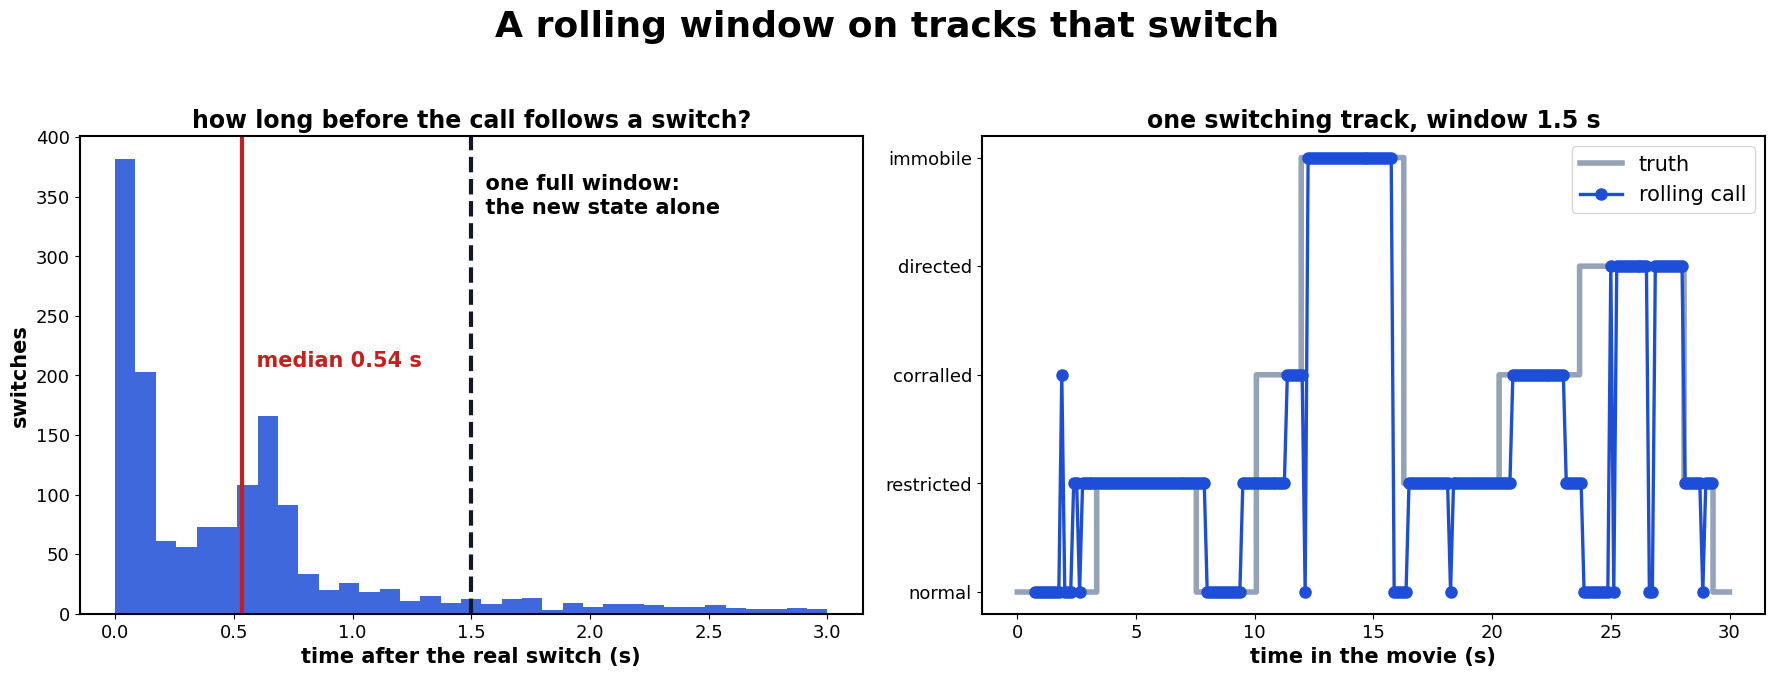

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6.6))

ax = axes[0]
if LAGS.size:
    ax.hist(LAGS * DT_S, bins=np.linspace(0, SWITCH_WIN * DT_S * 2, 36),
            color="#1d4ed8", alpha=.85)
    ax.axvline(SWITCH_WIN * DT_S, ls="--", lw=3, color="#111827")
    ax.text(SWITCH_WIN * DT_S, ax.get_ylim()[1] * .92,
            "  one full window:\n  the new state alone",
            fontsize=15, fontweight="bold", va="top")
    ax.axvline(float(np.median(LAGS)) * DT_S, lw=3, color="#c81e1e")
    ax.text(float(np.median(LAGS)) * DT_S, ax.get_ylim()[1] * .55,
            f"  median {np.median(LAGS)*DT_S:.2f} s", fontsize=15,
            fontweight="bold", color="#c81e1e", va="top")
ax.set_xlabel("time after the real switch (s)")
ax.set_ylabel("switches")
ax.set_title("how long before the call follows a switch?", fontweight="bold")

ax = axes[1]
if example is not None:
    state_e, centres_e, calls_e = example
    idx = {k: i for i, k in enumerate(CLASSES)}
    ax.step(np.arange(len(state_e)) * DT_S,
            [idx[k] for k in state_e], where="post", lw=4,
            color="#94a3b8", label="truth")
    ax.plot(centres_e * DT_S, [idx[k] for k in calls_e], "o-", lw=2.4, ms=8,
            color="#1d4ed8", label="rolling call")
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel("time in the movie (s)")
    ax.legend(fontsize=15, loc="upper right")
ax.set_title(f"one switching track, window {SWITCH_WIN*DT_S:.1f} s",
             fontweight="bold")

fig.suptitle("A rolling window on tracks that switch", fontsize=26,
             fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "S8_rolling_window.png", bbox_inches="tight")

print()
print(f"Median lag from a switch to the first window that names the new state: "
      f"{np.median(LAGS)*DT_S:.2f} s.\nThe window only contains the new motion "
      f"ALONE after a full {SWITCH_WIN*DT_S:.1f} s, so a call that\nfollows "
      f"sooner is reading a window that still straddles the switch.")
print()
print(f"Of {n_windows_total:,} windows, "
      f"{100*pure_n/max(n_windows_total,1):.0f}% lie inside a single state; "
      f"{100*pure_ok/max(pure_n,1):.0f}% of those are named\ncorrectly by the "
      f"rules. The rest straddle a switch and have no single right answer - "
      f"{100*mixed_ok/max(mixed_n,1):.0f}%\nof them name one of the two "
      f"motions present. A state shorter than the window cannot\nbe seen at "
      f"all, which is the cost of a longer window and why section 8 matters.")

## 9. What this produced, and what is not modelled

**Files**, in `ML/ML_Analysis/simulations/`:

- `sim_library_tracks.parquet` + labels — the training set, 5 classes × 9 band
  cells, spanning 5–100 ms and 10–6,000 detections
- `sim_reference_tracks.parquet` + labels — my own conditions, for comparison
  against my real data
- `sim_fixed_tracks.parquet` + labels — simulated fixed cells, the gate
- tables: measured parameters, the gate, the cutoff-error lookup, the seed
  spread, the motion-model and obstacle tests

**Three things declared as assumptions rather than measurements:** the
detection threshold (0.3–0.7 of a frame), the obstacle spacing (20–60 nm), and
holding localisation error constant across frame rates.

**Drift is now a property of the recording**, not of the molecule: every
simulated track belongs to a field, each field has one stage trajectory for
the whole movie, and the direction is drawn from my own measured per-field
angles rather than from a circle. That removes an approximation I previously
had to declare.

**Not modelled, on purpose.** Overlapping PSFs beyond the unresolved-pair
model — two molecules within 250 nm should merge into one detection and one
should vanish, which belongs in a field simulation where neighbours exist.
Fragmentation — the linker gives up after 19 dark frames, so one punctum can
become more than one track. Motion blur at slow frame rates. And realistic
class proportions: the library is balanced on purpose, where a cell is not.

**Next:** features. The same measurements on simulated, fixed and live tracks,
from the x, y and frame data alone.

**Interpretation guardrail:** simulation results are conditional on the chosen
motion models, parameter ranges, blinking donors, and artifact assumptions.
They estimate how the current cutoff behaves under these simulations; they are
not direct ground-truth labels or population estimates for live PIEZO1.

## 8c. All mixed-motion combinations (2, 3, 4, and 5 motion types)

This section extends the two-state switching test to every combination size. It enumerates all unordered class sets of sizes 2–5 (10 pairs, 10 triples, 5 quadruples, and 1 five-class set). For each set, it simulates tracks with successive motion segments and applies overlapping rolling windows. The ground-truth label for a window is the set of motion types occupying at least 20% of its detections; windows crossing transitions are therefore explicitly treated as mixed, not forced into a single class.

The existing motion generators, parameter distributions, frame interval, and experimental-effects pipeline remain the source of scientific assumptions. This is a simulation/analysis diagnostic, not a trained PiMoTIF classifier. Ordered transition sequences are randomized across replicates; this avoids implying that one transition order is uniquely representative.


all mixed-motion combinations:   0%|          | 0/26 [00:00<?, ?it/s]

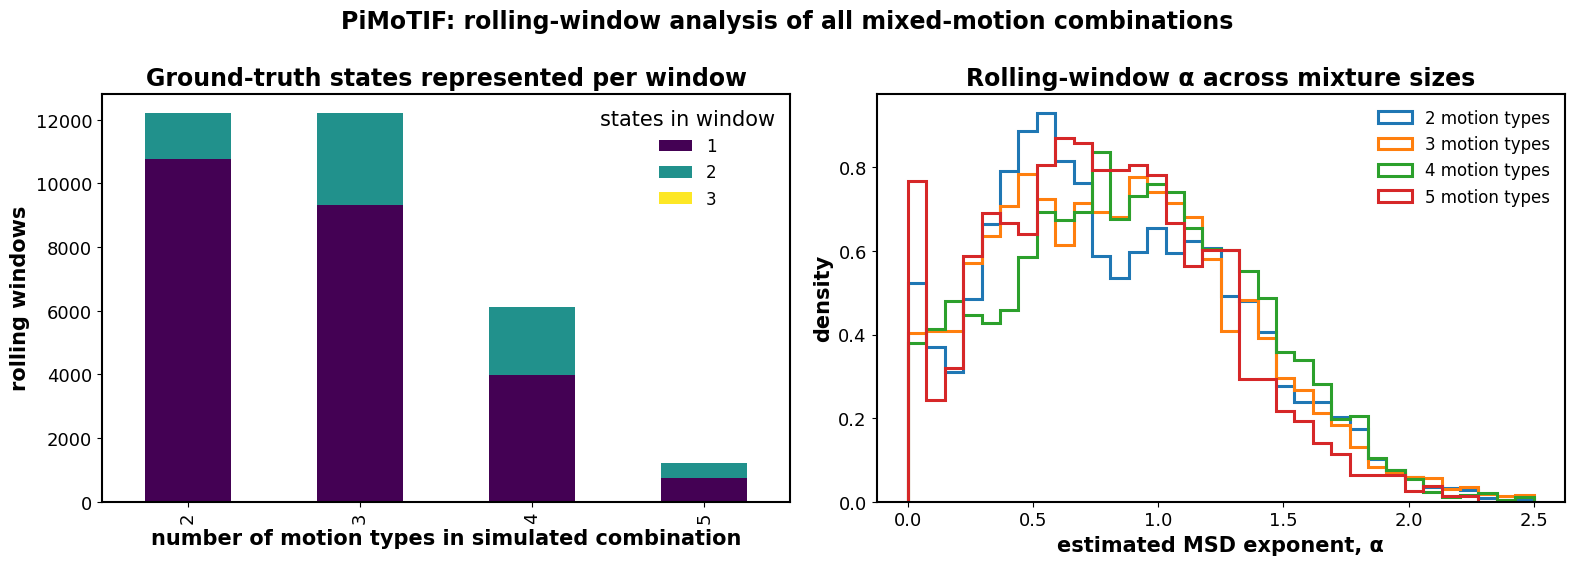

Class sets evaluated: 26 (10 pairs, 10 triples, 5 quadruples, 1 five-class set)
Rolling windows: 31,720
Saved: Z:\Lab\Jagriti\DATA_EXTRACTED\ALL_FOVS\ML\ML_Analysis\simulations\tables\all_motion_combinations_rolling_windows.csv
Saved: Z:\Lab\Jagriti\DATA_EXTRACTED\ALL_FOVS\ML\ML_Analysis\simulations\tables\all_motion_combinations_summary.csv
Saved: Z:\Lab\Jagriti\DATA_EXTRACTED\ALL_FOVS\ML\ML_Analysis\simulations\figures\S9_all_motion_combinations_rolling_windows.png


In [45]:
from itertools import combinations

# All class-set combinations: C(5,2)+C(5,3)+C(5,4)+C(5,5) = 26.
MIXED_SIZES = (2, 3, 4, 5)
MIXED_REPS_PER_SET = 20
MIXED_TRACK_FRAMES = 1800
MIXED_WINDOW = 300       # detections requested per window
MIXED_STEP = 25          # rolling step, in frames
MIXED_DWELL = (250, 650) # segment duration in frames
MIXED_MIN_FRACTION = 0.20 # state is represented in a window if >=20% of frames


def path_for_ordered_mixture(order, n_frames, dt, rng, dwell=MIXED_DWELL):
    """Concatenate existing PATH generators while preserving position continuity.

    Each segment uses draw_params()/PATH from the original notebook. Segment
    displacement increments are concatenated, so the position does not jump
    artificially at a motion-state transition.
    """
    step_parts, state_parts = [], []
    remaining = int(n_frames)
    # Allocate approximately equal dwell to each state, with bounded variation.
    for j, kind in enumerate(order):
        left = len(order) - j - 1
        if left == 0:
            length = remaining
        else:
            lo = min(dwell[0], max(2, remaining // (left + 1)))
            hi = min(dwell[1], max(lo + 1, remaining - 2 * left))
            length = int(rng.integers(lo, hi + 1)) if hi > lo else lo
        length = max(2, min(length, remaining - 2 * left))
        params = draw_params(kind, length, dt, rng, vary=True)
        segment = PATH[kind](length, dt, params, rng)
        steps = np.diff(segment, axis=0, prepend=segment[:1])
        step_parts.append(steps)
        state_parts.append(np.full(length, kind, dtype=object))
        remaining -= length
        if remaining <= 0:
            break
    if remaining > 0:
        kind = order[-1]
        params = draw_params(kind, remaining, dt, rng, vary=True)
        segment = PATH[kind](remaining, dt, params, rng)
        step_parts.append(np.diff(segment, axis=0, prepend=segment[:1]))
        state_parts.append(np.full(remaining, kind, dtype=object))
    steps = np.concatenate(step_parts, axis=0)[:n_frames]
    truth = np.concatenate(state_parts)[:n_frames]
    return np.cumsum(steps, axis=0), truth


def window_truth_set(state, start, stop, min_fraction=MIXED_MIN_FRACTION):
    """Return all states contributing at least min_fraction of a window."""
    vals, counts = np.unique(state[start:stop], return_counts=True)
    frac = counts / max(1, counts.sum())
    chosen = tuple(sorted(str(v) for v, f in zip(vals, frac) if f >= min_fraction))
    # Always retain the dominant state if a very short segment falls below threshold.
    if not chosen and len(vals):
        chosen = (str(vals[int(np.argmax(counts))]),)
    return chosen


_rng_mix = np.random.default_rng(SEED + 42026)
mix_rows = []
all_sets = [comb for size in MIXED_SIZES for comb in combinations(CLASSES, size)]

for combo in tqdm(all_sets, desc="all mixed-motion combinations"):
    for rep in range(MIXED_REPS_PER_SET):
        order = list(combo)
        _rng_mix.shuffle(order)
        # Ensure each class is represented in the simulated sequence.
        true_xy, truth = path_for_ordered_mixture(
            order, MIXED_TRACK_FRAMES, DT_S, _rng_mix)
        # stats_of_window subtracts the camera's 4*sigma^2 from the MSD, so the
        # track has to have been through a camera first. Subtracting a floor
        # that was never added biases alpha low and leaves `clears` unbounded.
        sigma_track = float(_rng_mix.choice(SIGMA))
        xy = true_xy + _rng_mix.normal(0, sigma_track, true_xy.shape)
        # Use the same measurement statistic as the existing rolling-window analysis.
        for start in range(0, len(truth) - MIXED_WINDOW + 1, MIXED_STEP):
            stop = start + MIXED_WINDOW
            win_truth = window_truth_set(truth, start, stop)
            fr = np.arange(start, stop, dtype=int)
            feat = stats_of_window(fr, xy[start:stop], DT_S)
            mix_rows.append({
                "combination_size": len(combo),
                "combination": "+".join(combo),
                "segment_order": "->".join(order),
                "replicate": rep,
                "window_start_frame": start,
                "window_end_frame": stop - 1,
                "window_start_s": start * DT_S,
                "truth_states_in_window": "+".join(win_truth),
                "n_truth_states": len(win_truth),
                "is_mixed_window": len(win_truth) > 1,
                "sigma_um": sigma_track,
                **feat,
            })

MIXED_WINDOW_TAB = pd.DataFrame(mix_rows)
MIXED_WINDOW_TAB.to_csv(TAB_DIR / "all_motion_combinations_rolling_windows.csv", index=False)

# Summarize coverage and motion-state composition without pretending a rule-based
# diagnostic is the trained classifier.
MIXED_SUMMARY = (MIXED_WINDOW_TAB.groupby(
    ["combination_size", "combination", "n_truth_states"], dropna=False)
    .agg(n_windows=("replicate", "size"),
         median_Rg_um=("Rg", "median"),
         median_alpha=("alpha", "median"),
         median_directedness=("directedness", "median"),
         mixed_window_fraction=("is_mixed_window", "mean"))
    .reset_index())
MIXED_SUMMARY.to_csv(TAB_DIR / "all_motion_combinations_summary.csv", index=False)

# Visualization 1: how many rolling windows contain one vs multiple true states.
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
counts = (MIXED_WINDOW_TAB.groupby(["combination_size", "n_truth_states"])
          .size().unstack(fill_value=0))
counts.plot(kind="bar", stacked=True, ax=axes[0], colormap="viridis")
axes[0].set_xlabel("number of motion types in simulated combination")
axes[0].set_ylabel("rolling windows")
axes[0].set_title("Ground-truth states represented per window")
axes[0].legend(title="states in window", frameon=False)

# Visualization 2: representative window-level feature distribution by combination size.
for size in MIXED_SIZES:
    vals = MIXED_WINDOW_TAB.loc[
        (MIXED_WINDOW_TAB.combination_size == size) &
        np.isfinite(MIXED_WINDOW_TAB.alpha), "alpha"].to_numpy()
    if len(vals):
        axes[1].hist(vals, bins=np.linspace(0, 2.5, 35), density=True,
                     histtype="step", lw=2.2, label=f"{size} motion types")
axes[1].set_xlabel("estimated MSD exponent, α")
axes[1].set_ylabel("density")
axes[1].set_title("Rolling-window α across mixture sizes")
axes[1].legend(frameon=False)
fig.suptitle("PiMoTIF: rolling-window analysis of all mixed-motion combinations",
             fontsize=17, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "S9_all_motion_combinations_rolling_windows.png",
            dpi=250, bbox_inches="tight")
plt.show()

print(f"Class sets evaluated: {len(all_sets)} (10 pairs, 10 triples, 5 quadruples, 1 five-class set)")
print(f"Rolling windows: {len(MIXED_WINDOW_TAB):,}")
print(f"Saved: {TAB_DIR / 'all_motion_combinations_rolling_windows.csv'}")
print(f"Saved: {TAB_DIR / 'all_motion_combinations_summary.csv'}")
print(f"Saved: {FIG_DIR / 'S9_all_motion_combinations_rolling_windows.png'}")


### What the mixed-motion generator makes

Before any number from section 8c is believed, three things are worth seeing: the tracks themselves coloured by their true state, how long each state lasts, and what a mixed track's MSD looks like next to the five pure ones.

The third panel is the reason this section exists. A molecule switching between states has MSD → 4·D_eff·τ at long lags, with D_eff the time-weighted average of the states it passed through. So fitting a whole mixed track returns an ordinary normal-diffusion answer — a sensible D and an α near 1 — for a molecule that was never doing normal diffusion. That is exactly what a rolling window is for.

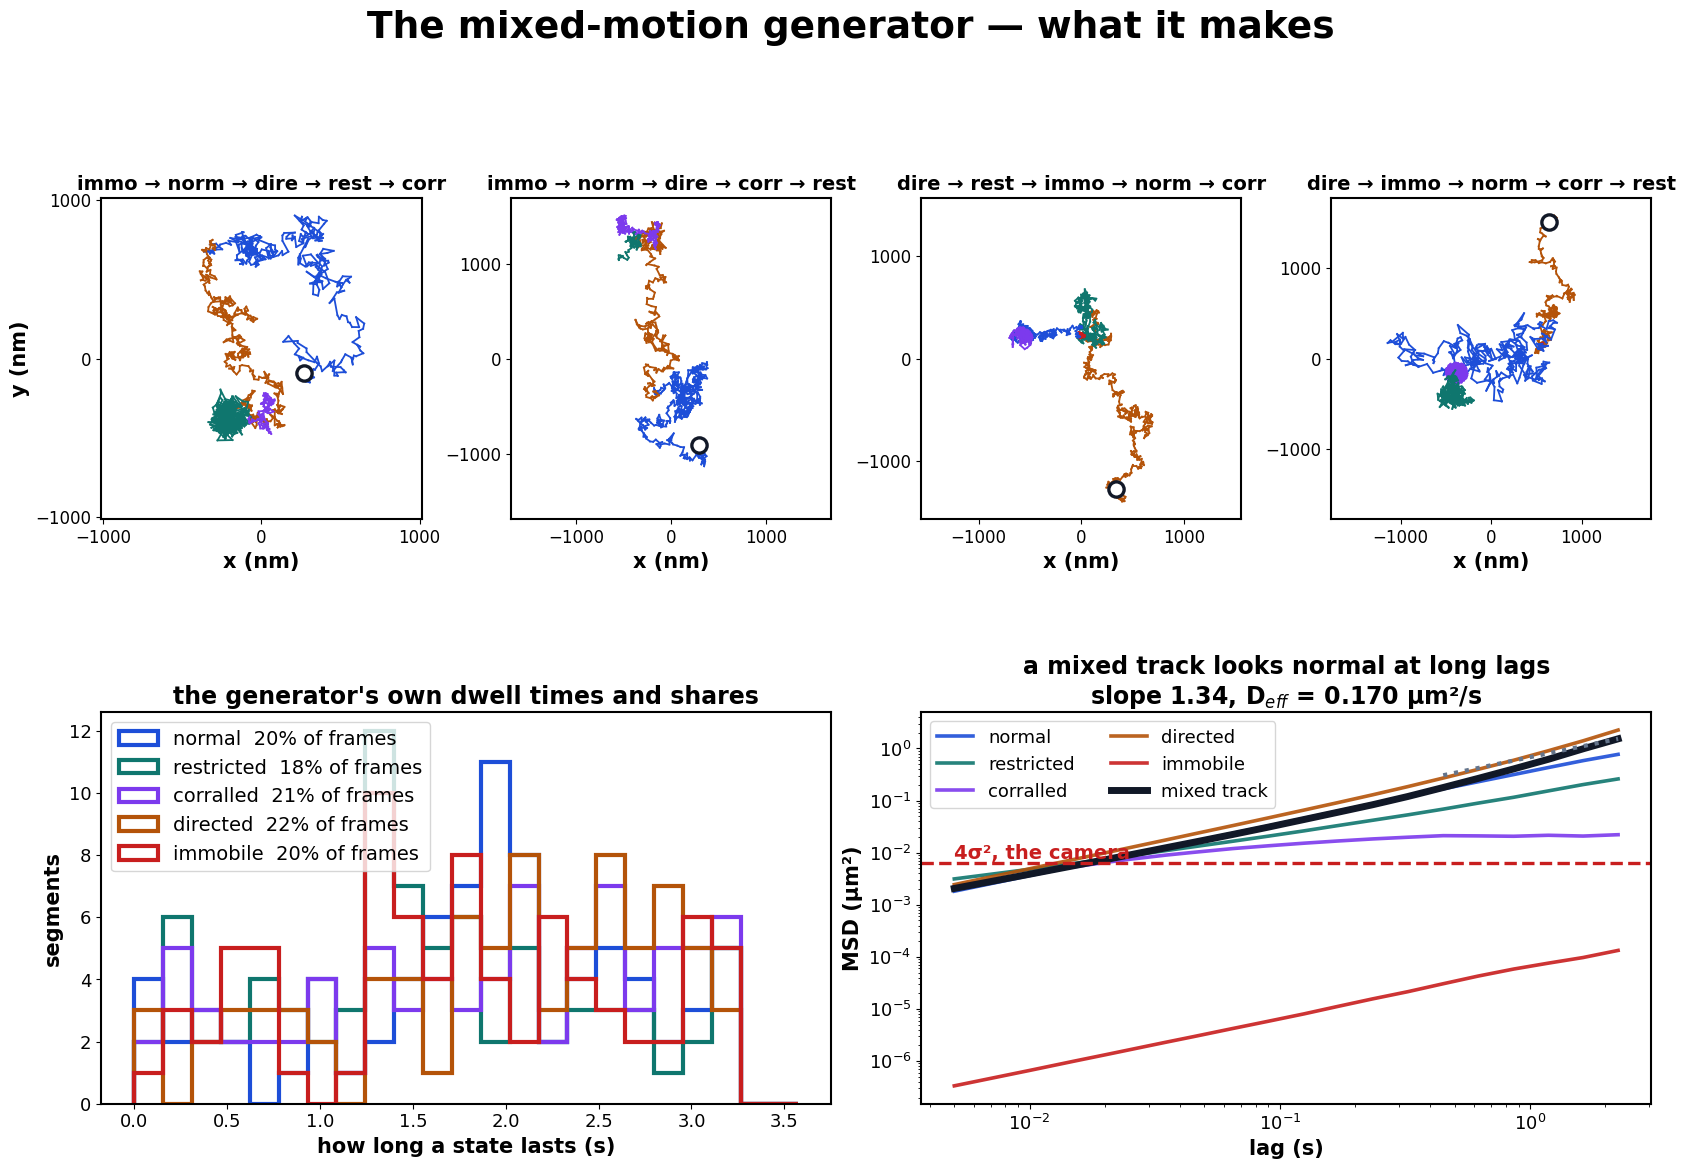

the mixed-motion generator
   400 segments over 80 tracks, median 1.85 s each
   share of frames: normal 20%, restricted 18%, corralled 21%, directed 22%, immobile 20%
   a mixed track's MSD has slope 1.34 at long lags (normal diffusion is 1.00)
   and gives D_eff = 0.170 um2/s against a pool median of 0.118
   So a whole-track fit returns a respectable normal-diffusion answer
   for a molecule that was never doing normal diffusion. That is the
   case for a rolling window, in one number.


In [46]:
# --- what the mixed-motion generator makes ----------------------------------
_grng = np.random.default_rng(SEED + 4242)

# four example tracks, each passing through all five motion types
gallery = []
for _ in range(4):
    order = list(CLASSES)
    _grng.shuffle(order)
    tr_, st_ = path_for_ordered_mixture(order, MIXED_TRACK_FRAMES, DT_S, _grng)
    gallery.append((tr_, st_, order))

# how long the states last, and how the frames divide between them
runs, share = [], {k: 0 for k in CLASSES}
for _ in range(80):
    order = list(CLASSES)
    _grng.shuffle(order)
    _, st_ = path_for_ordered_mixture(order, MIXED_TRACK_FRAMES, DT_S, _grng)
    i = 0
    while i < len(st_):
        j = i
        while j < len(st_) and st_[j] == st_[i]:
            j += 1
        runs.append((st_[i], j - i))
        share[st_[i]] += j - i
        i = j
RUNS = pd.DataFrame(runs, columns=["state", "frames"])
RUNS["seconds"] = RUNS.frames * DT_S
tot = sum(share.values())


def _mean_msd(paths, lags):
    """Ensemble mean of the time-averaged MSD, on true paths (no camera)."""
    out = np.zeros(lags.size)
    for Pp in paths:
        out += np.array([((Pp[k:] - Pp[:-k]) ** 2).sum(1).mean() for k in lags])
    return out / len(paths)


LAG_G = np.unique(np.round(np.logspace(
    0, np.log10(MIXED_TRACK_FRAMES // 4), 20)).astype(int))
mixed_paths = []
for _ in range(30):
    order = list(CLASSES)
    _grng.shuffle(order)
    mixed_paths.append(
        path_for_ordered_mixture(order, MIXED_TRACK_FRAMES, DT_S, _grng)[0])
MSD_MIX = _mean_msd(mixed_paths, LAG_G)
MSD_PURE = {}
for k in CLASSES:
    ps = []
    for _ in range(30):
        p_ = draw_params(k, MIXED_TRACK_FRAMES, DT_S, _grng, vary=False)
        ps.append(PATH[k](MIXED_TRACK_FRAMES, DT_S, p_, _grng))
    MSD_PURE[k] = _mean_msd(ps, LAG_G)

tt = LAG_G * DT_S
late = LAG_G >= LAG_G.max() / 6
slope_mix = float(np.polyfit(np.log(tt[late]), np.log(MSD_MIX[late]), 1)[0])
D_eff = float(MSD_MIX[late][-1] / (4 * tt[late][-1]))

fig = plt.figure(figsize=(20, 12.5))
gs = fig.add_gridspec(2, 4, height_ratios=[1.0, 0.9], hspace=0.33, wspace=0.28)

for j, (tr_, st_, order) in enumerate(gallery):
    ax = fig.add_subplot(gs[0, j])
    C = 1000 * (tr_ - tr_.mean(0))
    for i in range(len(C) - 1):
        ax.plot(C[i:i + 2, 0], C[i:i + 2, 1], lw=1.3, color=COL[st_[i]])
    ax.plot(C[0, 0], C[0, 1], "o", ms=11, mfc="white", mec="#111827", mew=2.4)
    m = np.abs(C).max() * 1.12
    ax.set_xlim(-m, m); ax.set_ylim(-m, m)
    ax.set_aspect("equal")
    ax.set_xlabel("x (nm)")
    ax.set_ylabel("y (nm)" if j == 0 else "")
    ax.xaxis.set_major_locator(MaxNLocator(3, integer=True, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_locator(MaxNLocator(3, integer=True, steps=[1, 2, 5, 10]))
    ax.tick_params(labelsize=12)
    ax.set_title(" \u2192 ".join(o[:4] for o in order), fontsize=14,
                 fontweight="bold")

ax = fig.add_subplot(gs[1, 0:2])
for k in CLASSES:
    v = RUNS.loc[RUNS.state == k, "seconds"]
    if len(v):
        ax.hist(v, bins=np.linspace(0, MIXED_DWELL[1] * DT_S * 1.1, 24),
                histtype="step", lw=3, color=COL[k],
                label=f"{k}  {100*share[k]/tot:.0f}% of frames")
ax.set_xlabel("how long a state lasts (s)")
ax.set_ylabel("segments")
ax.set_title("the generator's own dwell times and shares", fontweight="bold")
ax.legend(fontsize=14)

ax = fig.add_subplot(gs[1, 2:4])
for k in CLASSES:
    ax.plot(tt, MSD_PURE[k], lw=2.6, color=COL[k], alpha=.9, label=k)
ax.plot(tt, MSD_MIX, lw=5, color="#111827", label="mixed track")
ax.plot(tt[late], 4 * D_eff * tt[late], ls=":", lw=3, color="#64748b")
ax.axhline(noise, ls="--", lw=2.4, color="#c81e1e")
ax.text(tt[0], noise * 1.2, "4\u03c3\u00b2, the camera", fontsize=14,
        color="#c81e1e", fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag (s)"); ax.set_ylabel("MSD (\u00b5m\u00b2)")
ax.set_title(f"a mixed track looks normal at long lags\n"
             f"slope {slope_mix:.2f}, D$_{{eff}}$ = {D_eff:.3f} "
             f"\u00b5m\u00b2/s", fontweight="bold")
ax.legend(fontsize=13, ncol=2, loc="upper left")

fig.suptitle("The mixed-motion generator \u2014 what it makes", fontsize=27,
             fontweight="bold", y=0.985)
fig.savefig(FIG_DIR / "S9b_mixed_motion_examples.png", bbox_inches="tight")
plt.show()

RUNS.to_csv(TAB_DIR / "mixed_generator_dwells.csv", index=False)
print("the mixed-motion generator")
print(f"   {len(RUNS)} segments over 80 tracks, "
      f"median {RUNS.seconds.median():.2f} s each")
print("   share of frames: "
      + ", ".join(f"{k} {100*share[k]/tot:.0f}%" for k in CLASSES))
print(f"   a mixed track's MSD has slope {slope_mix:.2f} at long lags "
      f"(normal diffusion is 1.00)")
print(f"   and gives D_eff = {D_eff:.3f} um2/s against a pool median of "
      f"{np.median(D_POOL):.3f}")
print("   So a whole-track fit returns a respectable normal-diffusion answer")
print("   for a molecule that was never doing normal diffusion. That is the")
print("   case for a rolling window, in one number.")


### One slide: the five motions, their MSDs, and a mixture

Everything the simulation has to say, on one page, at 16:9 so it drops onto a slide without resizing. The five pure types at stated values across the top, their MSD equations down the left, and on the right one track that passes through all five together with the MSD it produces.

The right-hand pair carries the argument: a mixed track's MSD sits on top of the pure diffusive ones, so fitting a whole track returns a respectable diffusion answer for a molecule that was immobile a fifth of the time and corralled another fifth.

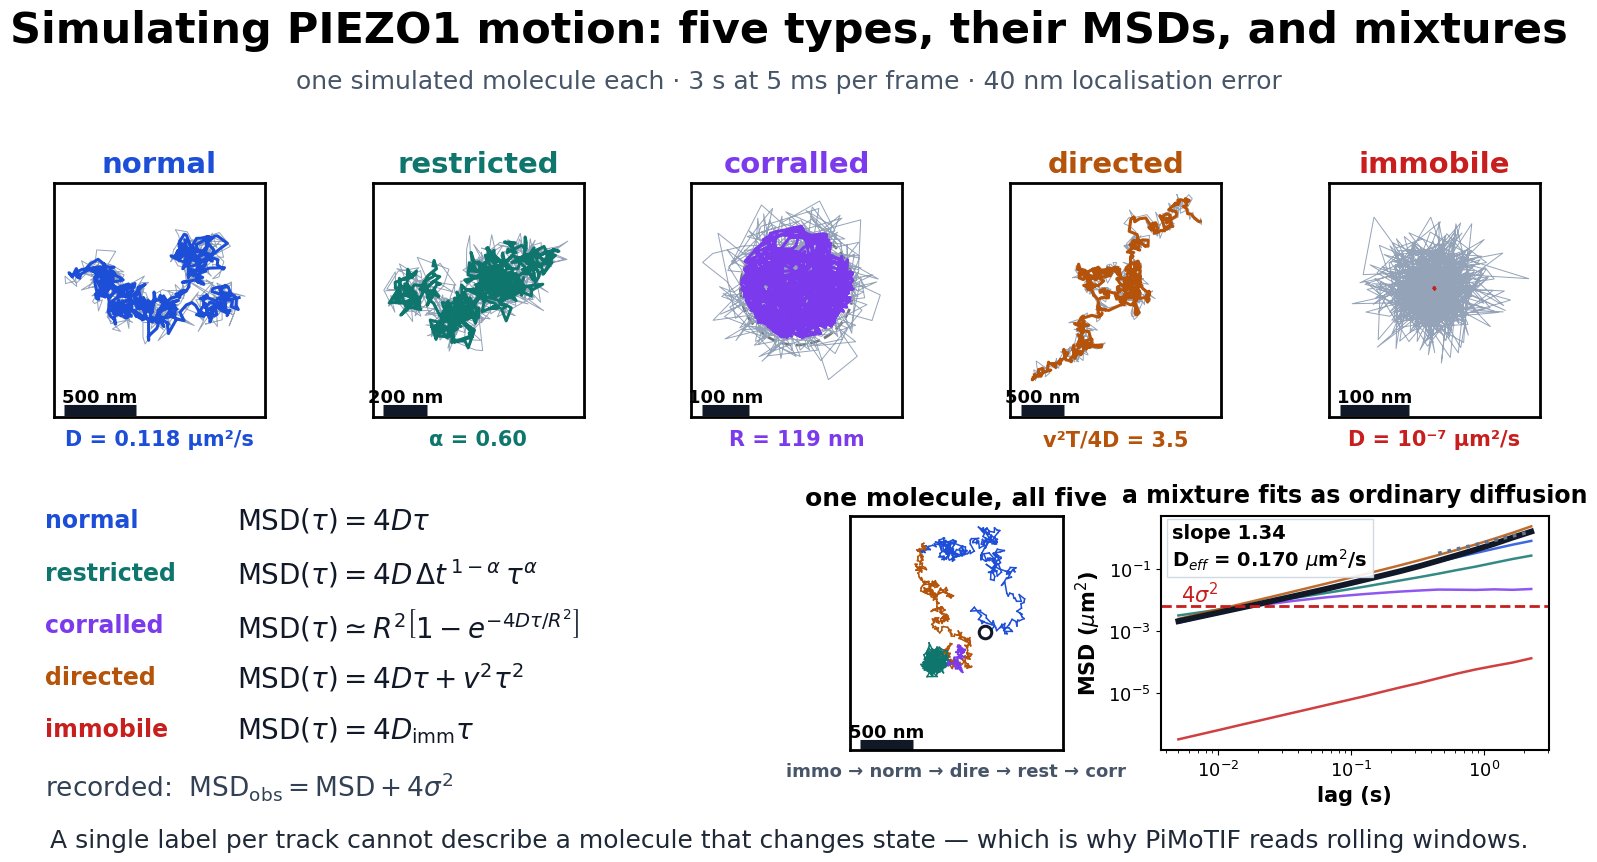

wrote Z:\Lab\Jagriti\DATA_EXTRACTED\ALL_FOVS\ML\ML_Analysis\simulations\figures\V_slide_summary.png


In [47]:
# --- one slide: motions, equations, and a mixture ---------------------------
fig = plt.figure(figsize=(16, 9), facecolor="white")
gs = fig.add_gridspec(2, 10, height_ratios=[1.0, 1.0], top=0.775,
                      bottom=0.145, left=0.035, right=0.975,
                      hspace=0.42, wspace=1.3)

fig.text(0.5, 0.945, "Simulating PIEZO1 motion: five types, their MSDs, "
         "and mixtures", ha="center", va="center", fontsize=31,
         fontweight="bold")
fig.text(0.5, 0.888, "one simulated molecule each \u00b7 3 s at 5 ms per frame "
         "\u00b7 40 nm localisation error", ha="center", va="center",
         fontsize=18, color="#475569")

# --- top row: the five pure types ------------------------------------------
for j, k in enumerate(CLASSES):
    T, O, p = show[k]
    ax = fig.add_subplot(gs[0, 2 * j:2 * j + 2])
    reach = 1000 * np.abs(O).max()
    if k == "corralled":
        reach = max(reach, 1000 * p["R"] * 1.1)
    m = reach * 1.12
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=2, color="#111827", alpha=.6, zorder=2)
    ax.plot(1000 * O[:, 0], 1000 * O[:, 1], lw=0.7, color="#94a3b8", zorder=2)
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=2.2, color=COL[k],
            solid_joinstyle="round", zorder=3)
    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.22, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.0)
    _bar(ax, m, frac=0.28, fs=13)
    ax.set_title(k, fontsize=21, fontweight="bold", color=COL[k], pad=8)
    ax.text(0.5, -0.05, SHOW_VALUE[k], transform=ax.transAxes, ha="center",
            va="top", fontsize=15, fontweight="bold", color=COL[k])

# --- bottom left: the equations --------------------------------------------
y = 0.400
for k in CLASSES:
    fig.text(0.035, y, k, fontsize=17, fontweight="bold", color=COL[k],
             va="center")
    fig.text(0.155, y, EQN[k], fontsize=20, color="#111827", va="center")
    y -= 0.058
fig.text(0.035, y - 0.004,
         r"recorded:  $\mathrm{MSD}_{\mathrm{obs}}=\mathrm{MSD}+4\sigma^{2}$",
         fontsize=19, color="#334155", va="center")

# --- bottom middle: one track through all five ------------------------------
tr_m, st_m, order_m = gallery[0]
ax = fig.add_subplot(gs[1, 5:7])
C = 1000 * (tr_m - tr_m.mean(0))
for i in range(len(C) - 1):
    ax.plot(C[i:i + 2, 0], C[i:i + 2, 1], lw=1.1, color=COL[st_m[i]])
ax.plot(C[0, 0], C[0, 1], "o", ms=9, mfc="white", mec="#111827", mew=2.2)
mm = np.abs(C).max() * 1.12
ax.set_xlim(-mm, mm); ax.set_ylim(-mm * 1.2, mm)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
for sp in ax.spines.values():
    sp.set_linewidth(2.0)
_bar(ax, mm, frac=0.3, fs=13)
ax.set_title("one molecule, all five", fontsize=18, fontweight="bold", pad=8)
ax.text(0.5, -0.05, " \u2192 ".join(o[:4] for o in order_m),
        transform=ax.transAxes, ha="center", va="top", fontsize=13,
        color="#475569", fontweight="bold")

# --- bottom right: what that mixture does to the MSD ------------------------
ax = fig.add_subplot(gs[1, 7:10])
for k in CLASSES:
    ax.plot(tt, MSD_PURE[k], lw=1.8, color=COL[k], alpha=.85)
ax.plot(tt, MSD_MIX, lw=4.2, color="#111827", label="mixed")
ax.plot(tt[late], 4 * D_eff * tt[late], ls=":", lw=2.6, color="#64748b")
ax.axhline(noise, ls="--", lw=2, color="#c81e1e")
ax.text(tt[0] * 1.05, noise * 1.3, r"$4\sigma^{2}$", fontsize=15,
        color="#c81e1e", fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag (s)", fontsize=15)
ax.set_ylabel(r"MSD ($\mu$m$^2$)", fontsize=15)
ax.tick_params(labelsize=13)
ax.set_title("a mixture fits as ordinary diffusion", fontsize=17,
             fontweight="bold", pad=10)
ax.text(0.03, 0.97, f"slope {slope_mix:.2f}\nD$_{{eff}}$ = {D_eff:.3f} "
        r"$\mu$m$^2$/s", transform=ax.transAxes, va="top", ha="left",
        fontsize=14, fontweight="bold",
        bbox=dict(fc="white", ec="#cbd5e1", alpha=.9, pad=4))

fig.text(0.5, 0.045, "A single label per track cannot describe a molecule that "
         "changes state \u2014 which is why PiMoTIF reads rolling windows.",
         ha="center", va="center", fontsize=18, color="#1f2937")

fig.savefig(FIG_DIR / "V_slide_summary.png", dpi=200, facecolor="white",
            bbox_inches="tight")
plt.show()
print("wrote", FIG_DIR / "V_slide_summary.png")
